# Ice-Maker: прогнозування попиту

Продажі подрібнювача льоду на Amazon (2017–2020). Ноутбук складається з трьох частин: EDA та очищення даних (розділ 1), схема валідації (розділ 2) і базові моделі з метриками (розділ 3). Спочатку розглядаємо кожен файл окремо, потім збираємо їх в один датасет для моделювання.

# 1. EDA and preprocessing

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from IPython.display import display

## 1.1 Orders data

In [2]:
plt.rcParams.update({
    "figure.figsize": (12, 5),
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "font.size": 10,
})

orders = pd.read_excel("orders.xlsx")

orders = orders.loc[:, ~orders.columns.str.contains("^Unnamed")]

orders["date"] = pd.to_datetime(orders["date"])
orders["month"] = pd.to_datetime(orders["month"])

orders.head()

,month,code,count,lat,long,date,city,warehouse_zip
0,2017-06-01,13658,2,44.70,-75.30,2017-06-28,"Lisbon, St. Lawrence County",12189
1,2017-06-01,48456,2,43.70,-82.70,2017-06-28,"Minden City, Sanilac County",46168
2,2017-06-01,50323,2,41.64,-93.81,2017-06-28,"Urbandale, Dallas County",46168
3,2017-06-01,60614,2,41.92,-87.65,2017-06-28,"Chicago, Cook County",46168
4,2017-06-01,85395,2,33.48,-112.40,2017-06-28,"Goodyear, Maricopa County",91761


In [3]:
overview = pd.DataFrame({
    "Metric": [
        "Number of rows",
        "Number of columns",
        "Date from",
        "Date to",
        "Unique dates",
        "Unique locations (code)",
        "Unique cities",
        "Unique warehouses",
        "Total quantity",
    ],
    "Value": [
        f"{len(orders):,}",
        len(orders.columns),
        orders["date"].min().strftime("%Y-%m-%d"),
        orders["date"].max().strftime("%Y-%m-%d"),
        orders["date"].nunique(),
        f"{orders['code'].nunique():,}",
        f"{orders['city'].nunique():,}",
        orders["warehouse_zip"].nunique(),
        f"{orders['count'].sum():,}",
    ]
})

display(
    overview.style
    .hide(axis="index")
    .set_properties(**{"text-align": "left", "padding": "8px"})
    .set_table_styles([
        {"selector": "th", "props": [
            ("background-color", "#040D17"),
            ("font-weight", "bold"),
            ("text-align", "left")
        ]}
    ])
)

Metric,Value
Number of rows,"89,934"
Number of columns,8
Date from,2017-06-28
Date to,2020-01-06
Unique dates,840
Unique locations (code),"18,241"
Unique cities,"13,339"
Unique warehouses,7
Total quantity,"146,680"


In [4]:
quality = pd.DataFrame({
    "Data Type": orders.dtypes.astype(str),
    "Missing Values": orders.isna().sum(),
    "Missing (%)": (orders.isna().mean() * 100).round(2),
    "Unique Values": orders.nunique()
})

display(quality.style
    .background_gradient(subset=["Missing (%)"], cmap="YlOrRd")
    .format({"Missing (%)": "{:.2f}%"}))

print(f"Duplicate rows: {orders.duplicated().sum():,}")
print(f"Negative quantities: {(orders['count'] < 0).sum():,}")
print(f"Zero quantities: {(orders['count'] == 0).sum():,}")

,Data Type,Missing Values,Missing (%),Unique Values
month,datetime64[us],0,0.00%,32
code,int64,0,0.00%,18241
count,int64,0,0.00%,9
lat,float64,845,0.94%,2284
long,float64,845,0.94%,3825
date,datetime64[us],0,0.00%,840
city,str,0,0.00%,13339
warehouse_zip,int64,0,0.00%,7


Duplicate rows: 0
Negative quantities: 0
Zero quantities: 0


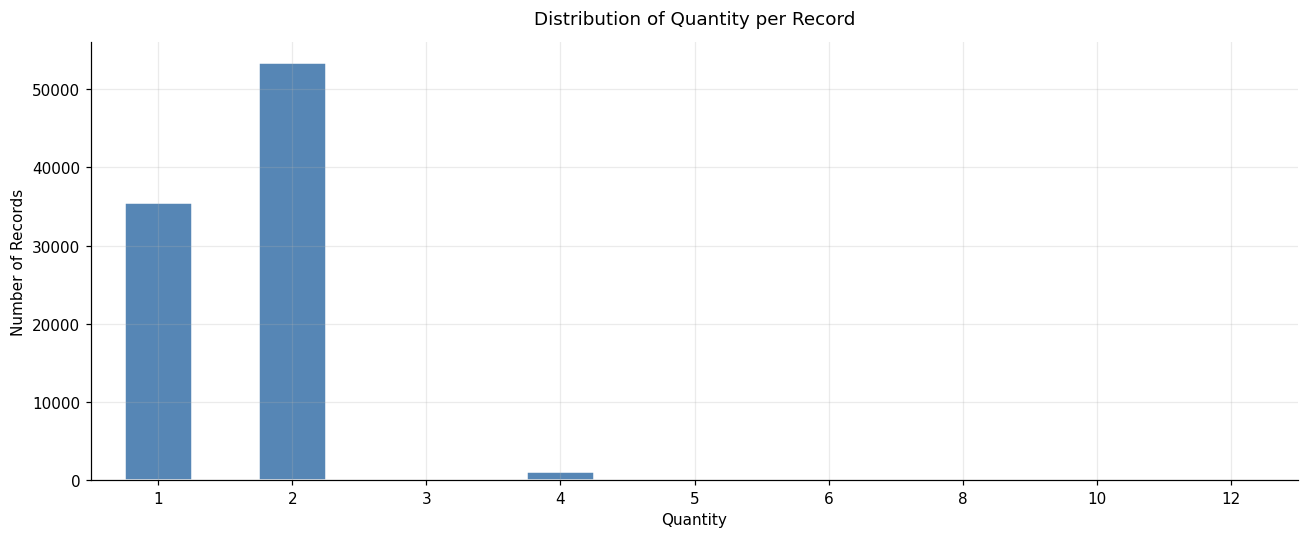

In [5]:
orders["count"].value_counts().sort_index().plot(
    kind="bar",
    color="#5686B5",
    edgecolor="white"
)

plt.title("Distribution of Quantity per Record", pad=12)
plt.xlabel("Quantity")
plt.ylabel("Number of Records")
plt.tick_params(axis="x", rotation=0)


plt.tight_layout()
plt.show()

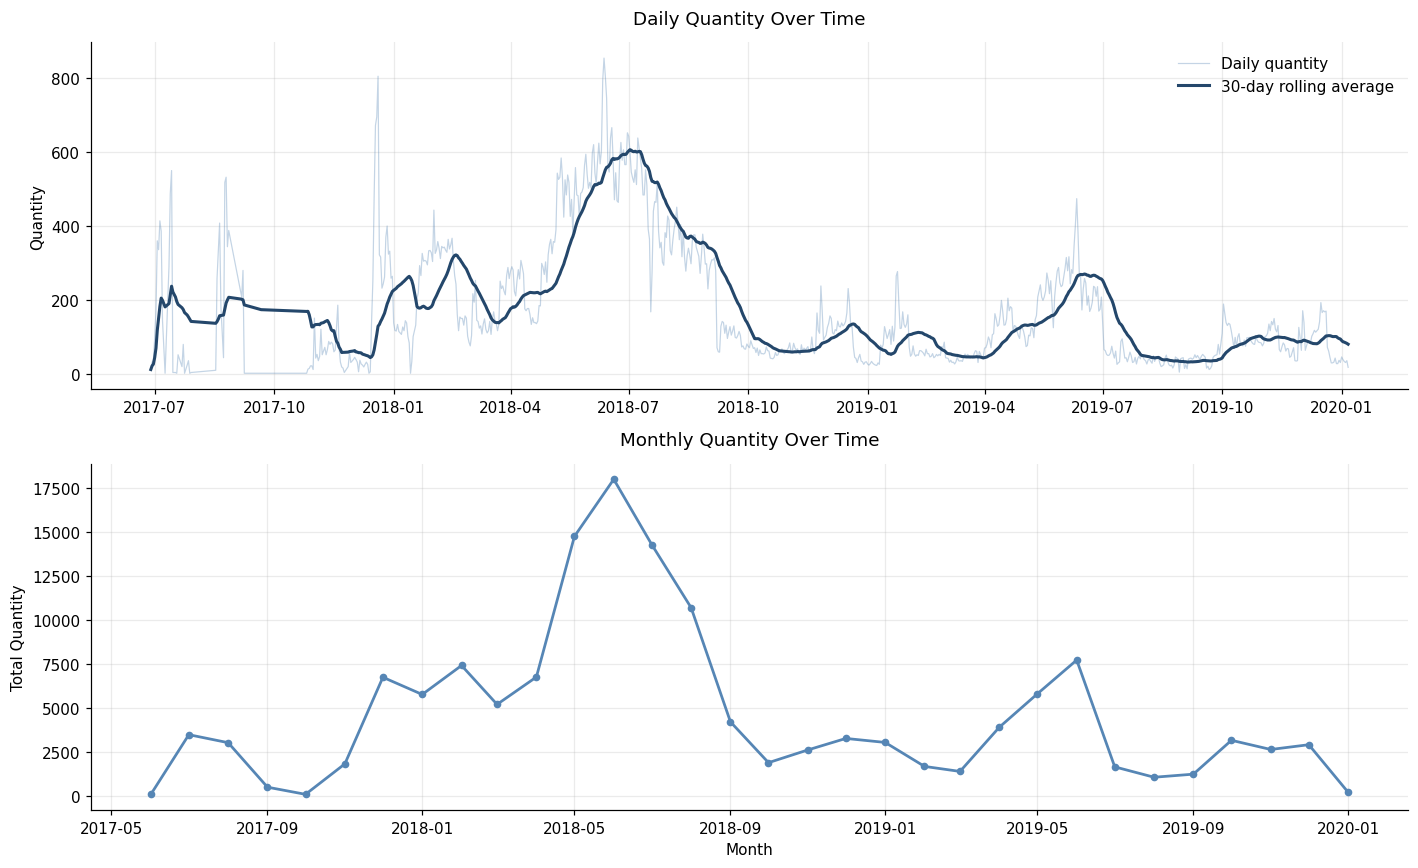

In [6]:
daily = (
    orders.groupby("date")["count"]
    .sum()
    .sort_index()
)

monthly = (
    orders.groupby("month")["count"]
    .sum()
    .sort_index()
)

fig, axes = plt.subplots(2, 1, figsize=(13, 8))

axes[0].plot(
    daily.index,
    daily.values,
    color="#5686B5",
    alpha=0.35,
    linewidth=0.8,
    label="Daily quantity"
)

axes[0].plot(
    daily.index,
    daily.rolling(30, min_periods=1).mean(),
    color="#24476B",
    linewidth=2,
    label="30-day rolling average"
)

axes[0].set_title("Daily Quantity Over Time", pad=12)
axes[0].set_ylabel("Quantity")
axes[0].legend(frameon=False)

axes[1].plot(
    monthly.index,
    monthly.values,
    marker="o",
    markersize=4,
    linewidth=1.8,
    color="#5686B5"
)

axes[1].set_title("Monthly Quantity Over Time", pad=12)
axes[1].set_ylabel("Total Quantity")
axes[1].set_xlabel("Month")

plt.tight_layout()
plt.show()

Виражена сезонність: пік у травні – серпні, максимум у червні 2018 (~18 тис.). Пік 2019 року (~7,7 тис.) приблизно на 57% нижчий, тобто попит або продажі помітно просіли рік до року. Також є одноразовий спайк у грудні 2017 (~800/день)

,records,total_quantity,unique_locations
warehouse_zip,,,
17202,"25,338","40,811","4,898"
46168,"20,489","33,318","5,567"
75236,"13,256","21,922","2,767"
89434,"11,894","19,614","1,639"
91761,"11,869","18,975","1,306"
12189,"5,750","9,471","1,681"
99999,"1,338","2,569",383


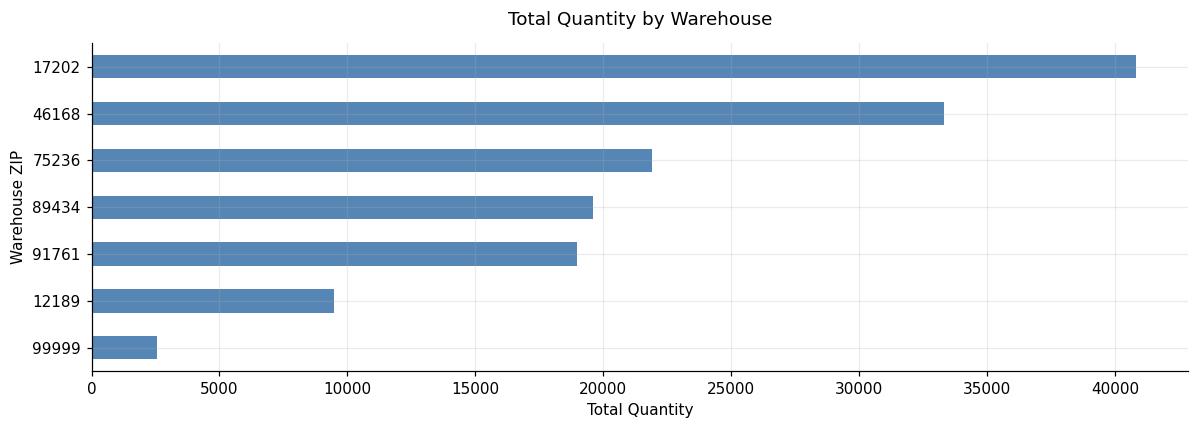

In [7]:
warehouse_stats = (
    orders.groupby("warehouse_zip")
    .agg(
        records=("count", "size"),
        total_quantity=("count", "sum"),
        unique_locations=("code", "nunique")
    )
    .sort_values("total_quantity", ascending=False)
)

display(
    warehouse_stats.style
    .format("{:,.0f}")
    .background_gradient(subset=["total_quantity"], cmap="Blues")
)

fig, ax = plt.subplots(figsize=(11, 4))

warehouse_stats["total_quantity"].sort_values().plot(
    kind="barh",
    ax=ax,
    color="#5686B5"
)

ax.set_title("Total Quantity by Warehouse", pad=12)
ax.set_xlabel("Total Quantity")
ax.set_ylabel("Warehouse ZIP")

plt.tight_layout()
plt.show()

In [8]:
print("ORDERS DATASET — KEY STATISTICS")
print("-" * 45)

print(f"Total records: {len(orders):,}")
print(f"Total quantity: {orders['count'].sum():,}")
print(f"Average quantity per record: {orders['count'].mean():.2f}")
print(f"Median quantity per record: {orders['count'].median():.0f}")
print(f"Maximum quantity per record: {orders['count'].max():,}")

print("\nTEMPORAL COVERAGE")
print("-" * 45)

print(f"Start date: {orders['date'].min().date()}")
print(f"End date: {orders['date'].max().date()}")
print(f"Number of unique dates: {orders['date'].nunique():,}")

print("\nGEOGRAPHIC COVERAGE")
print("-" * 45)

print(f"Unique locations: {orders['code'].nunique():,}")
print(f"Unique cities: {orders['city'].nunique():,}")
print(f"Unique warehouses: {orders['warehouse_zip'].nunique():,}")

print("\nDATA QUALITY")
print("-" * 45)

print(f"Missing values: {orders.isna().sum().sum():,}")
print(f"Duplicate rows: {orders.duplicated().sum():,}")

ORDERS DATASET — KEY STATISTICS
---------------------------------------------
Total records: 89,934
Total quantity: 146,680
Average quantity per record: 1.63
Median quantity per record: 2
Maximum quantity per record: 12

TEMPORAL COVERAGE
---------------------------------------------
Start date: 2017-06-28
End date: 2020-01-06
Number of unique dates: 840

GEOGRAPHIC COVERAGE
---------------------------------------------
Unique locations: 18,241
Unique cities: 13,339
Unique warehouses: 7

DATA QUALITY
---------------------------------------------
Missing values: 1,690
Duplicate rows: 0


## 1.2 Sales data

In [9]:
sales = pd.read_excel("sales.xlsx")

sales["date"] = pd.to_datetime(sales["Unnamed: 0"])
sales = sales.drop(columns=["Unnamed: 0"])

sales = sales.sort_values("date").reset_index(drop=True)

sales.head()

,inventory_fbm,inventory_fba,automatic ice maker,ice maker under counter machine,ice maker 30,ice cube maker,ice maker,ice cube trays,ice maker machine,ice machine,...,counter ice machine,clear ice machine,ice machine portable,16 oz,best ice machine,ice makers,small ice machine,ice machine countertop,target,date
0,0.127401,0.0,0.0,0.0,0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0,0.0,0.0,0.0,0.0,0.0,2017-09-27
1,0.127401,0.0,0.0,0.0,0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0,0.0,0.0,0.0,0.0,0.0,2017-09-28
2,0.127401,0.0,0.0,0.0,0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0,0.0,0.0,0.0,0.0,0.0,2017-09-29
3,0.127401,0.0,0.0,0.0,0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0,0.0,0.0,0.0,0.0,0.0,2017-09-30
4,0.127401,0.0,0.0,0.0,0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0,0.0,0.0,0.0,0.0,0.0,2017-10-01


In [10]:
overview = pd.DataFrame({
    "Metric": [
        "Number of rows",
        "Number of columns",
        "Date from",
        "Date to",
        "Unique dates",
        "Missing target values",
        "Zero target values",
        "Total target (non-missing)",
        "Number of search query features",
    ],
    "Value": [
        f"{len(sales):,}",
        len(sales.columns),
        sales["date"].min().strftime("%Y-%m-%d"),
        sales["date"].max().strftime("%Y-%m-%d"),
        sales["date"].nunique(),
        f"{sales['target'].isna().sum():,}",
        f"{(sales['target'] == 0).sum():,}",
        f"{sales['target'].sum():,.0f}",
        len([c for c in sales.columns if c not in [
            "date", "target", "inventory_fbm", "inventory_fba"
        ]])
    ]
})

display(
    overview.style
    .hide(axis="index")
    .set_properties(**{"text-align": "left", "padding": "8px"})
    .set_table_styles([
        {"selector": "th", "props": [
            ("background-color", "#121315"),
            ("font-weight", "bold"),
            ("text-align", "left")
        ]}
    ])
)

Metric,Value
Number of rows,"1,191"
Number of columns,54
Date from,2017-09-27
Date to,2020-12-30
Unique dates,1191
Missing target values,282
Zero target values,108
Total target (non-missing),"86,438"
Number of search query features,50


In [11]:
quality = pd.DataFrame({
    "Data Type": sales.dtypes.astype(str),
    "Missing Values": sales.isna().sum(),
    "Missing (%)": (sales.isna().mean() * 100).round(2),
    "Unique Values": sales.nunique()
})

display(
    quality.style
    .background_gradient(subset=["Missing (%)"], cmap="YlOrRd")
    .format({"Missing (%)": "{:.2f}%"})
)

print(f"Duplicate rows: {sales.duplicated().sum():,}")
print(f"Duplicate dates: {sales['date'].duplicated().sum():,}")

,Data Type,Missing Values,Missing (%),Unique Values
inventory_fbm,float64,0,0.00%,507
inventory_fba,float64,0,0.00%,475
automatic ice maker,float64,0,0.00%,56
ice maker under counter machine,float64,0,0.00%,24
ice maker 30,int64,0,0.00%,1
ice cube maker,float64,0,0.00%,50
ice maker,float64,0,0.00%,53
ice cube trays,float64,0,0.00%,91
ice maker machine,float64,0,0.00%,48
ice machine,float64,0,0.00%,34


Duplicate rows: 0
Duplicate dates: 0


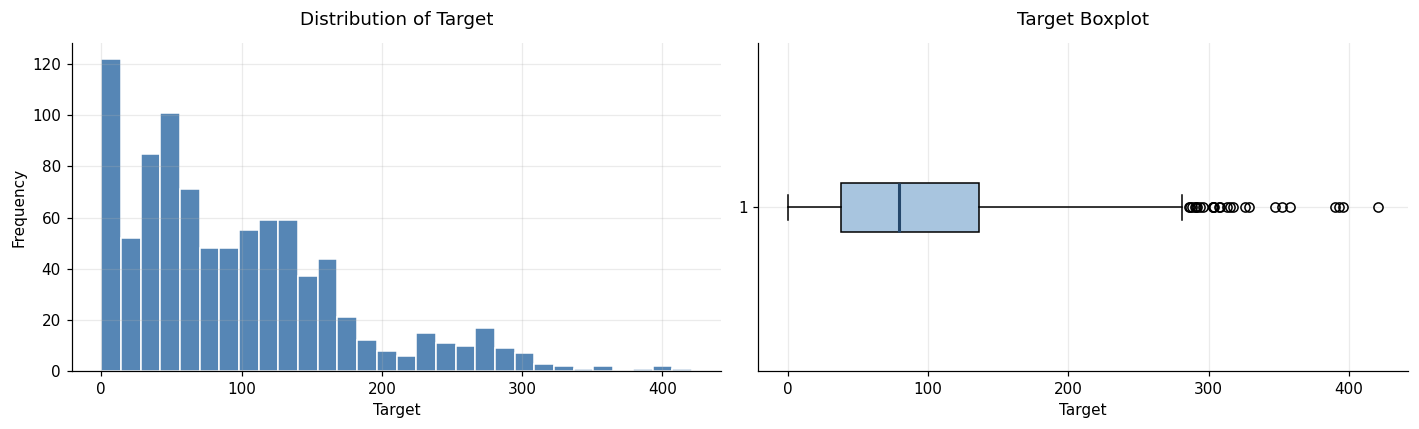

,Target Statistics
count,909.00
mean,95.09
std,78.52
min,0.00
25%,38.00
50%,79.00
75%,136.00
max,421.00


In [12]:
target = sales["target"].dropna()

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].hist(
    target,
    bins=30,
    color="#5686B5",
    edgecolor="white"
)

axes[0].set_title("Distribution of Target", pad=12)
axes[0].set_xlabel("Target")
axes[0].set_ylabel("Frequency")

axes[1].boxplot(
    target,
    vert=False,
    patch_artist=True,
    boxprops=dict(facecolor="#A8C5DF"),
    medianprops=dict(color="#24476B", linewidth=2)
)

axes[1].set_title("Target Boxplot", pad=12)
axes[1].set_xlabel("Target")

plt.tight_layout()
plt.show()

display(
    target.describe()
    .to_frame("Target Statistics")
    .round(2)
)

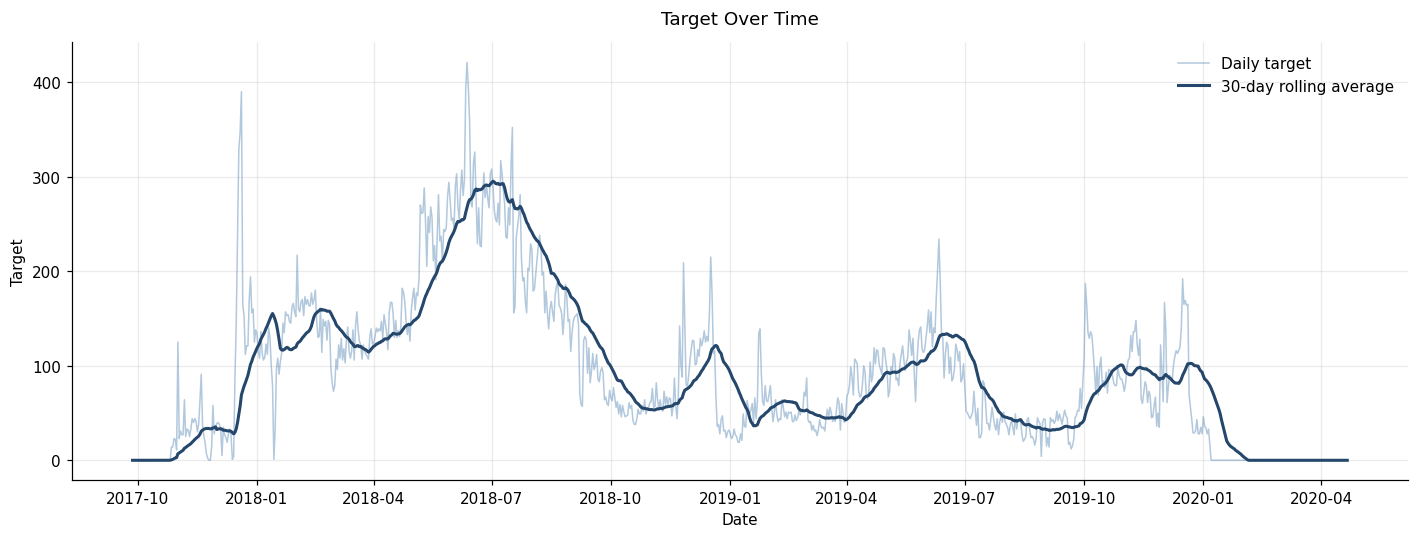

In [13]:
daily_target = (
    sales.set_index("date")["target"]
    .sort_index()
)

fig, ax = plt.subplots(figsize=(13, 5))

ax.plot(
    daily_target.index,
    daily_target.values,
    color="#5686B5",
    alpha=0.45,
    linewidth=1,
    label="Daily target"
)

ax.plot(
    daily_target.index,
    daily_target.rolling(30, min_periods=1).mean(),
    color="#24476B",
    linewidth=2,
    label="30-day rolling average"
)

ax.set_title("Target Over Time", pad=12)
ax.set_xlabel("Date")
ax.set_ylabel("Target")
ax.legend(frameon=False)

plt.tight_layout()
plt.show()

Динаміка майже повторює orders: пік у травні – липні 2018 (~300/день у згладженому ряді), менший пік влітку 2019 (~130) і невелике зростання у жовтні – грудні 2019. Присутня літня сезонність

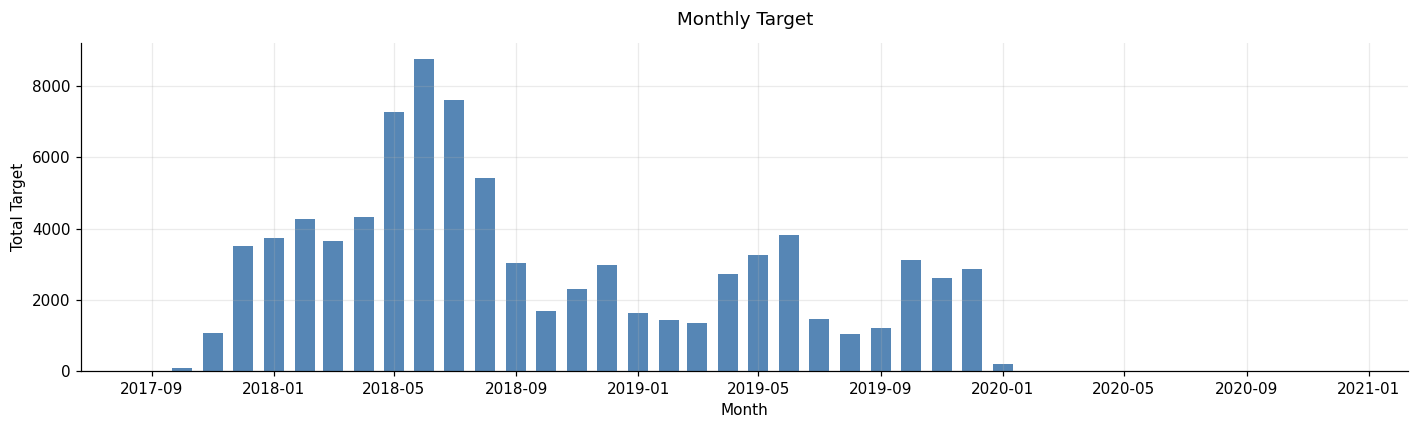

In [14]:
monthly_target = (
    sales.assign(month=sales["date"].dt.to_period("M"))
    .groupby("month")["target"]
    .agg(["sum", "mean", "count"])
)

monthly_target.index = monthly_target.index.to_timestamp()

fig, ax = plt.subplots(figsize=(13, 4))

ax.bar(
    monthly_target.index,
    monthly_target["sum"],
    width=20,
    color="#5686B5"
)

ax.set_title("Monthly Target", pad=12)
ax.set_xlabel("Month")
ax.set_ylabel("Total Target")

plt.tight_layout()
plt.show()

Максимум ~8,8 тис. у червні 2018, червень 2019 приблизно вдвічі-втричі нижчий (~3,8 тис.).

In [15]:
feature_cols = [
    c for c in sales.columns
    if c not in ["date", "target", "inventory_fbm", "inventory_fba"]
]

search_stats = sales[feature_cols].describe().T

search_stats = search_stats.sort_values(
    "mean",
    ascending=False
)

display(
    search_stats.head(15).round(2).style
    .background_gradient(subset=["mean"], cmap="Blues")
)

,count,mean,std,min,25%,50%,75%,max
under counter ice maker,1191.000000,4.600000,8.670000,0.000000,0.000000,0.000000,6.930000,46.000000
ice maker commercial,1191.000000,3.560000,5.600000,0.000000,0.000000,0.000000,10.650000,30.000000
ice cube trays,1191.000000,3.350000,5.790000,0.000000,0.000000,0.000000,6.000000,34.000000
ice maker under counter machine,1191.000000,3.010000,4.720000,0.000000,0.000000,0.000000,9.000000,32.000000
large ice machine,1191.000000,1.980000,4.800000,0.000000,0.000000,0.000000,0.000000,49.000000
clear ice maker,1191.000000,1.970000,3.360000,0.000000,0.000000,0.000000,5.900000,25.000000
crushed ice maker,1191.000000,1.580000,2.520000,0.000000,0.000000,0.000000,4.720000,16.000000
clear ice machine,1191.000000,1.470000,2.350000,0.000000,0.000000,0.000000,4.410000,19.000000
counter ice machine,1191.000000,1.140000,2.860000,0.000000,0.000000,0.000000,1.000000,27.000000
ice maker portable countertop,1191.000000,1.040000,3.120000,0.000000,0.000000,0.000000,1.000000,33.000000


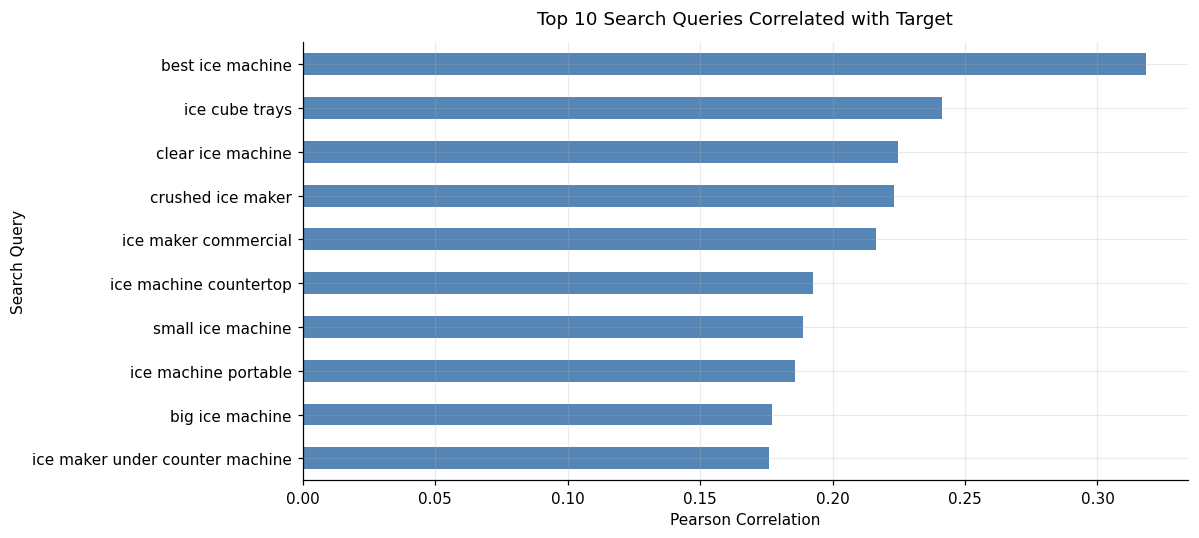

In [16]:
search_corr = (
    sales[["target"] + feature_cols]
    .corr()["target"]
    .drop("target")
    .dropna()
    .sort_values(ascending=False)
)

fig, ax = plt.subplots(figsize=(11, 5))

search_corr.head(10).sort_values().plot(
    kind="barh",
    ax=ax,
    color="#5686B5"
)

ax.set_title("Top 10 Search Queries Correlated with Target", pad=12)
ax.set_xlabel("Pearson Correlation")
ax.set_ylabel("Search Query")

plt.tight_layout()
plt.show()

Кореляції слабкі або помірні (0,18–0,32), найвища у best ice machine (0,32).

In [17]:
print("SALES DATASET — KEY STATISTICS")
print("-" * 45)

print(f"Total records: {len(sales):,}")
print(f"Date range: {sales['date'].min().date()} — {sales['date'].max().date()}")
print(f"Unique dates: {sales['date'].nunique():,}")

print("\nTARGET VARIABLE")
print("-" * 45)

print(f"Available values: {sales['target'].notna().sum():,}")
print(f"Missing values: {sales['target'].isna().sum():,}")
print(f"Zero values: {(sales['target'] == 0).sum():,}")
print(f"Mean: {sales['target'].mean():.2f}")
print(f"Median: {sales['target'].median():.2f}")
print(f"Maximum: {sales['target'].max():.0f}")
print(f"Total: {sales['target'].sum():,.0f}")

print("\nINVENTORY")
print("-" * 45)

print(f"FBM mean: {sales['inventory_fbm'].mean():.2f}")
print(f"FBA mean: {sales['inventory_fba'].mean():.2f}")

print("\nSEARCH FEATURES")
print("-" * 45)

print(f"Number of search query features: {len(feature_cols)}")

print("\nDATA QUALITY")
print("-" * 45)

print(f"Duplicate rows: {sales.duplicated().sum():,}")
print(f"Duplicate dates: {sales['date'].duplicated().sum():,}")

SALES DATASET — KEY STATISTICS
---------------------------------------------
Total records: 1,191
Date range: 2017-09-27 — 2020-12-30
Unique dates: 1,191

TARGET VARIABLE
---------------------------------------------
Available values: 909
Missing values: 282
Zero values: 108
Mean: 95.09
Median: 79.00
Maximum: 421
Total: 86,438

INVENTORY
---------------------------------------------
FBM mean: 0.33
FBA mean: 0.29

SEARCH FEATURES
---------------------------------------------
Number of search query features: 50

DATA QUALITY
---------------------------------------------
Duplicate rows: 0
Duplicate dates: 0


## 1.3 Competitors data

In [18]:
competitors = pd.read_excel("competitors.xlsx")

competitors = competitors.rename(
    columns={"Unnamed: 0": "date"}
)

competitors["date"] = pd.to_datetime(competitors["date"])

price_cols = [
    col for col in competitors.columns
    if col.endswith("_competitorPrice")
]

price_stats = competitors[price_cols].describe().T

display(price_stats.round(2))

,count,mean,std,min,25%,50%,75%,max
B07GY4DS42_Igloo ICEB26AQ 26-Pound Automatic Portable Countertop Ice Maker Machine - Aqua 4.0 (220 reviews)_competitorPrice,204.0,133.54,7.64,107.30,127.22,139.99,139.99,143.49
"B004VV8GOQ_Frigidaire EFIC103 Ice Maker Machine Heavy Duty, Large Stainless Steel 3.3 (1575 reviews)_competitorPrice",204.0,128.79,12.70,106.66,116.70,133.05,141.68,152.99
"B07GVYF7Z5_Igloo ICEB26SS 26-Pound Automatic Portable Countertop Ice Maker Machine, Stainless Steel 4.0 (220 reviews)_competitorPrice",204.0,134.16,18.04,95.00,119.98,145.73,149.99,149.99
"B00INXG9MY_Compact Ice Maker, Red 3.7 (1958 reviews)_competitorPrice",204.0,106.53,11.56,81.91,98.25,106.05,115.69,139.99
"B01GE7V1H8_Frigidaire EFIC108-WHITE Portable Compact Maker, Counter Top Ice Making Machine, White 4.2 (109 reviews)_competitorPrice",204.0,134.42,36.28,76.05,97.18,119.99,170.66,170.66
"B074VG4CM8_Hamilton Beach PIM-1-3A Portable Ice Maker, 26 lb. Capacity, Black_competitorPrice",204.0,114.51,7.97,88.64,107.37,114.53,119.99,130.09
"B07GY5MBDJ_Igloo ICEB26BK Portable 26-Pound Automatic Ice Maker, Black 4.0 (220 reviews)_competitorPrice",204.0,124.01,18.32,82.87,108.99,139.99,139.99,139.99
"B07JBJWP2W_Frigidaire Counter Top Ice Maker, Produces 26 pounds Ice per Day, Stainless Steel with White See-through Lid 3.7 (30 reviews)_competitorPrice",204.0,134.84,34.44,79.31,99.00,133.51,169.44,190.81
"B074VG1DCZ_Hamilton Beach PIM-2-3A Portable Ice Maker, 26 lb. Capacity, Black Stainless Steel_competitorPrice",204.0,115.49,12.89,95.99,105.64,110.48,119.99,166.92


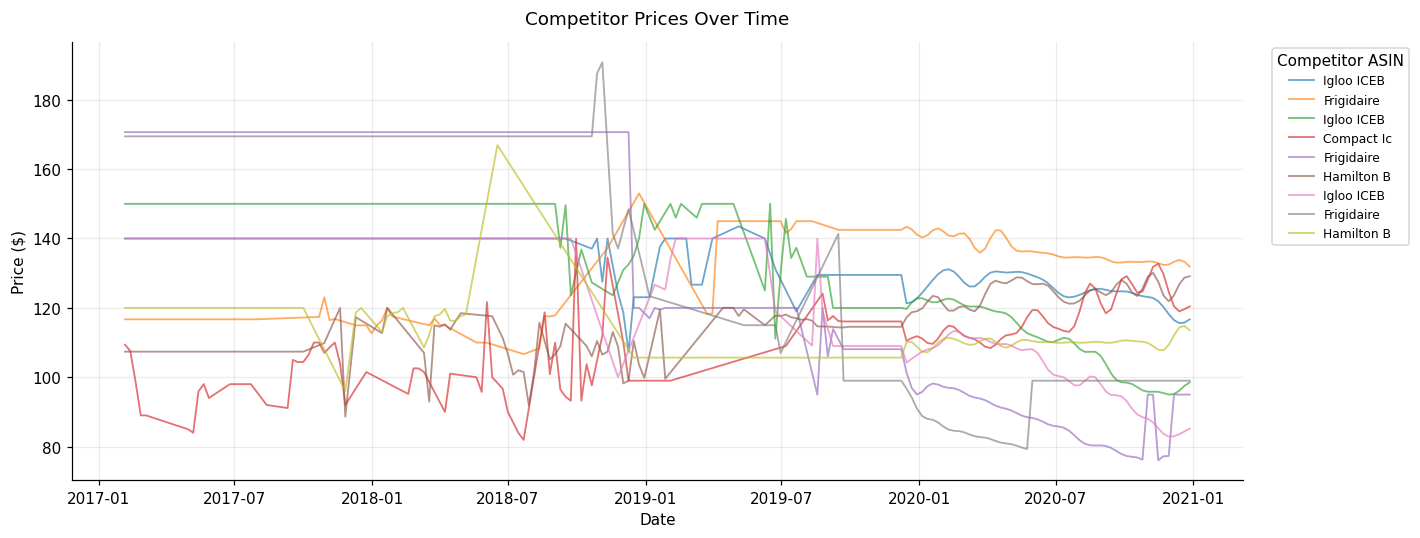

In [19]:
fig, ax = plt.subplots(figsize=(13, 5))

for col in price_cols:
    product_name = col.split("_")[1][:10]

    ax.plot(
        competitors["date"],
        competitors[col],
        alpha=0.65,
        linewidth=1.2,
        label=product_name
    )

ax.set_title("Competitor Prices Over Time", pad=12)
ax.set_xlabel("Date")
ax.set_ylabel("Price ($)")
ax.legend(title="Competitor ASIN", bbox_to_anchor=(1.02, 1),
          loc="upper left", fontsize=8)

plt.tight_layout()
plt.show()

In [20]:
competitor_features = competitors[["date"]].copy()

prices = competitors[price_cols]

competitor_features["competitor_price_mean"] = prices.mean(axis=1)
competitor_features["competitor_price_median"] = prices.median(axis=1)
competitor_features["competitor_price_min"] = prices.min(axis=1)
competitor_features["competitor_price_max"] = prices.max(axis=1)
competitor_features["competitor_price_std"] = prices.std(axis=1)

display(competitor_features.head())

,date,competitor_price_mean,competitor_price_median,competitor_price_min,competitor_price_max,competitor_price_std
0,2017-02-05,135.943148,139.99,107.370,170.655,24.249568
1,2017-02-12,135.741296,139.99,107.370,170.655,24.504661
2,2017-02-19,134.764074,139.99,98.755,170.655,25.904800
3,2017-02-26,133.680185,139.99,89.000,170.655,27.738946
4,2017-03-05,133.680185,139.99,89.000,170.655,27.738946


In [21]:
competitors = pd.read_excel("competitors.xlsx")

competitors = competitors.rename(
    columns={"Unnamed: 0": "date"}
)

competitors["date"] = pd.to_datetime(competitors["date"])

ratio_cols = [
    col for col in competitors.columns
    if col.endswith("_competitorRatio")
]

inferred_prices = pd.DataFrame(index=competitors.index)

for ratio_col in ratio_cols:
    price_col = ratio_col.replace(
        "_competitorRatio",
        "_competitorPrice"
    )

    inferred_prices[ratio_col] = (
        competitors[price_col] / competitors[ratio_col]
    ).where(
        (competitors[price_col] > 0) &
        (competitors[ratio_col] > 0)
    )

# Aggregate inferred prices
competitors["our_price"] = inferred_prices.median(axis=1)

competitors["price_estimates_count"] = (
    inferred_prices.notna().sum(axis=1)
)

competitors["price_estimates_std"] = (
    inferred_prices.std(axis=1)
)

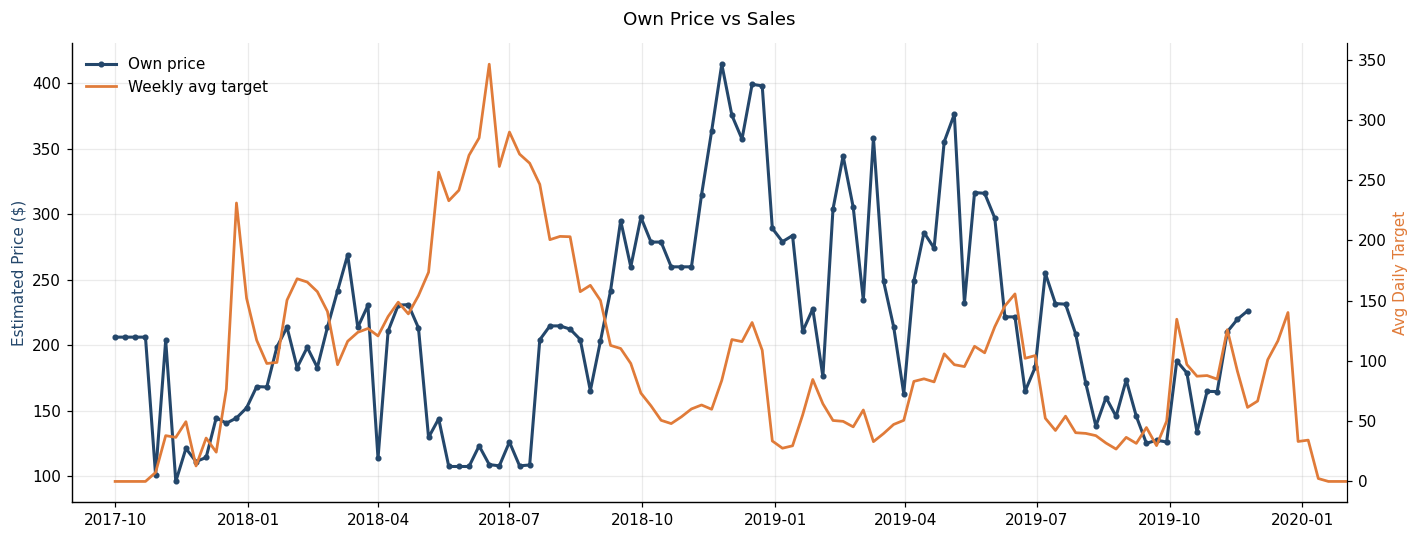

In [22]:
weekly_target = (
    sales.set_index("date")["target"]
    .resample("W-SUN").mean()
)

price = competitors.set_index("date")["our_price"]

price = price.where(price.index < "2019-12-01")

fig, ax1 = plt.subplots(figsize=(13, 5))

ax1.plot(price.index, price.values, color="#24476B",
         linewidth=2, marker="o", markersize=3, label="Own price")
ax1.set_ylabel("Estimated Price ($)", color="#24476B")

ax2 = ax1.twinx()
ax2.plot(weekly_target.index, weekly_target.values, color="#E07B39",
         linewidth=1.8, label="Weekly avg target")
ax2.set_ylabel("Avg Daily Target", color="#E07B39")
ax2.spines["right"].set_visible(True)
ax2.grid(False)

ax1.set_xlim(pd.Timestamp("2017-09-01"), pd.Timestamp("2020-02-01"))
ax1.set_title("Own Price vs Sales", pad=12)

lines = ax1.get_lines() + ax2.get_lines()
ax1.legend(lines, [l.get_label() for l in lines], frameon=False, loc="upper left")

plt.tight_layout()
plt.show()

Власна ціна сильно коливається: 95–420$. Найнижча ~107$ у травні – липні 2018 збігається з піком продажів. Висока ~350–410$ у кінці 2018 і навесні 2019 супроводжується просіданням продажів, а зниження до 125–165$ у вересні – жовтні 2019 збігається із зростанням у жовтні 2019.

In [23]:
print("PRICE RECONSTRUCTION QUALITY")
print("-" * 40)

print(
    f"Available dates: "
    f"{competitors['our_price'].notna().sum()}"
)

print(
    f"Missing dates: "
    f"{competitors['our_price'].isna().sum()}"
)

print(
    f"Average number of competitor estimates: "
    f"{competitors['price_estimates_count'].mean():.2f}"
)

print(
    f"Mean disagreement between estimates: "
    f"${competitors['price_estimates_std'].mean():.4f}"
)

display(
    competitors["our_price"].describe().to_frame(
        "Reconstructed Price ($)"
    ).round(2)
)

PRICE RECONSTRUCTION QUALITY
----------------------------------------
Available dates: 170
Missing dates: 34
Average number of competitor estimates: 7.50
Mean disagreement between estimates: $0.0000


,Reconstructed Price ($)
count,170.00
mean,283.17
std,116.03
min,95.93
25%,184.35
50%,259.78
75%,422.78
max,422.78


## 1.4 Life cycle of the product and the modelling window

Вище кожен файл розглянуто окремо. Далі збираємо з них один ряд для моделювання: визначаємо робоче вікно, описуємо ряд, розбираємося з аномаліями та пропусками, дивимось, як файли пов'язані між собою, і агрегуємо.

In [24]:
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from scipy.signal import periodogram
from scipy import stats
import warnings

warnings.filterwarnings("ignore")

daily = sales.set_index("date").sort_index()
tgt = daily["target"]

FIRST_SALE = tgt[tgt > 0].index[0]
LAST_SALE = tgt[tgt > 0].index[-1]
LAST_VALID = tgt.last_valid_index()

print(f"First sale:           {FIRST_SALE.date()}")
print(f"Last sale:            {LAST_SALE.date()}")
print(f"Last non-NaN target:  {LAST_VALID.date()}")
print()
print("Target around the launch (25.10.2017 - 10.11.2017):")
print(tgt.loc["2017-10-25":"2017-11-10"].astype(int).tolist())
print("Target around the end (14.12.2019 - 09.01.2020):")
print(tgt.loc["2019-12-14":"2020-01-09"].astype(int).tolist())

First sale:           2017-10-26
Last sale:            2020-01-06
Last non-NaN target:  2020-03-23

Target around the launch (25.10.2017 - 10.11.2017):
[0, 1, 14, 14, 23, 22, 11, 125, 23, 31, 27, 27, 64, 25, 33, 32, 25]
Target around the end (14.12.2019 - 09.01.2020):
[120, 140, 192, 165, 169, 164, 165, 69, 57, 44, 29, 29, 31, 43, 28, 28, 35, 28, 46, 36, 34, 28, 33, 17, 0, 0, 0]


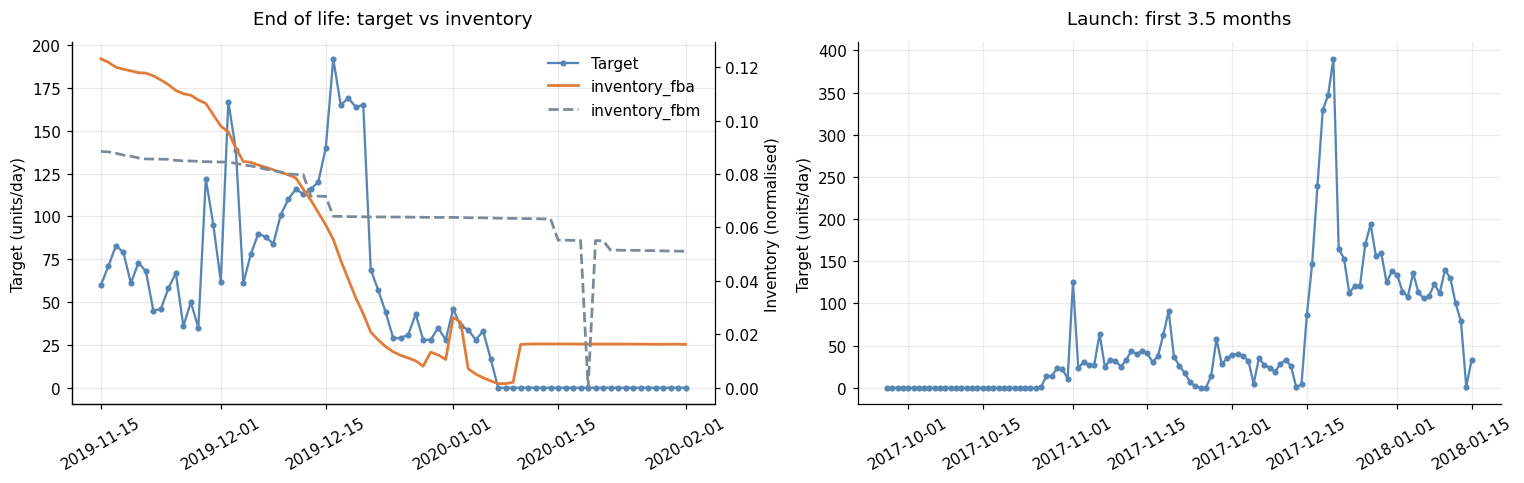

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

end_view = daily.loc["2019-11-15":"2020-02-01"]
axes[0].plot(end_view.index, end_view["target"], color="#5686B5", marker="o", markersize=3, label="Target")
axes[0].set_ylabel("Target (units/day)")
ax_inv = axes[0].twinx()
ax_inv.plot(end_view.index, end_view["inventory_fba"], color="#E07B39", linewidth=1.8, label="inventory_fba")
ax_inv.plot(end_view.index, end_view["inventory_fbm"], color="#7A8A99", linewidth=1.8, linestyle="--", label="inventory_fbm")
ax_inv.set_ylabel("Inventory (normalised)")
ax_inv.spines["right"].set_visible(True)
ax_inv.grid(False)
axes[0].set_title("End of life: target vs inventory", pad=12)
lines = axes[0].get_lines() + ax_inv.get_lines()
axes[0].legend(lines, [l.get_label() for l in lines], frameon=False, loc="upper right")
axes[0].tick_params(axis="x", rotation=30)

start_view = daily.loc["2017-09-20":"2018-01-15"]
axes[1].plot(start_view.index, start_view["target"], color="#5686B5", marker="o", markersize=3)
axes[1].set_title("Launch: first 3.5 months", pad=12)
axes[1].set_ylabel("Target (units/day)")
axes[1].tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.show()

In [26]:
inv_both_one = (daily["inventory_fbm"] == 1.0) & (daily["inventory_fba"] == 1.0)
print("Days where both inventory columns equal exactly 1.0:", int(inv_both_one.sum()))
print("Their date range:", inv_both_one[inv_both_one].index.min().date(), "-", inv_both_one[inv_both_one].index.max().date())
print("Do they coincide exactly with target = NaN?", bool((inv_both_one == tgt.isna()).all()))

Days where both inventory columns equal exactly 1.0: 282
Their date range: 2020-03-24 - 2020-12-30
Do they coincide exactly with target = NaN? True


In [27]:
MODEL_START = pd.Timestamp("2017-11-01")
MODEL_END = pd.Timestamp("2019-12-20")

phase = pd.Series("modelling window", index=daily.index)
phase[daily.index < FIRST_SALE] = "1. before first sale"
phase[(daily.index >= FIRST_SALE) & (daily.index < MODEL_START)] = "2. launch (excluded)"
phase[(daily.index >= MODEL_START) & (daily.index <= MODEL_END)] = "3. modelling window"
phase[(daily.index > MODEL_END) & (daily.index <= LAST_VALID)] = "4. stock run-out (excluded)"
phase[daily.index > LAST_VALID] = "5. no data, target NaN (excluded)"

phase_table = daily.groupby(phase)["target"].agg(
    first_day=lambda s: s.index.min().date(),
    last_day=lambda s: s.index.max().date(),
    days="size",
    total="sum",
    mean="mean",
    zero_days=lambda s: int((s == 0).sum()),
)
display(phase_table.round(1))

ts = tgt.loc[MODEL_START:MODEL_END].asfreq("D")
assert ts.notna().all()
print(f"\nModelling series: {ts.index.min().date()} - {ts.index.max().date()}, {len(ts)} days, zero days inside: {int((ts == 0).sum())}")

,first_day,last_day,days,total,mean,zero_days
1. before first sale,2017-09-27,2017-10-25,29,0.0,0.0,29
2. launch (excluded),2017-10-26,2017-10-31,6,85.0,14.2,0
3. modelling window,2017-11-01,2019-12-20,780,85738.0,109.9,2
4. stock run-out (excluded),2019-12-21,2020-03-23,94,615.0,6.5,77
"5. no data, target NaN (excluded)",2020-03-24,2020-12-30,282,0.0,NaN,0



Modelling series: 2017-11-01 - 2019-12-20, 780 days, zero days inside: 2


Перший продаж 26.10.2017, останній 06.01.2020. Значення target = NaN з 24.03.2020 збігаються з днями, коли обидві колонки inventory рівні 1.0, тобто це заглушки, а не нульовий попит.

Обрив настає ще раніше: з 21.12.2019 продажі падають зі ~165 до ~30 на день (69, 57, 44, 29), inventory_fba майже нульовий, потім 17 і нулі. Схоже на розпродаж залишків, а не на поведінку попиту.

Робоче вікно: 01.11.2017 – 20.12.2019, 780 днів і 85 738 продажів (99,2% від усіх), лише 2 нульові дні. Не беремо 29 днів до першого продажу, 6 днів запуску, 94 дні кінця життя та 282 дні з NaN.

## 1.5 Characteristics of the time series

In [28]:
desc = pd.Series({
    "observations": len(ts),
    "mean": ts.mean(),
    "median": ts.median(),
    "std": ts.std(),
    "coefficient of variation": ts.std() / ts.mean(),
    "skewness": stats.skew(ts),
    "excess kurtosis": stats.kurtosis(ts),
    "min": ts.min(),
    "max": ts.max(),
    "zero days": int((ts == 0).sum()),
}).round(2)
display(desc.to_frame("target, modelling window"))

yearly = ts.groupby(ts.index.year).agg(days="size", mean="mean", median="median", std="std", max="max").round(1)
display(yearly)

,"target, modelling window"
observations,780.00
mean,109.92
median,96.00
std,74.88
coefficient of variation,0.68
skewness,1.16
excess kurtosis,1.19
min,0.00
max,421.00
zero days,2.00


,days,mean,median,std,max
date,,,,,
2017,61,74.8,37.0,85.3,390.0
2018,365,150.8,140.0,78.2,421.0
2019,354,73.8,65.0,39.7,234.0


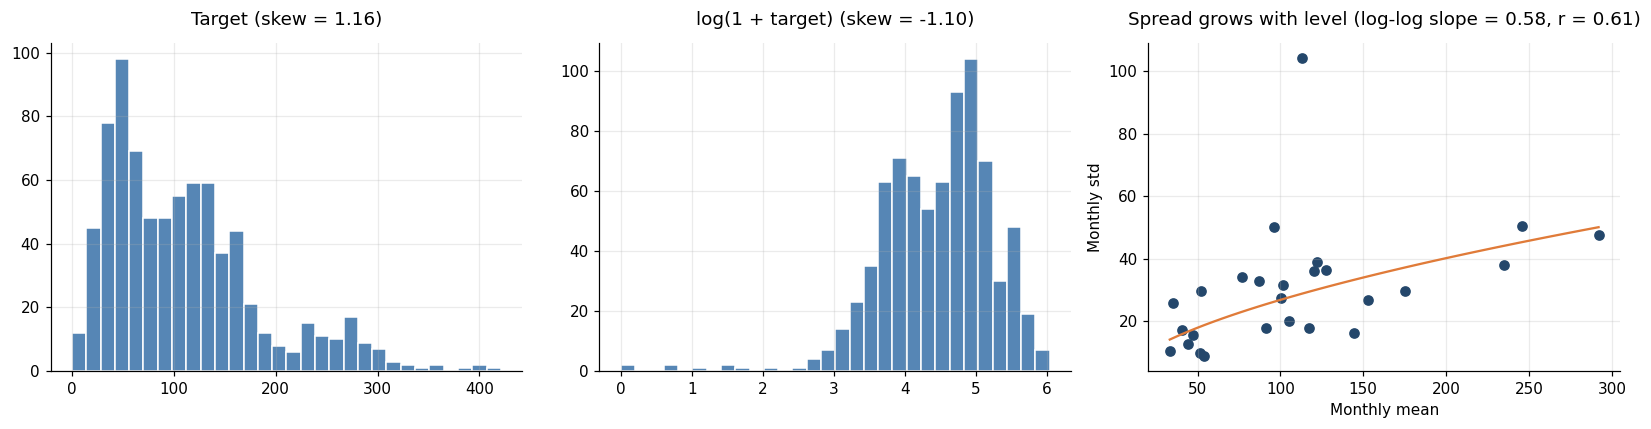

In [29]:
monthly_stat = ts.resample("MS").agg(["mean", "std"])
slope, intercept, r_value, _, _ = stats.linregress(np.log(monthly_stat["mean"]), np.log(monthly_stat["std"]))

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

axes[0].hist(ts, bins=30, color="#5686B5", edgecolor="white")
axes[0].set_title(f"Target (skew = {stats.skew(ts):.2f})", pad=12)

axes[1].hist(np.log1p(ts), bins=30, color="#5686B5", edgecolor="white")
axes[1].set_title(f"log(1 + target) (skew = {stats.skew(np.log1p(ts)):.2f})", pad=12)

axes[2].scatter(monthly_stat["mean"], monthly_stat["std"], color="#24476B")
xs = np.linspace(monthly_stat["mean"].min(), monthly_stat["mean"].max(), 50)
axes[2].plot(xs, np.exp(intercept) * xs ** slope, color="#E07B39")
axes[2].set_xlabel("Monthly mean")
axes[2].set_ylabel("Monthly std")
axes[2].set_title(f"Spread grows with level (log-log slope = {slope:.2f}, r = {r_value:.2f})", pad=12)

plt.tight_layout()
plt.show()

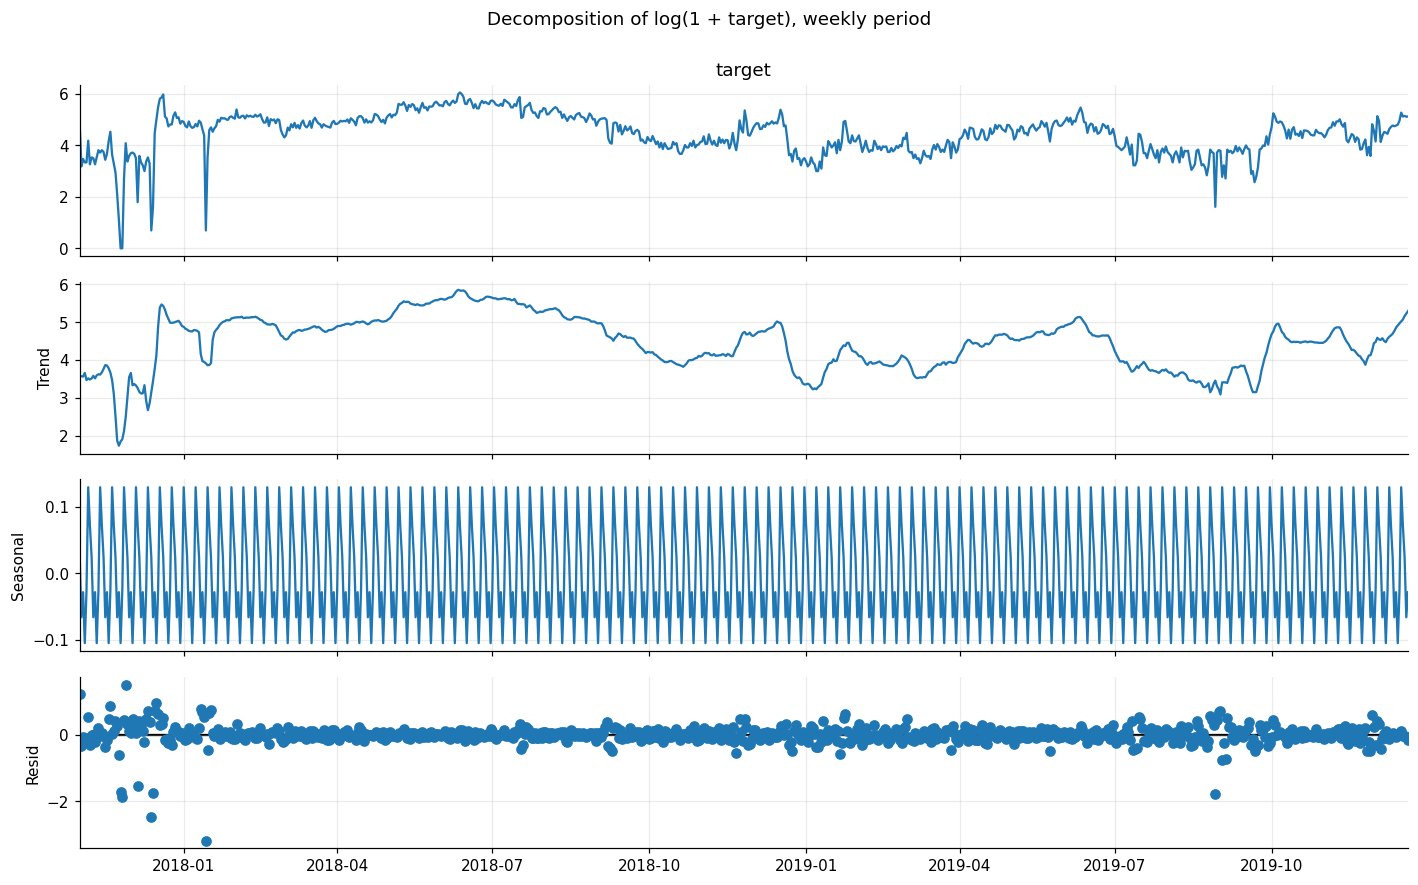

Strength of trend (0..1):            0.86
Strength of weekly seasonality:      0.06


In [30]:
ls = np.log1p(ts)

dec = seasonal_decompose(ls, model="additive", period=7, extrapolate_trend="freq")
fig = dec.plot()
fig.set_size_inches(13, 8)
fig.suptitle("Decomposition of log(1 + target), weekly period", y=1.0)
plt.tight_layout()
plt.show()

strength_trend = max(0, 1 - dec.resid.var() / (dec.resid + dec.trend).var())
strength_season = max(0, 1 - dec.resid.var() / (dec.resid + dec.seasonal).var())
print(f"Strength of trend (0..1):            {strength_trend:.2f}")
print(f"Strength of weekly seasonality:      {strength_season:.2f}")

,mean,std,count,sem
Mon,1.119,0.228,111,0.022
Tue,1.055,0.223,111,0.021
Wed,1.005,0.211,110,0.020
Thu,0.937,0.212,110,0.020
Fri,0.949,0.183,110,0.017
Sat,0.884,0.178,111,0.017
Sun,0.991,0.240,111,0.023


Kruskal-Wallis test, are day-of-week distributions equal?  H = 121.6, p = 0.0000


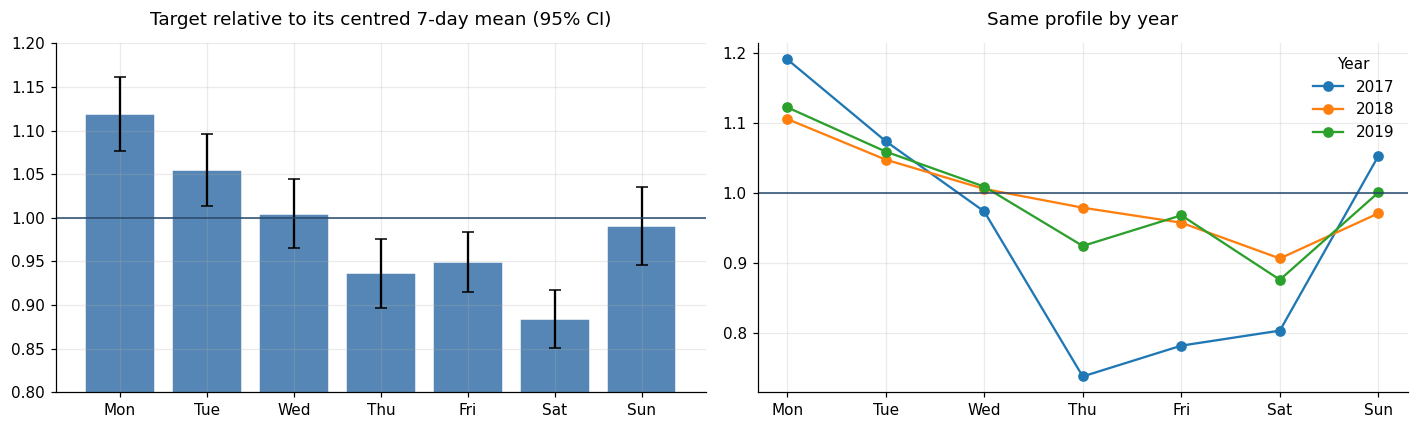

In [31]:
dow_names = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
rel = (ts / ts.rolling(7, center=True).mean()).dropna()

dow = rel.groupby(rel.index.dayofweek).agg(["mean", "std", "count"])
dow.index = dow_names
dow["sem"] = dow["std"] / np.sqrt(dow["count"])
display(dow.round(3))

kw_stat, kw_p = stats.kruskal(*[rel[rel.index.dayofweek == d] for d in range(7)])
print(f"Kruskal-Wallis test, are day-of-week distributions equal?  H = {kw_stat:.1f}, p = {kw_p:.4f}")

by_year_dow = rel.groupby([rel.index.year, rel.index.dayofweek]).mean().unstack(0)
by_year_dow.index = dow_names

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].bar(dow.index, dow["mean"], yerr=1.96 * dow["sem"], color="#5686B5", edgecolor="white", capsize=4)
axes[0].axhline(1, color="#24476B", linewidth=1)
axes[0].set_ylim(0.8, 1.2)
axes[0].set_title("Target relative to its centred 7-day mean (95% CI)", pad=12)
by_year_dow.plot(ax=axes[1], marker="o")
axes[1].axhline(1, color="#24476B", linewidth=1)
axes[1].set_title("Same profile by year", pad=12)
axes[1].legend(frameon=False, title="Year")
plt.tight_layout()
plt.show()

Share of the yearly total by month, %


,1,2,3,4,5,6,7,8,9,10,11,12
2018,6.8,7.8,6.6,7.9,13.2,15.9,13.8,9.9,5.5,3.0,4.2,5.4
2019,6.2,5.5,5.2,10.5,12.5,14.6,5.6,3.9,4.7,11.9,10.0,9.3


Correlation of the 2018 and 2019 monthly profiles: Pearson = 0.23, Spearman = 0.12
Yearly totals: 2018 = 55,055,  2019 (to 20.12) = 26,118


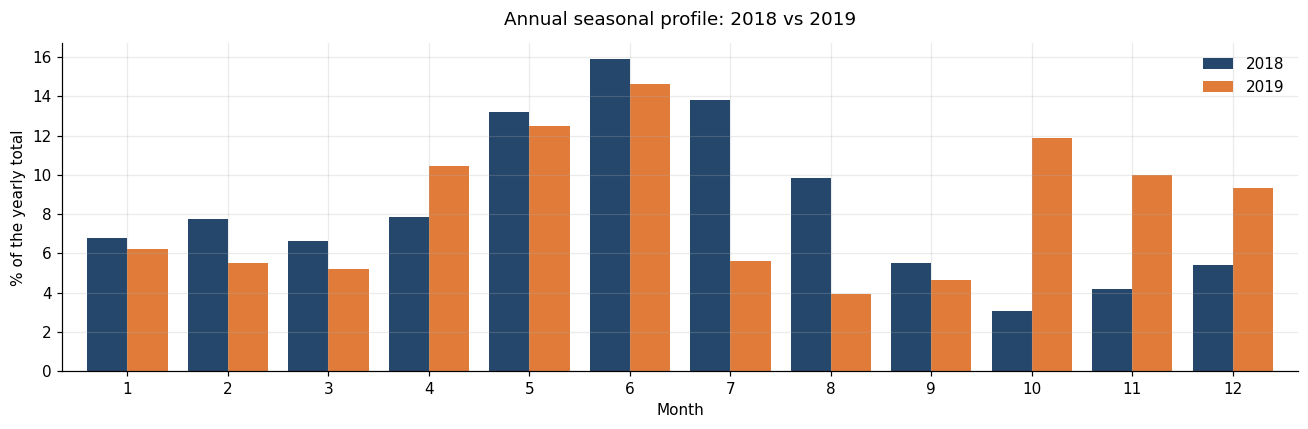

In [32]:
month_sum = ts.resample("MS").sum()
profile = {}
for year in (2018, 2019):
    m = month_sum[month_sum.index.year == year]
    profile[year] = (m / m.sum()).values * 100
profile = pd.DataFrame(profile, index=range(1, 13))

print("Share of the yearly total by month, %")
display(profile.round(1).T)
print(f"Correlation of the 2018 and 2019 monthly profiles: Pearson = {profile[2018].corr(profile[2019]):.2f}, "
      f"Spearman = {profile[2018].corr(profile[2019], method='spearman'):.2f}")
print(f"Yearly totals: 2018 = {month_sum['2018'].sum():,.0f},  2019 (to 20.12) = {month_sum['2019'].sum():,.0f}")

ax = profile.plot(kind="bar", figsize=(12, 4), color=["#24476B", "#E07B39"], width=0.8)
ax.set_xlabel("Month")
ax.set_ylabel("% of the yearly total")
ax.set_title("Annual seasonal profile: 2018 vs 2019", pad=12)
ax.legend(frameon=False)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

,0,1,2,3,4,5,6,7
"period, days",3.49,7.02,3.51,2.71,3.05,6.96,4.66,3.08
power,1.16,1.02,0.94,0.58,0.57,0.55,0.55,0.53


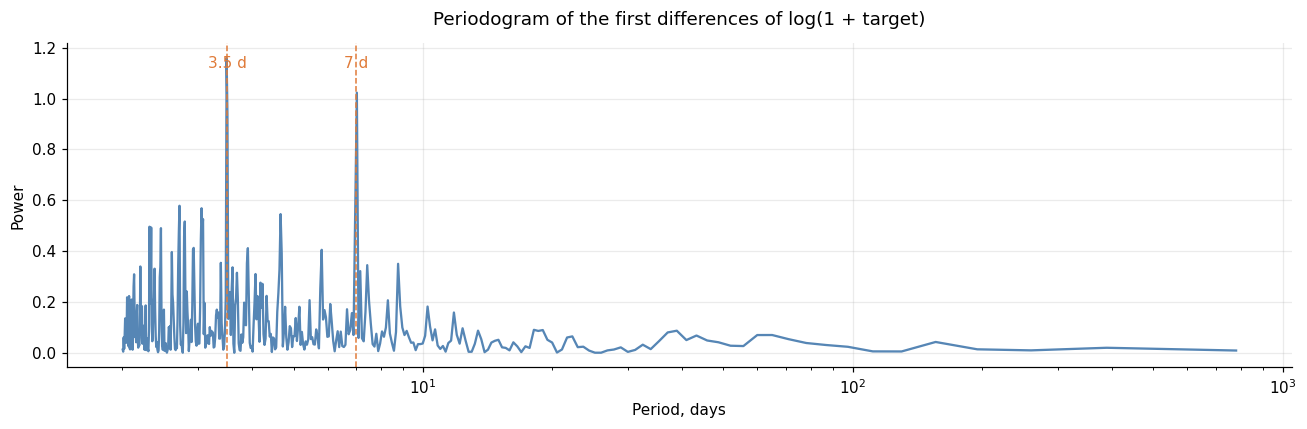

In [33]:
d1 = ls.diff().dropna()
freq, power = periodogram(d1.values, fs=1.0, window="hann")
freq, power = freq[1:], power[1:]

top = np.argsort(power)[::-1][:8]
peaks = pd.DataFrame({"period, days": 1 / freq[top], "power": power[top]}).round(2)
display(peaks.T)

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(1 / freq, power, color="#5686B5")
ax.set_xscale("log")
for p_, lbl in [(7, "7 d"), (3.5, "3.5 d")]:
    ax.axvline(p_, color="#E07B39", linestyle="--", linewidth=1)
    ax.text(p_, ax.get_ylim()[1] * 0.92, lbl, color="#E07B39", ha="center")
ax.set_xlabel("Period, days")
ax.set_ylabel("Power")
ax.set_title("Periodogram of the first differences of log(1 + target)", pad=12)
plt.tight_layout()
plt.show()

Середнє 109,9, медіана 96, std 74,9 (CV 0,68), асиметрія 1,16 — правий хвіст. Середнє за 2018 рік 150,8, за 2019 — 73,8, тобто падіння приблизно вдвічі.

Розкид росте разом з рівнем (нахил log-log між std і mean ≈ 0,58). Логарифм прибирає правий хвіст, але перегинає в лівий (асиметрія −1,10 через кілька днів з майже нульовими продажами). Тому log(1+y) беремо для ETS/ARIMA, а для дерев і метрик лишаємо сирий target.

Тренд домінує (сила тренду 0,86), тижнева сезонність слабка (0,06), але статистично значуща (Kruskal–Wallis, p ≈ 0): понеділок приблизно на 12% вище 7-денного середнього, субота на 12% нижче. Профіль однаковий у 2018 і 2019. Періодограма показує лише піки на 7 і 3,5 дня.

Річна сезонність нестійка. У 2018 травень–липень дають 43% року, у 2019 липень і серпень обвалилися (5,6% і 3,9% проти 13,8% і 9,9%), а жовтень–грудень зросли до 31% проти 12,6%. Кореляція двох профілів 0,23 (Pearson) і 0,12 (Spearman). Причина, схоже, не в календарі, а в наявності товару на FBA (див. 1.8). Двох років замало, щоб вчити річну сезонність, тому в моделі вона не буде жорсткою складовою.

## 1.6 Stationarity and autocorrelation

In [34]:
def stationarity_row(x):
    adf_stat, adf_p = adfuller(x, autolag="AIC")[:2]
    kpss_stat, kpss_p = kpss(x, regression="c", nlags="auto")[:2]
    verdict = "stationary" if (adf_p < 0.05 and kpss_p > 0.05) else (
        "non-stationary" if (adf_p >= 0.05 and kpss_p <= 0.05) else "contradictory")
    return pd.Series({"ADF stat": adf_stat, "ADF p": adf_p, "KPSS stat": kpss_stat, "KPSS p (clipped)": kpss_p, "verdict": verdict})

variants = {
    "log(1+target)": ls,
    "diff(1)": ls.diff().dropna(),
    "diff(7)": ls.diff(7).dropna(),
    "diff(1) then diff(7)": ls.diff().diff(7).dropna(),
}
stationarity = pd.DataFrame({k: stationarity_row(v) for k, v in variants.items()}).T
display(stationarity)

,ADF stat,ADF p,KPSS stat,KPSS p (clipped),verdict
log(1+target),-3.110353,0.025796,0.735121,0.010353,contradictory
diff(1),-6.502772,0.0,0.050752,0.1,stationary
diff(7),-6.44013,0.0,0.053073,0.1,stationary
diff(1) then diff(7),-9.462721,0.0,0.029133,0.1,stationary


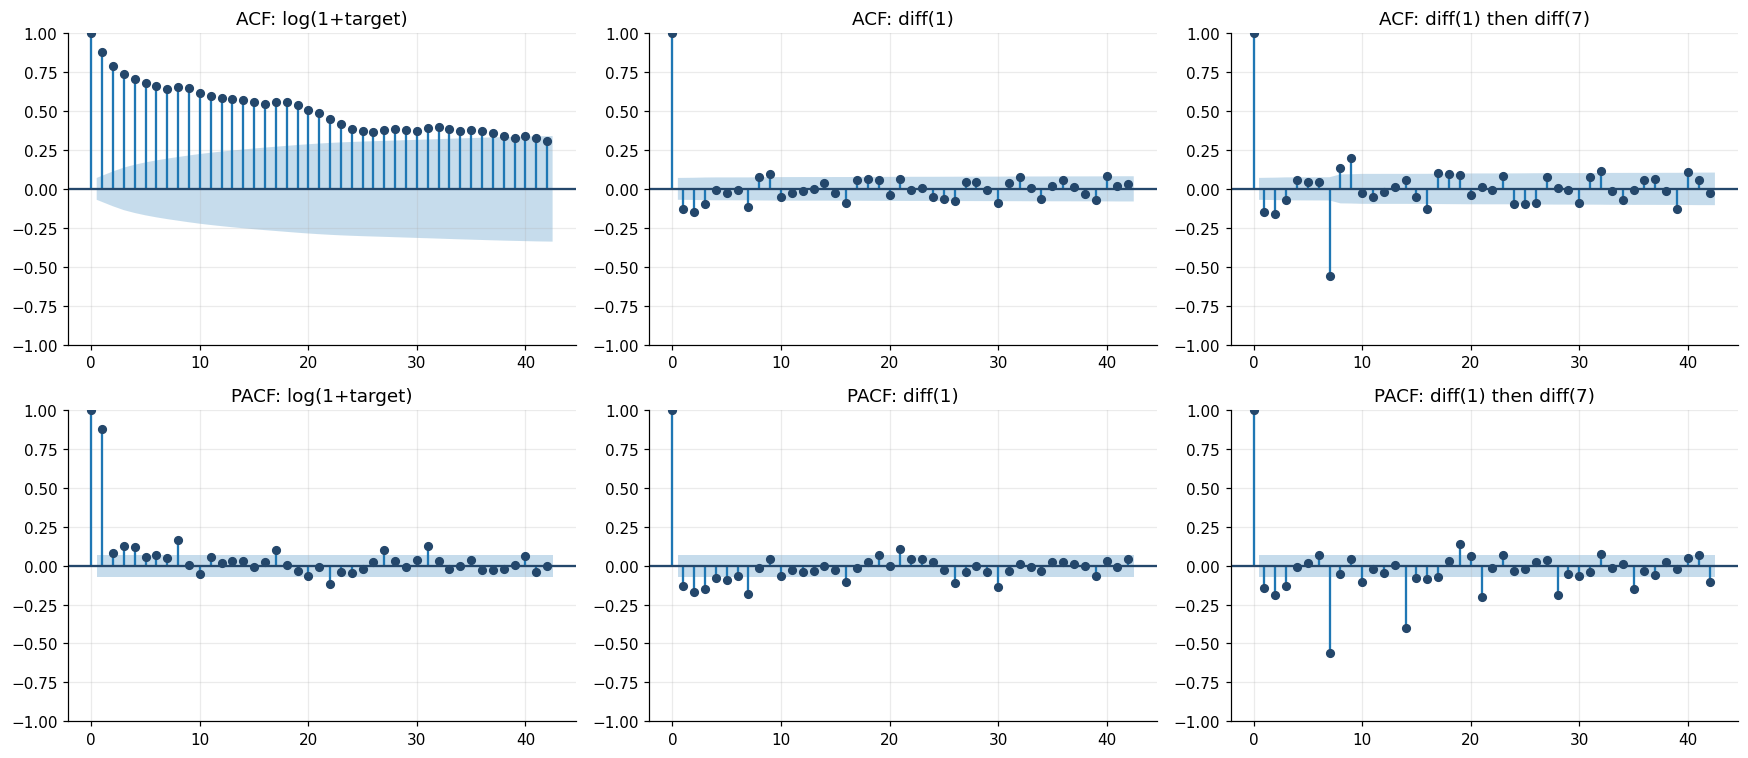

In [35]:
fig, axes = plt.subplots(2, 3, figsize=(16, 7))
for j, (name, x) in enumerate([("log(1+target)", ls), ("diff(1)", ls.diff().dropna()), ("diff(1) then diff(7)", ls.diff().diff(7).dropna())]):
    plot_acf(x, lags=42, ax=axes[0, j], color="#24476B")
    axes[0, j].set_title(f"ACF: {name}")
    plot_pacf(x, lags=42, ax=axes[1, j], color="#24476B", method="ywm")
    axes[1, j].set_title(f"PACF: {name}")
plt.tight_layout()
plt.show()

У рівнях ряд нестаціонарний: ADF відхиляє одиничний корінь (p = 0,026), але KPSS відхиляє стаціонарність (p ≈ 0,01). Така суперечлива пара типова для ряду з трендом і зсувами рівня. Після diff(1) обидва тести згодні, що ряд стаціонарний, тож для ARIMA беремо d = 1.

ACF рівнів спадає повільно (0,88 на лазі 1 і ≈ 0,3 на лазі 42), у PACF помітний майже лише лаг 1. Це схоже на випадкове блукання з великою інерцією, тому наївний прогноз «як учора» буде сильним бейзлайном на коротких горизонтах.

Сезонне диференціювання не потрібне: у diff(1) + diff(7) на лазі 7 з'являється різкий мінус (≈ −0,55), ознака надмірного диференціювання. Тижневий ефект краще закласти дамі-змінними за днем тижня.

## 1.7 Anomalies

In [36]:
own_price = competitors.set_index("date")["our_price"].copy()
suspect = own_price[(own_price > 400) & (own_price.index <= LAST_VALID)]
print("Weeks with the reconstructed own price above 400 $ inside the product life:")
display(suspect.round(2).to_frame("own price"))
print(f"Weeks with price > 400 $ after the data end ({LAST_VALID.date()}):", int((own_price[own_price.index > LAST_VALID] > 400).sum()),
      "of", int((own_price.index > LAST_VALID).sum()))
print("Distinct own-price values after the data end:", own_price[own_price.index > LAST_VALID].round(2).unique())

PRICE_LAST_REAL = pd.Timestamp("2019-12-01")
print("Reconstructed price, last real-looking weeks:")
print(own_price["2019-11-10":"2019-12-22"].round(2).to_dict())
placeholder_weeks = int((own_price.index > PRICE_LAST_REAL).sum())
own_price[own_price.index > PRICE_LAST_REAL] = np.nan
print(f"\nPlaceholder 422.78 $ starts the week after {PRICE_LAST_REAL.date()}; {placeholder_weeks} weeks set to NaN")

Weeks with the reconstructed own price above 400 $ inside the product life:


,own price
date,
2018-11-25,414.49
2019-12-08,422.78
2019-12-15,422.78
2019-12-22,422.78
2019-12-29,422.78
2020-01-05,422.78
2020-01-12,422.78
2020-01-19,422.78
2020-01-26,422.78


Weeks with price > 400 $ after the data end (2020-03-23): 40 of 40
Distinct own-price values after the data end: [422.78]
Reconstructed price, last real-looking weeks:
{Timestamp('2019-11-10 00:00:00'): 210.22, Timestamp('2019-11-17 00:00:00'): 219.74, Timestamp('2019-11-24 00:00:00'): 226.13, Timestamp('2019-12-01 00:00:00'): 226.34, Timestamp('2019-12-08 00:00:00'): 422.78, Timestamp('2019-12-15 00:00:00'): 422.78, Timestamp('2019-12-22 00:00:00'): 422.78}

Placeholder 422.78 $ starts the week after 2019-12-01; 56 weeks set to NaN


In [37]:
local_median = ls.rolling(29, center=True, min_periods=15).median()
dev = ls - local_median
dev = dev - dev.groupby(dev.index.dayofweek).transform("median")
mad = (dev - dev.median()).abs().median()
robust_z = (dev - dev.median()) / (1.4826 * mad)

THRESHOLD = 3.5
flag = robust_z.abs() > THRESHOLD

events = {
    "Black Friday 2017": ["2017-11-24"], "Cyber Monday 2017": ["2017-11-27"],
    "Black Friday 2018": ["2018-11-23"], "Cyber Monday 2018": ["2018-11-26"],
    "Black Friday 2019": ["2019-11-29"], "Cyber Monday 2019": ["2019-12-02"],
    "Prime Day 2018": ["2018-07-16", "2018-07-17"], "Prime Day 2019": ["2019-07-15", "2019-07-16"],
}
event_days = {pd.Timestamp(d): name for name, days in events.items() for d in days}

def near_event(d):
    for k, name in event_days.items():
        if abs((d - k).days) <= 1:
            return name
    return ""

price_asof = pd.merge_asof(
    pd.DataFrame({"date": ts.index}),
    own_price.dropna().rename("own_price").reset_index(),
    on="date", direction="backward",
).set_index("date")["own_price"]

anomalies = pd.DataFrame({
    "target": ts[flag],
    "local median": np.expm1(local_median[flag]).round(0),
    "ratio to median": (ts[flag] / np.expm1(local_median[flag])).round(2),
    "robust z": robust_z[flag].round(1),
    "own price (last known week)": price_asof[flag].round(0),
    "inventory_fba": daily.loc[flag[flag].index, "inventory_fba"].round(3),
    "near event": [near_event(d) for d in flag[flag].index],
})
print(f"Flagged days: {int(flag.sum())} of {len(ts)} (|robust z| > {THRESHOLD})")
display(anomalies)

anomalies["kind"] = np.where(anomalies["robust z"] > 0, "spike up", "drop down")
summary = anomalies.groupby("kind").agg(
    days=("target", "size"),
    share_with_fba_empty=("inventory_fba", lambda s: (s == 0).mean()),
    share_near_event=("near event", lambda s: (s != "").mean()),
)
display(summary.round(2))
fba_empty_all = (daily.loc[MODEL_START:MODEL_END, "inventory_fba"] == 0).mean()
print(f"For comparison: share of ALL days in the modelling window with inventory_fba = 0 is {fba_empty_all:.2f}")

Flagged days: 43 of 780 (|robust z| > 3.5)


,target,local median,ratio to median,robust z,own price (last known week),inventory_fba,near event
date,,,,,,,
2017-11-01,125.0,33.0,3.79,7.8,101.0,0.096,
2017-11-18,63.0,33.0,1.91,4.4,96.0,0.128,
2017-11-19,91.0,33.0,2.76,5.9,121.0,0.125,
2017-11-22,18.0,33.0,0.55,-3.6,121.0,0.000,
2017-11-23,7.0,33.0,0.21,-8.3,121.0,0.000,Black Friday 2017
2017-11-24,2.0,33.0,0.06,-14.5,121.0,0.000,Black Friday 2017
2017-11-25,0.0,33.0,0.00,-20.6,121.0,0.000,Black Friday 2017
2017-11-26,0.0,32.0,0.00,-21.1,111.0,0.000,Cyber Monday 2017
2017-11-27,14.0,32.0,0.44,-5.3,111.0,0.000,Cyber Monday 2017


,days,share_with_fba_empty,share_near_event
kind,,,
drop down,27,0.85,0.22
spike up,16,0.50,0.25


For comparison: share of ALL days in the modelling window with inventory_fba = 0 is 0.41


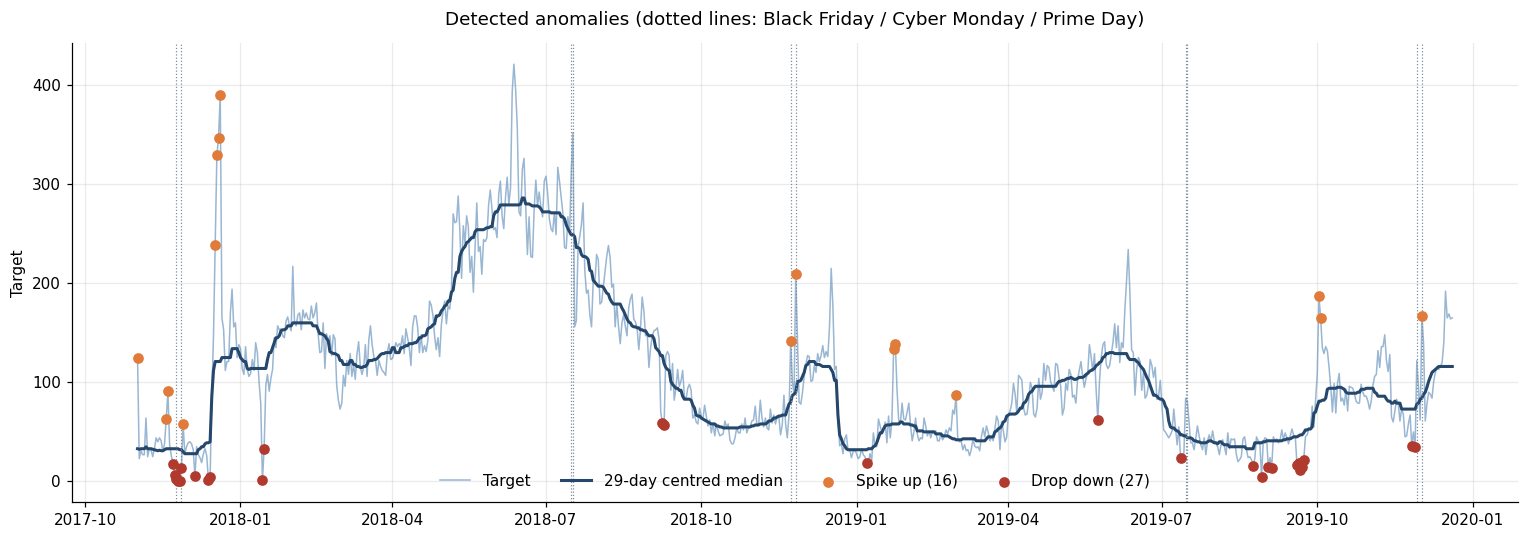

Flagged days within +-1 day of a known sales event: 10 of 43
Share of all days within +-1 day of such an event: 3.3%


In [38]:
fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(ts.index, ts.values, color="#5686B5", alpha=0.6, linewidth=1, label="Target")
ax.plot(np.expm1(local_median), color="#24476B", linewidth=2, label="29-day centred median")
up = flag & (robust_z > 0)
down = flag & (robust_z < 0)
ax.scatter(ts.index[up], ts[up], color="#E07B39", zorder=3, label=f"Spike up ({int(up.sum())})")
ax.scatter(ts.index[down], ts[down], color="#B03A2E", zorder=3, label=f"Drop down ({int(down.sum())})")
for d_, name in event_days.items():
    if MODEL_START <= d_ <= MODEL_END:
        ax.axvline(d_, color="#7A8A99", linewidth=0.8, linestyle=":")
ax.set_title("Detected anomalies (dotted lines: Black Friday / Cyber Monday / Prime Day)", pad=12)
ax.set_ylabel("Target")
ax.legend(frameon=False, ncol=4)
plt.tight_layout()
plt.show()

hits = anomalies["near event"].ne("").sum()
print(f"Flagged days within +-1 day of a known sales event: {hits} of {len(anomalies)}")
event_window = pd.Series(ts.index.map(lambda d: near_event(d) != ""), index=ts.index)
print(f"Share of all days within +-1 day of such an event: {event_window.mean():.1%}")

Аномалії шукаємо як відхилення log(1+y) від 29-денної центрованої медіани з поправкою на день тижня, поріг |z| > 3,5. Отримали 43 дні: 27 провалів і 16 сплесків. Максимум 421 (12.06.2018) не позначений, бо лежить на високому літньому плато.

Провали здебільшого пов'язані з відсутністю товару: 85% з них припадають на дні з inventory_fba = 0 (серед усіх днів таких 41%). Наприклад, Чорна п'ятниця 2017 (22–28.11.2017: 18, 7, 2, 0, 0, 14 продажів), 14–15.01.2018 і вересень 2019.

Сплески схожі на свята й акції: 17–20.12.2017 (239–390 на день перед Різдвом), Black Friday і Cyber Monday 2018 (142 і 209), Cyber Monday 2019 (167). Але лише 10 із 43 днів лежать у межах ±1 день від відомої події, тож власні акції, яких у даних немає, теж могли відіграти роль.

Ціна 414 $ у тиждень 25.11.2018 справжня (тиждень Чорної п'ятниці). А ось 422,78 $ починаючи з 08.12.2019 — заглушка, у ціні стоїть константа до кінця файлу. Ці тижні замінено на NaN, а в денному датасеті береться остання відома ціна з прапором price_imputed.

Аномалії не видаляємо, це реальні продажі. Позначаємо їх прапорами is_anomaly і near_event. Провали через відсутність товару — це цензурований попит, тому помилки моделей далі варто дивитися і з ними, і без них.

## 1.8 Missing values, zeros and placeholders

In [39]:
kw_cols = [c for c in daily.columns if c not in ["target", "inventory_fbm", "inventory_fba"]]
kw = daily[kw_cols]

TRACK_START = kw.index[(kw > 0).any(axis=1)][0]
TRACK_END = kw.index[(kw > 0).any(axis=1)][-1]
print("Search-position tracking starts:", TRACK_START.date(), "| last day with any non-zero position:", TRACK_END.date())
print("Target level in the 4 weeks around that date:", int(tgt.loc[TRACK_START - pd.Timedelta(days=14):TRACK_START + pd.Timedelta(days=14)].mean()), "units/day")

ranked_per_day = (kw > 0).sum(axis=1)
print(f"\nDays before tracking start with any non-zero keyword: {int((ranked_per_day[:TRACK_START - pd.Timedelta(days=1)] > 0).sum())}")
after = kw.loc[TRACK_START:TRACK_END]
coverage = (after > 0).mean().sort_values(ascending=False)
print(f"Keywords: {len(kw_cols)}; never non-zero after the start: {int((coverage == 0).sum())}; "
      f"non-zero less than 5% of days: {int((coverage < 0.05).sum())}; more than 50%: {int((coverage > 0.5).sum())}")
display(coverage.head(8).round(3).to_frame("share of days with non-zero position"))
print(f"Days inside the tracking window with ALL keywords equal to 0: {int((ranked_per_day.loc[TRACK_START:TRACK_END] == 0).sum())}")
print(f"Days after {TRACK_END.date()} up to {MODEL_END.date()} (all keywords 0, tracking is over): {(MODEL_END - TRACK_END).days}")

Search-position tracking starts:

 2018-05-28 | last day with any non-zero position: 2019-06-29
Target level in the 4 weeks around that date: 262 units/day

Days before tracking start with any non-zero keyword: 0
Keywords: 50; never non-zero after the start: 5; non-zero less than 5% of days: 5; more than 50%: 44


,share of days with non-zero position
clear ice maker,0.997
small ice machine,0.997
ice maker countertop,0.995
table top ice maker machine,0.995
ice machine portable,0.995
ice machine maker,0.995
small ice maker,0.995
ice machine countertop,0.992


Days inside the tracking window with ALL keywords equal to 0: 0
Days after 2019-06-29 up to 2019-12-20 (all keywords 0, tracking is over): 174


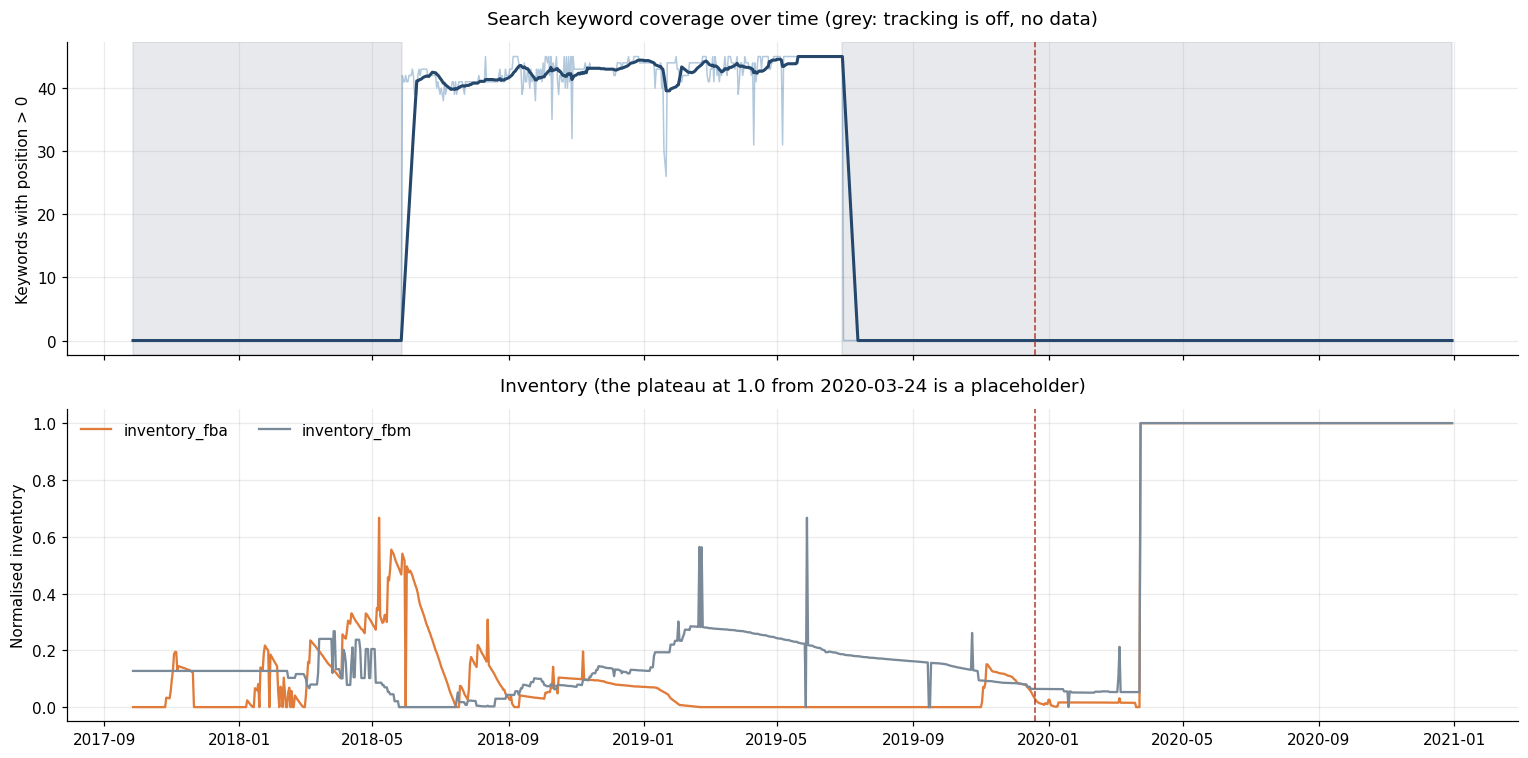

In [40]:
fig, axes = plt.subplots(2, 1, figsize=(14, 7), sharex=True)

axes[0].plot(ranked_per_day.index, ranked_per_day, color="#5686B5", alpha=0.45, linewidth=1)
axes[0].plot(ranked_per_day.rolling(14, min_periods=1).mean(), color="#24476B", linewidth=2)
axes[0].axvspan(daily.index.min(), TRACK_START, color="#7A8A99", alpha=0.18)
axes[0].axvspan(TRACK_END, daily.index.max(), color="#7A8A99", alpha=0.18)
axes[0].axvline(MODEL_END, color="#B03A2E", linestyle="--", linewidth=1)
axes[0].set_ylabel("Keywords with position > 0")
axes[0].set_title("Search keyword coverage over time (grey: tracking is off, no data)", pad=12)

axes[1].plot(daily["inventory_fba"], color="#E07B39", label="inventory_fba")
axes[1].plot(daily["inventory_fbm"], color="#7A8A99", label="inventory_fbm")
axes[1].axvline(MODEL_END, color="#B03A2E", linestyle="--", linewidth=1)
axes[1].set_ylabel("Normalised inventory")
axes[1].set_title("Inventory (the plateau at 1.0 from 2020-03-24 is a placeholder)", pad=12)
axes[1].legend(frameon=False, ncol=2)

plt.tight_layout()
plt.show()

,days,mean,median
fba_group,,,
0 (empty),323,80.8,71.0
"(0, 0.05]",93,106.5,93.0
"(0.05, 0.25]",286,113.2,108.0
"(0.25, 1]",78,222.7,230.5


Pearson correlation of target with inventory_fba: 0.576 | Spearman: 0.456
Pearson correlation of target with inventory_fbm: -0.515 | Spearman: -0.469


date,2017-11-01,2017-12-01,2018-01-01,2018-02-01,2018-03-01,2018-04-01,2018-05-01,2018-06-01,2018-07-01,2018-08-01,...,2019-03-01,2019-04-01,2019-05-01,2019-06-01,2019-07-01,2019-08-01,2019-09-01,2019-10-01,2019-11-01,2019-12-01
sales,1061.00,3504.00,3724.00,4272.00,3644.00,4333.00,7276.00,8760.00,7616.00,5424.00,...,1365.00,2733.00,3268.00,3824.0,1463.00,1031.00,1217.00,3108.00,2607.00,2440.00
fba_mean,0.09,0.00,0.07,0.05,0.16,0.27,0.41,0.34,0.07,0.13,...,0.00,0.00,0.00,0.0,0.00,0.00,0.00,0.00,0.11,0.07
fba_empty_share,0.33,1.00,0.32,0.29,0.03,0.00,0.03,0.00,0.10,0.00,...,1.00,1.00,1.00,1.0,1.00,1.00,1.00,1.00,0.03,0.00
fbm_mean,0.13,0.13,0.13,0.12,0.16,0.15,0.06,0.00,0.01,0.02,...,0.27,0.26,0.24,0.2,0.18,0.17,0.15,0.14,0.09,0.08


inventory_fbm changes value on 451 of 780 days; inventory_fba on 450 days


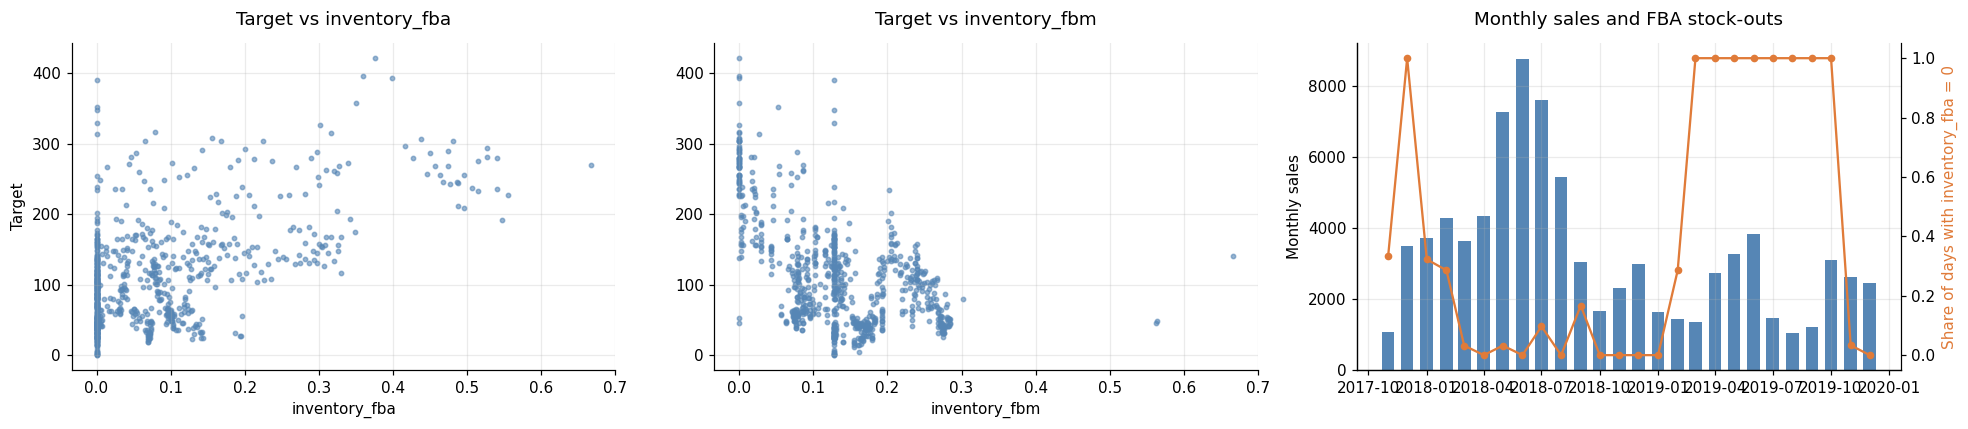

In [41]:
inv = daily.loc[MODEL_START:MODEL_END, ["inventory_fbm", "inventory_fba"]].join(ts.rename("target"))
inv["fba_group"] = pd.cut(inv["inventory_fba"], bins=[-0.001, 0.0, 0.05, 0.25, 1.0], labels=["0 (empty)", "(0, 0.05]", "(0.05, 0.25]", "(0.25, 1]"])
display(inv.groupby("fba_group", observed=True)["target"].agg(days="size", mean="mean", median="median").round(1))
print("Pearson correlation of target with inventory_fba:", round(inv["target"].corr(inv["inventory_fba"]), 3),
      "| Spearman:", round(inv["target"].corr(inv["inventory_fba"], method="spearman"), 3))
print("Pearson correlation of target with inventory_fbm:", round(inv["target"].corr(inv["inventory_fbm"]), 3),
      "| Spearman:", round(inv["target"].corr(inv["inventory_fbm"], method="spearman"), 3))

monthly_inv = ds_tmp = daily.loc[MODEL_START:MODEL_END].resample("MS").agg(
    sales=("target", "sum"),
    fba_mean=("inventory_fba", "mean"),
    fba_empty_share=("inventory_fba", lambda s: (s == 0).mean()),
    fbm_mean=("inventory_fbm", "mean"),
)
display(monthly_inv.round(2).T)

fbm_changes = (daily["inventory_fbm"].loc[MODEL_START:MODEL_END].diff() != 0).sum()
print(f"inventory_fbm changes value on {fbm_changes} of {len(inv)} days; inventory_fba on "
      f"{(daily['inventory_fba'].loc[MODEL_START:MODEL_END].diff() != 0).sum()} days")

fig, axes = plt.subplots(1, 3, figsize=(18, 4))
axes[2].bar(monthly_inv.index, monthly_inv["sales"], width=20, color="#5686B5")
axes[2].set_ylabel("Monthly sales")
ax_e = axes[2].twinx()
ax_e.plot(monthly_inv.index, monthly_inv["fba_empty_share"], color="#E07B39", marker="o", markersize=4)
ax_e.set_ylabel("Share of days with inventory_fba = 0", color="#E07B39")
ax_e.spines["right"].set_visible(True)
ax_e.grid(False)
axes[2].set_title("Monthly sales and FBA stock-outs", pad=12)
axes[0].scatter(inv["inventory_fba"], inv["target"], s=8, color="#5686B5", alpha=0.6)
axes[0].set_xlabel("inventory_fba")
axes[0].set_ylabel("Target")
axes[0].set_title("Target vs inventory_fba", pad=12)
axes[1].scatter(inv["inventory_fbm"], inv["target"], s=8, color="#5686B5", alpha=0.6)
axes[1].set_xlabel("inventory_fbm")
axes[1].set_title("Target vs inventory_fbm", pad=12)
plt.tight_layout()
plt.show()

Справжні пропуски є лише в target (282 NaN після 23.03.2020), їх відрізаємо. Решта пропусків прихована в нулях ключових слів і в заглушках.

Позиції за ключовими словами відстежувалися тільки з 28.05.2018 по 29.06.2019 (398 днів, 51% робочого вікна). Поза цим інтервалом нуль означає «не вимірювали». Усередині немає жодного дня, коли всі слова нульові, 44 з 50 колонок ненульові понад 50% днів, а 5 колонок завжди нульові (їх прибираємо). Тому ключові слова використовуємо лише для цієї підвибірки, а поза нею ставимо NaN і прапор kw_tracked = 0.

Склад впливає на продажі сильно: FBA порожній у 41% днів, і тоді середні продажі 80,8 на день проти 222,7 при inventory_fba > 0,25. Кореляція target з inventory_fba +0,58, з inventory_fbm −0,52 (коли FBA закінчується, відправка йде зі складу продавця).

З березня по жовтень 2019 FBA порожній щодня, а продажі в 2–3 рази нижчі за пік 2018 (1–3,8 тис. на місяць проти 8,8 тис., коли FBA було 0,34–0,41). Тобто падіння 2019 року не можна повністю віднести до попиту. Розділити ці причини з наявних даних неможливо.

inventory — стан складу, а не календар: майбутні значення на момент прогнозу невідомі, тому використовуємо лише лаги або явний сценарій.

## 1.9 Relations between the files

In [42]:
orders_daily = orders.groupby("date").agg(order_rows=("count", "size"), order_units=("count", "sum"))
cmp = ts.rename("target").to_frame().join(orders_daily, how="left")

print("Days of the modelling window absent from orders:", int(cmp["order_rows"].isna().sum()), "of", len(cmp))
print("Target on those days: mean =", round(cmp.loc[cmp["order_rows"].isna(), "target"].mean(), 1),
      "| zeros =", int((cmp.loc[cmp["order_rows"].isna(), "target"] == 0).sum()))

full = cmp.dropna()
print()
for col in ["order_units", "order_rows"]:
    r = (full["target"] / full[col])
    print(f"target / {col:12s}: median = {r.median():.3f}, mean = {r.mean():.3f}, IQR = [{r.quantile(.25):.3f}, {r.quantile(.75):.3f}], "
          f"corr(target, {col}) = {full['target'].corr(full[col]):.3f}")
print()
print("Total over the common days: target =", int(full['target'].sum()), "| order rows =", int(full['order_rows'].sum()), "| order units =", int(full['order_units'].sum()))

Days of the modelling window absent from orders: 2 of 780
Target on those days: mean = 0.0 | zeros = 2

target / order_units : median = 0.878, mean = 0.765, IQR = [0.498, 0.970], corr(target, order_units) = 0.955
target / order_rows  : median = 1.000, mean = 0.998, IQR = [0.981, 1.012], corr(target, order_rows) = 0.999

Total over the common days: target = 85738 | order rows = 85768 | order units = 138890


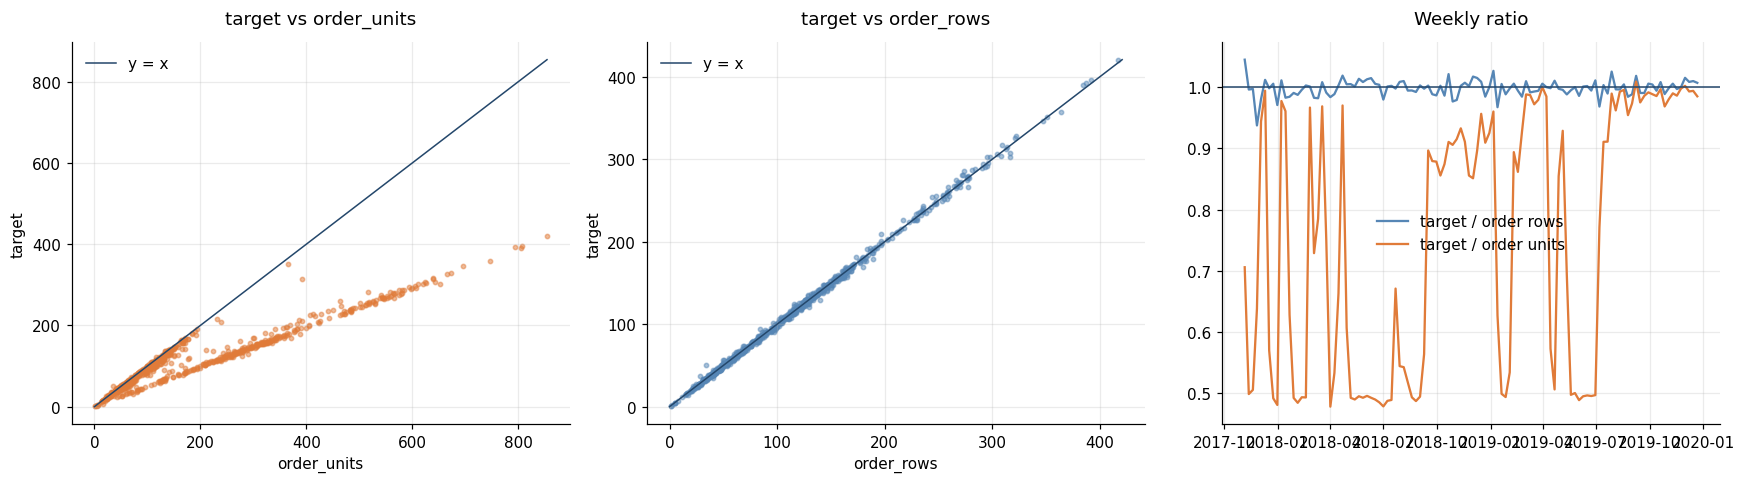

Cross-correlation of daily target and order rows (target at t vs rows at t+k):
{-3: np.float64(0.856), -2: np.float64(0.889), -1: np.float64(0.94), 0: np.float64(0.999), 1: np.float64(0.94), 2: np.float64(0.889), 3: np.float64(0.856)}


,orders,units,mean_units_per_order
year,,,
2017,8120,15693,1.93
2018,55042,94678,1.72
2019,26570,36105,1.36
2020,202,204,1.01


Share of orders by warehouse and year, %


year,2017,2018,2019,2020
warehouse_zip,,,,
12189,6.0,6.4,6.5,9.4
17202,28.7,27.0,30.4,25.7
46168,24.4,22.3,23.3,19.3
75236,13.8,15.2,14.0,19.3
89434,12.0,13.6,12.9,9.9
91761,13.0,13.5,12.7,16.3
99999,2.0,2.0,0.3,NaN


In [43]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, col, color in [(axes[0], "order_units", "#E07B39"), (axes[1], "order_rows", "#5686B5")]:
    ax.scatter(full[col], full["target"], s=8, alpha=0.5, color=color)
    lim = max(full[col].max(), full["target"].max())
    ax.plot([0, lim], [0, lim], color="#24476B", linewidth=1, label="y = x")
    ax.set_xlabel(col)
    ax.set_ylabel("target")
    ax.set_title(f"target vs {col}", pad=12)
    ax.legend(frameon=False)

ratio_week = (full["target"].resample("W-SUN").sum() / full["order_rows"].resample("W-SUN").sum())
ratio_week_units = (full["target"].resample("W-SUN").sum() / full["order_units"].resample("W-SUN").sum())
axes[2].plot(ratio_week, color="#5686B5", label="target / order rows")
axes[2].plot(ratio_week_units, color="#E07B39", label="target / order units")
axes[2].axhline(1, color="#24476B", linewidth=1)
axes[2].set_title("Weekly ratio", pad=12)
axes[2].legend(frameon=False)
plt.tight_layout()
plt.show()

print("Cross-correlation of daily target and order rows (target at t vs rows at t+k):")
cc = {k: ts.corr(orders_daily["order_rows"].reindex(ts.index).shift(-k)) for k in range(-3, 4)}
print({k: round(v, 3) for k, v in cc.items()})

units_per_order = orders.assign(year=orders["date"].dt.year).groupby("year")["count"].agg(orders="size", units="sum", mean_units_per_order="mean")
display(units_per_order.round(2))
wh_share = (orders.assign(year=orders["date"].dt.year).pivot_table(index="warehouse_zip", columns="year", values="count", aggfunc="size")
            .pipe(lambda t: t / t.sum()) * 100)
print("Share of orders by warehouse and year, %")
display(wh_share.round(1))

target виявився кількістю замовлень (рядків orders) за день, а не штуками. Відношення target до кількості рядків має медіану 1,000 (IQR 0,98–1,01), кореляція 0,999, суми 85 738 і 85 768. Два дні вікна, яких немає в orders, це рівно два нульові дні target. Раніше помічене нестале відношення ≈ 1,13 було порівнянням зі штуками.

Колонка count в orders — штуки в замовленні: 59% замовлень по 2 штуки, 39% по одній. Середнє по кварталах падає з ≈ 2,0 у 2017 до ≈ 1,0 у другій половині 2019, відповідно відношення target / order_units перемикається між 0,5 і 1,0. Імовірно, лістинг продавали то набором із двох, то поодинці (це гіпотеза). Для запасів важливі штуки: штуки = target × штук на замовлення.

Окремої інформації про кількість продажів orders не дає, тому order_rows і order_units того ж дня в модель не подаємо (це був би витік цілі) і в датасеті називаємо з префіксом leak_. Корисна частина orders — склади й географія. Частки складів стабільні: 17202 ≈ 27–30%, 46168 ≈ 22–24%, 75236 ≈ 14–15%, 89434 ≈ 12–14%, 91761 ≈ 13%, 12189 ≈ 6%, 99999 (невідомий) ≈ 2%.

Correlation of the aggregated keyword features with target (2018-05-28 - 2019-06-29, 398 days):


,n,Pearson,Spearman,Kendall
feature,,,,
kw_n_ranked,398,-0.256,-0.288,-0.203
kw_best,398,-0.445,-0.325,-0.241
kw_mean,398,-0.425,-0.438,-0.302


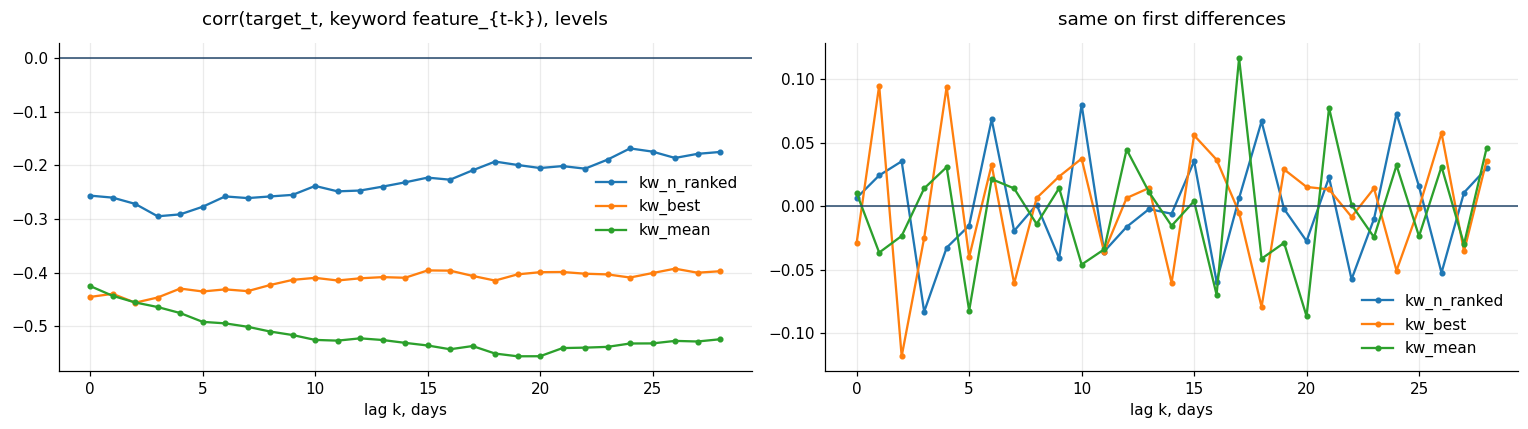

In [44]:
kw_win = kw.loc[MODEL_START:MODEL_END]
kw_pos = kw_win.where(kw_win > 0)

kw_agg = pd.DataFrame({
    "kw_n_ranked": (kw_win > 0).sum(axis=1),
    "kw_best": kw_pos.min(axis=1),
    "kw_mean": kw_pos.mean(axis=1),
})
kw_agg.loc[(kw_agg.index < TRACK_START) | (kw_agg.index > TRACK_END)] = np.nan

sub = kw_agg.join(ts.rename("target")).loc[TRACK_START:TRACK_END]
print(f"Correlation of the aggregated keyword features with target ({TRACK_START.date()} - {TRACK_END.date()}, {len(sub)} days):")
rows = []
for c in ["kw_n_ranked", "kw_best", "kw_mean"]:
    s_ = sub[[c, "target"]].dropna()
    rows.append({"feature": c, "n": len(s_),
                 "Pearson": s_[c].corr(s_["target"]),
                 "Spearman": s_[c].corr(s_["target"], method="spearman"),
                 "Kendall": s_[c].corr(s_["target"], method="kendall")})
display(pd.DataFrame(rows).set_index("feature").round(3))

lags = range(0, 29)
lag_corr = pd.DataFrame({
    c: [sub["target"].corr(sub[c].shift(k)) for k in lags] for c in ["kw_n_ranked", "kw_best", "kw_mean"]
}, index=lags)
lag_corr_diff = pd.DataFrame({
    c: [sub["target"].diff().corr(sub[c].diff().shift(k)) for k in lags] for c in ["kw_n_ranked", "kw_best", "kw_mean"]
}, index=lags)

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
lag_corr.plot(ax=axes[0], marker="o", markersize=3)
axes[0].set_title("corr(target_t, keyword feature_{t-k}), levels", pad=12)
axes[0].set_xlabel("lag k, days")
lag_corr_diff.plot(ax=axes[1], marker="o", markersize=3)
axes[1].set_title("same on first differences", pad=12)
axes[1].set_xlabel("lag k, days")
for ax in axes:
    ax.axhline(0, color="#24476B", linewidth=1)
    ax.legend(frameon=False)
plt.tight_layout()
plt.show()

Кореляції в розділі 1.2 (до 0,32 для best ice machine) пораховані на всьому періоді разом з нулями до старту трекінгу, тому тут вони перераховані тільки по днях зі спостереженнями.

Усередині вікна трекінгу (398 днів) що менше число позиції, то більше продажів: kw_best (найкраща позиція серед слів у видачі) має Pearson −0,45, Spearman −0,33, Kendall −0,24, kw_mean −0,43 / −0,44 / −0,30, кількість слів у видачі kw_n_ranked −0,26. Тобто менше число означає кращу позицію. Якщо помилково взяти 174 дні без трекінгу за нулі, kw_n_ranked змінює знак на +0,28.

Лагової структури немає: кореляція рівнів плоска (від −0,4 до −0,55 на лагах 0–28), а на різницях усе в межах ±0,12, тобто шум. Ключові слова відображають рівень, а не випереджають добові зміни продажів. До того ж позиція сама залежить від продажів, тому в моделі лише з лагом не меншим за горизонт.

In [45]:
comp_prices = competitors.set_index("date")[price_cols]
comp_week = pd.DataFrame({
    "own_price": own_price,
    "comp_mean": comp_prices.mean(axis=1),
    "comp_min": comp_prices.min(axis=1),
})
comp_week = comp_week.loc[:MODEL_END].dropna()
comp_week["price_ratio"] = comp_week["own_price"] / comp_week["comp_mean"]

target_week = ts.resample("W-SUN").agg(["sum", "count"])
target_week = target_week[target_week["count"] == 7]["sum"].rename("target_week")
pw = comp_week.join(target_week, how="inner")
pw = pw[pw["target_week"] > 0]
print(f"Weeks with both price and complete sales: {len(pw)}")

lp, ly = np.log(pw["own_price"]), np.log(pw["target_week"])
lr = np.log(pw["price_ratio"])
rows = []
for name, x in [("log own price", lp), ("log price ratio (own / competitors)", lr)]:
    rows.append({"feature": name, "Pearson": x.corr(ly), "Spearman": x.corr(ly, method="spearman"), "Kendall": x.corr(ly, method="kendall")})
display(pd.DataFrame(rows).set_index("feature").round(3))
print("(each row: correlation with log weekly sales)")

dp = lp.diff()
dy = ly.diff()
print("\nFirst differences (week-to-week changes), corr(d log sales_t, d log price_{t-k}):")
print({k: round(dy.corr(dp.shift(k)), 3) for k in (-2, -1, 0, 1, 2)})
print("(k > 0: price change k weeks earlier; k < 0: price change in later weeks)")
print("\nCorrelation by year (log own price vs log weekly sales):")
print(pd.Series({y: lp[lp.index.year == y].corr(ly[ly.index.year == y]) for y in (2017, 2018, 2019)}).round(3).to_dict())

Weeks with both price and complete sales: 108


,Pearson,Spearman,Kendall
feature,,,
log own price,-0.155,-0.202,-0.143
log price ratio (own / competitors),-0.230,-0.260,-0.197


(each row: correlation with log weekly sales)

First differences (week-to-week changes), corr(d log sales_t, d log price_{t-k}):
{-2: np.float64(-0.112), -1: np.float64(0.027), 0: np.float64(0.07), 1: np.float64(-0.14), 2: np.float64(0.153)}
(k > 0: price change k weeks earlier; k < 0: price change in later weeks)

Correlation by year (log own price vs log weekly sales):
{2017: 0.602, 2018: -0.718, 2019: 0.221}


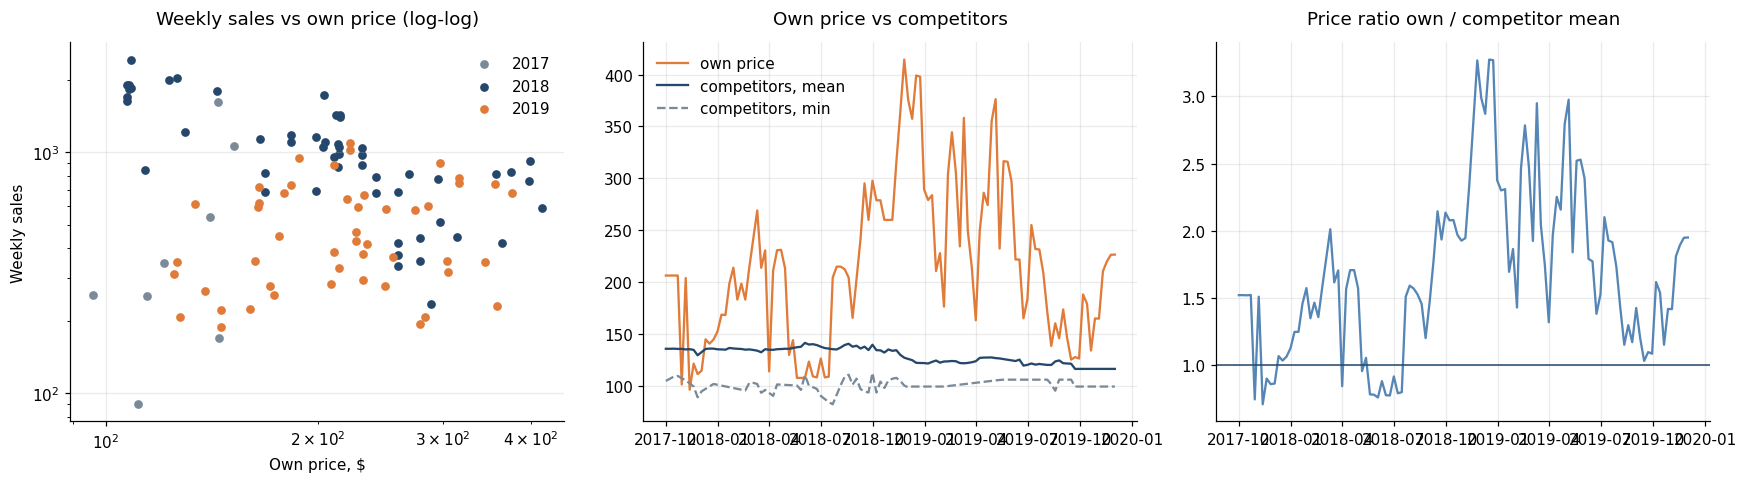

In [46]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for y, color in zip((2017, 2018, 2019), ("#7A8A99", "#24476B", "#E07B39")):
    m = pw.index.year == y
    axes[0].scatter(pw.loc[m, "own_price"], pw.loc[m, "target_week"], color=color, s=22, label=str(y))
axes[0].set_xscale("log"); axes[0].set_yscale("log")
axes[0].set_xlabel("Own price, $"); axes[0].set_ylabel("Weekly sales")
axes[0].set_title("Weekly sales vs own price (log-log)", pad=12)
axes[0].legend(frameon=False)

axes[1].plot(comp_week["own_price"], color="#E07B39", label="own price")
axes[1].plot(comp_week["comp_mean"], color="#24476B", label="competitors, mean")
axes[1].plot(comp_week["comp_min"], color="#7A8A99", label="competitors, min", linestyle="--")
axes[1].set_title("Own price vs competitors", pad=12)
axes[1].legend(frameon=False)

axes[2].plot(comp_week["price_ratio"], color="#5686B5")
axes[2].axhline(1, color="#24476B", linewidth=1)
axes[2].set_title("Price ratio own / competitor mean", pad=12)
plt.tight_layout()
plt.show()

У 2018–2019 роках наша ціна зазвичай у 1,3–3 рази вища за середню ціну конкурентів (відношення від 0,7 до 3,3), а ціни конкурентів поступово падали (≈ 135 → 117 $). Власна ціна змінювалась майже щотижня в межах 96–414 $.

Залежність продажів від ціни слабка й нестабільна. По 108 тижнях кореляція log-log −0,16 (Pearson), −0,20 (Spearman), −0,14 (Kendall), для відношення цін −0,23 / −0,26 / −0,20. По роках знак міняється: 2017 +0,60, 2018 −0,72, 2019 +0,22. На тижневих різницях кореляція ≈ 0,07.

Тому просту еластичність з цих даних не оцінити: ціна збігається із сезоном (низька ціна в літній пік 2018), з наявністю на FBA і з запуском. Це обмеження для оптимізації.

## 1.10 Aggregation and the modelling datasets

In [47]:
calendar = pd.DataFrame(index=ts.index)
calendar["dow"] = calendar.index.dayofweek
calendar["month"] = calendar.index.month
calendar["week_of_year"] = calendar.index.isocalendar().week.astype(int).values
calendar["days_since_launch"] = (calendar.index - FIRST_SALE).days
calendar["near_event"] = [int(near_event(d) != "") for d in calendar.index]

price_daily = pd.merge_asof(
    pd.DataFrame({"date": ts.index}),
    comp_week.reset_index()[["date", "own_price", "comp_mean", "comp_min", "price_ratio"]],
    on="date", direction="backward",
).set_index("date")

ds = pd.DataFrame({"target": ts, "log_target": np.log1p(ts)})
ds = ds.join(daily[["inventory_fbm", "inventory_fba"]]).join(kw_agg).join(price_daily).join(calendar)
ds["kw_tracked"] = ((ds.index >= TRACK_START) & (ds.index <= TRACK_END)).astype(int)
ds["price_imputed"] = (ds.index > PRICE_LAST_REAL + pd.Timedelta(days=7)).astype(int)
ds["is_anomaly"] = flag.reindex(ds.index).astype(int)
ds["leak_order_rows"] = orders_daily["order_rows"].reindex(ds.index)
ds["leak_order_units"] = orders_daily["order_units"].reindex(ds.index)

print("Daily dataset:", ds.shape, "|", ds.index.min().date(), "-", ds.index.max().date())
display(pd.DataFrame({"missing": ds.isna().sum(), "missing %": (ds.isna().mean() * 100).round(1)}).T)
display(ds.head(3).round(3))

Daily dataset: (780, 21) | 2017-11-01 - 2019-12-20


,target,log_target,inventory_fbm,inventory_fba,kw_n_ranked,kw_best,kw_mean,own_price,comp_mean,comp_min,...,dow,month,week_of_year,days_since_launch,near_event,kw_tracked,price_imputed,is_anomaly,leak_order_rows,leak_order_units
missing,0.0,0.0,0.0,0.0,382.0,382.0,382.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2.0,2.0
missing %,0.0,0.0,0.0,0.0,49.0,49.0,49.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.3,0.3


,target,log_target,inventory_fbm,inventory_fba,kw_n_ranked,kw_best,kw_mean,own_price,comp_mean,comp_min,...,dow,month,week_of_year,days_since_launch,near_event,kw_tracked,price_imputed,is_anomaly,leak_order_rows,leak_order_units
date,,,,,,,,,,,,,,,,,,,,,
2017-11-01,125.0,4.836,0.127,0.096,NaN,NaN,NaN,100.994,135.326,106.99,...,2,11,44,6,0,0,0,1,116.0,151.0
2017-11-02,23.0,3.178,0.127,0.129,NaN,NaN,NaN,100.994,135.326,106.99,...,3,11,44,7,0,0,0,0,22.0,43.0
2017-11-03,31.0,3.466,0.127,0.186,NaN,NaN,NaN,100.994,135.326,106.99,...,4,11,44,8,0,0,0,0,30.0,53.0


In [48]:
ws = ds.resample("W-SUN").agg(
    days=("target", "size"),
    target=("target", "sum"),
    inventory_fbm=("inventory_fbm", "mean"),
    inventory_fba=("inventory_fba", "mean"),
    kw_n_ranked=("kw_n_ranked", "mean"),
    anomalies=("is_anomaly", "sum"),
)
ws = ws[ws["days"] == 7].drop(columns="days")
ws = ws.join(comp_week[["own_price", "comp_mean", "comp_min", "price_ratio"]], how="left")
ws["log_target"] = np.log1p(ws["target"])

print("Weekly dataset:", ws.shape, "|", ws.index.min().date(), "-", ws.index.max().date())
display(pd.DataFrame({"missing": ws.isna().sum()}).T)

ds.to_csv("daily_dataset.csv", index_label="date")
ws.to_csv("weekly_dataset.csv", index_label="week_end")
print("Saved: daily_dataset.csv, weekly_dataset.csv")

Weekly dataset: (110, 10) | 2017-11-12 - 2019-12-15


,target,inventory_fbm,inventory_fba,kw_n_ranked,anomalies,own_price,comp_mean,comp_min,price_ratio,log_target
missing,0,0,0,53,0,2,2,2,2,0


Saved: daily_dataset.csv, weekly_dataset.csv


In [49]:
def naive_relative_error(x, lag):
    return (x - x.shift(lag)).abs().mean() / x.mean()

gran = pd.DataFrame({
    "daily": {
        "observations": len(ds),
        "coefficient of variation": ds["target"].std() / ds["target"].mean(),
        "naive 'same as last period' |error| / mean": naive_relative_error(ds["target"], 1),
        "weekly-seasonal naive |error| / mean": naive_relative_error(ds["target"], 7),
        "share of zero periods": (ds["target"] == 0).mean(),
    },
    "weekly": {
        "observations": len(ws),
        "coefficient of variation": ws["target"].std() / ws["target"].mean(),
        "naive 'same as last period' |error| / mean": naive_relative_error(ws["target"], 1),
        "weekly-seasonal naive |error| / mean": np.nan,
        "share of zero periods": (ws["target"] == 0).mean(),
    },
}).round(3)
display(gran)

,daily,weekly
observations,780.000,110.000
coefficient of variation,0.681,0.646
naive 'same as last period' |error| / mean,0.156,0.190
weekly-seasonal naive |error| / mean,0.268,NaN
share of zero periods,0.003,0.000


Зібрано два датасети: daily_dataset.csv (780 днів × 21 колонка) і weekly_dataset.csv (110 повних тижнів, W-SUN). У них є log_target, inventory, kw_* (NaN поза вікном трекінгу), ціни, календар, near_event і is_anomaly. Тижнева ціна переноситься на дні через merge_asof(direction="backward"), тобто береться остання відома неділя без заглядання вперед. Для днів після 08.12.2019 стоїть прапор price_imputed. Колонки leak_* лишаємо тільки для діагностики.

Основна гранулярність — день: для горизонтів 7–28 днів потрібен добовий профіль (понеділок і субота відрізняються на ±12%), і точок значно більше (780 проти 110). Тижневий ряд лишаємо для перевірки стійкості й для оптимізації.

Агрегація шум майже не зменшує: CV тижневого ряду 0,65 проти 0,68 денного. Наївний прогноз «як учора» помиляється в середньому на 15,6% рівня на день, «як минулого тижня» на 19% для тижневих даних, а «як 7 днів тому» на 26,8% для денних. Інерція важливіша за тижневу сезонність.

Підсумок розділу 1.

| Питання | Рішення |
|---|---|
| Робоче вікно | 01.11.2017 – 20.12.2019, 780 днів |
| Перетворення | log(1+y) для ETS/ARIMA, сирий target для дерев і метрик |
| Основна частота | день, тижневий ряд для перевірки |
| Аномалії | не видаляємо, прапори is_anomaly і near_event |
| Пропуски | NaN у ключових словах поза 28.05.2018 – 29.06.2019, ціна після 01.12.2019 замінена останньою відомою |
| Ознаки з майбутнім | заборонені inventory, ціна, ключові слова та orders того ж дня; дозволені значення на момент origin |
| Файл orders | target = кількість його рядків, тому як ознака не потрібен |

# 2. Validation scheme

Схема будується навколо простої ідеї: у кінці дня T ми знаємо все до T включно і прогнозуємо наступні дні. Звідси origin (день T), горизонт H, бектест, який зсуває T по історії, і перевірка кожної колонки на витік.

## 2.1 Forecasting horizon

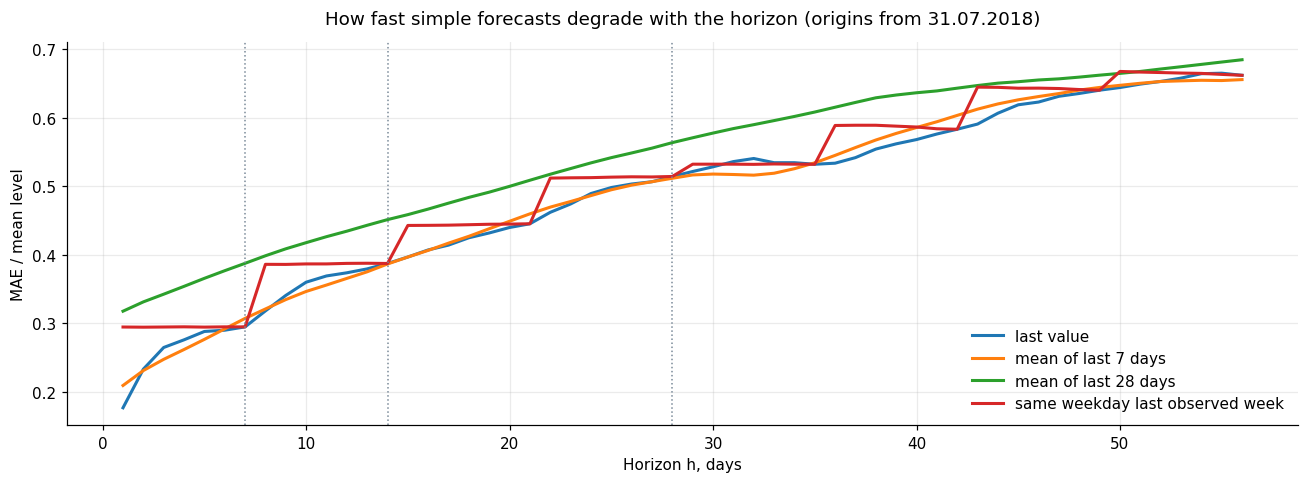

,last value,mean of last 7 days,mean of last 28 days,same weekday last observed week
h,,,,
1,0.177,0.209,0.318,0.295
3,0.265,0.248,0.343,0.295
7,0.295,0.307,0.388,0.295
14,0.387,0.387,0.451,0.387
21,0.445,0.460,0.509,0.445
28,0.514,0.512,0.564,0.514
42,0.583,0.603,0.643,0.583
56,0.662,0.655,0.684,0.662


Share of weeks in which the own price changed: 91%


In [50]:
y = ds["target"]
FIRST_TEST_START = pd.Timestamp("2018-08-01")
H_MAX = 56
level = y.loc[FIRST_TEST_START:].mean()

rows = []
for h in range(1, H_MAX + 1):
    origins = y.index[(y.index >= FIRST_TEST_START - pd.Timedelta(days=1)) & (y.index + pd.Timedelta(days=h) <= y.index[-1])]
    target_dates = origins + pd.Timedelta(days=h)
    actual = y.reindex(target_dates).values
    last = y.reindex(origins).values
    mean7 = y.rolling(7).mean().reindex(origins).values
    mean28 = y.rolling(28).mean().reindex(origins).values
    seas = y.reindex(target_dates - pd.Timedelta(days=7 * int(np.ceil(h / 7)))).values
    rows.append({
        "h": h,
        "last value": np.mean(np.abs(actual - last)),
        "mean of last 7 days": np.mean(np.abs(actual - mean7)),
        "mean of last 28 days": np.mean(np.abs(actual - mean28)),
        "same weekday last observed week": np.mean(np.abs(actual - seas)),
    })
horizon_curve = pd.DataFrame(rows).set_index("h") / level

fig, ax = plt.subplots(figsize=(12, 4.5))
horizon_curve.plot(ax=ax, linewidth=2)
for h_ in (7, 14, 28):
    ax.axvline(h_, color="#7A8A99", linestyle=":", linewidth=1)
ax.set_xlabel("Horizon h, days")
ax.set_ylabel("MAE / mean level")
ax.set_title("How fast simple forecasts degrade with the horizon (origins from 31.07.2018)", pad=12)
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

display(horizon_curve.loc[[1, 3, 7, 14, 21, 28, 42, 56]].round(3))

price_changed = (comp_week["own_price"].diff().abs() > 0.01).mean()
print(f"Share of weeks in which the own price changed: {price_changed:.0%}")

Горизонт беремо 28 днів, а якість дивимось окремо за відстанню до цілі: 1–7, 8–14 і 15–28 днів. Ціна змінювалась у 91% тижнів, тож рішення приймаються щотижня, а поповнення запасів планується на кілька тижнів уперед (точний термін поставки в даних не вказаний, тому беремо припущення до 4 тижнів).

Довший горизонт сенсу не має: помилка простих прогнозів росте безперервно, без плато (MAE до середнього рівня 0,18 на h = 1, 0,30 на h = 7, 0,39 на h = 14, 0,51 на h = 28 і 0,66 на h = 56). На горизонтах понад тиждень наївні прогнози майже не відрізняються між собою; «як учора» виграє лише на перших 1–3 днях.

## 2.2 Backtesting: expanding and rolling windows

In [51]:
HORIZON = 28
STEP = 14

def make_folds(index, first_test_start, horizon, step, window=None):
    """One row per fold. Forecast origin = last day of the training part."""
    one_day = pd.Timedelta(days=1)
    folds = []
    test_start = first_test_start
    while test_start + (horizon - 1) * one_day <= index[-1]:
        train_end = test_start - one_day
        train_start = index[0] if window is None else max(index[0], train_end - (window - 1) * one_day)
        folds.append({
            "fold": len(folds) + 1,
            "train_start": train_start, "train_end": train_end,
            "test_start": test_start, "test_end": test_start + (horizon - 1) * one_day,
        })
        test_start += step * one_day
    return pd.DataFrame(folds)

INITIAL_TRAIN_DAYS = (FIRST_TEST_START - ds.index[0]).days
folds_exp = make_folds(ds.index, FIRST_TEST_START, HORIZON, STEP)
folds_roll = make_folds(ds.index, FIRST_TEST_START, HORIZON, STEP, window=INITIAL_TRAIN_DAYS)

for name, f in [("expanding", folds_exp), ("rolling", folds_roll)]:
    assert (f["train_end"] < f["test_start"]).all()
    assert (f["test_end"] <= ds.index[-1]).all()
    assert (f["test_start"].diff().dropna() == pd.Timedelta(days=STEP)).all()
    assert ((f["test_end"] - f["test_start"]).dt.days + 1 == HORIZON).all()
    print(f"{name:10s} folds: {len(f)}, train length {int((f['train_end'] - f['train_start']).dt.days.min() + 1)}-"
          f"{int((f['train_end'] - f['train_start']).dt.days.max() + 1)} days")

print(f"\nInitial training part: {ds.index[0].date()} - {(FIRST_TEST_START - pd.Timedelta(days=1)).date()} ({INITIAL_TRAIN_DAYS} days)")
coverage_count = pd.Series(0, index=ds.index)
for _, r in folds_exp.iterrows():
    coverage_count.loc[r["test_start"]:r["test_end"]] += 1
print(f"Days that are ever in a test window: {int((coverage_count > 0).sum())} of {len(ds)}; "
      f"each such day is tested {int(coverage_count[coverage_count > 0].min())}-{int(coverage_count.max())} times (windows overlap, step < horizon)")
display(folds_exp.head(3).assign(**{c: folds_exp[c].dt.date for c in ["train_start", "train_end", "test_start", "test_end"]}).head(3))
display(folds_exp.tail(2).assign(**{c: folds_exp[c].dt.date for c in ["train_start", "train_end", "test_start", "test_end"]}))

expanding  folds: 35, train length 273-749 days
rolling    folds: 35, train length 273-273 days

Initial training part: 2017-11-01 - 2018-07-31 (273 days)
Days that are ever in a test window: 504 of 780; each such day is tested 1-2 times (windows overlap, step < horizon)


,fold,train_start,train_end,test_start,test_end
0,1,2017-11-01,2018-07-31,2018-08-01,2018-08-28
1,2,2017-11-01,2018-08-14,2018-08-15,2018-09-11
2,3,2017-11-01,2018-08-28,2018-08-29,2018-09-25


,fold,train_start,train_end,test_start,test_end
33,34,2017-11-01,2019-11-05,2019-11-06,2019-12-03
34,35,2017-11-01,2019-11-19,2019-11-20,2019-12-17


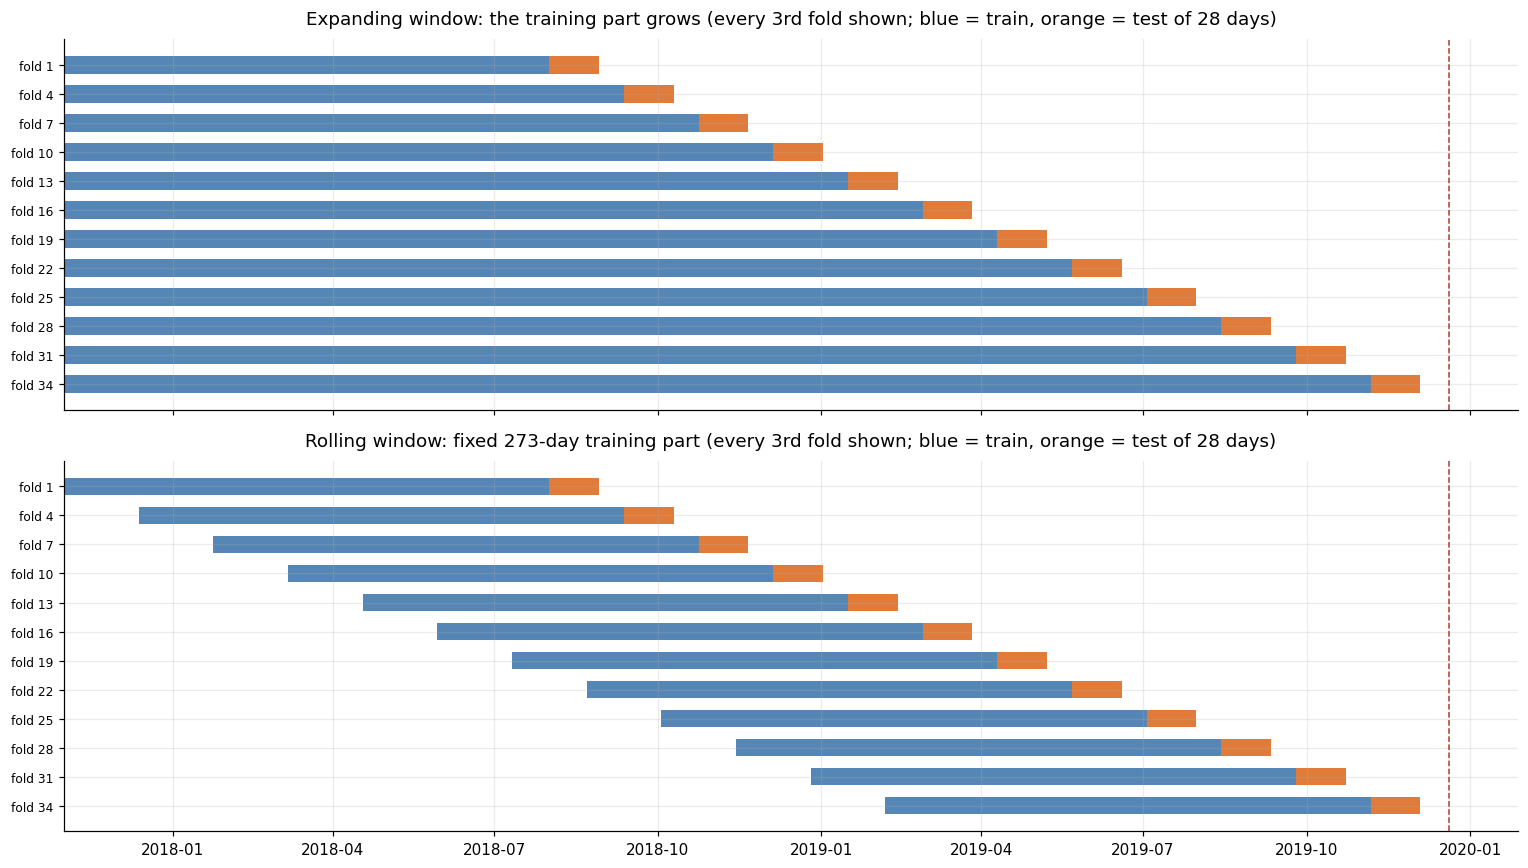

In [52]:
fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True)
shown = list(range(0, len(folds_exp), 3))
for ax, f, title in [(axes[0], folds_exp, "Expanding window: the training part grows"),
                     (axes[1], folds_roll, f"Rolling window: fixed {INITIAL_TRAIN_DAYS}-day training part")]:
    for k, i in enumerate(shown):
        r = f.iloc[i]
        ax.barh(k, (r["train_end"] - r["train_start"]) + pd.Timedelta(days=1), left=r["train_start"], height=0.6, color="#5686B5")
        ax.barh(k, pd.Timedelta(days=HORIZON), left=r["test_start"], height=0.6, color="#E07B39")
    ax.set_yticks(range(len(shown)))
    ax.set_yticklabels([f"fold {f.iloc[i]['fold']}" for i in shown], fontsize=8)
    ax.invert_yaxis()
    ax.set_title(title + " (every 3rd fold shown; blue = train, orange = test of 28 days)", pad=10)
    ax.axvline(MODEL_END, color="#B03A2E", linestyle="--", linewidth=1)
plt.tight_layout()
plt.show()

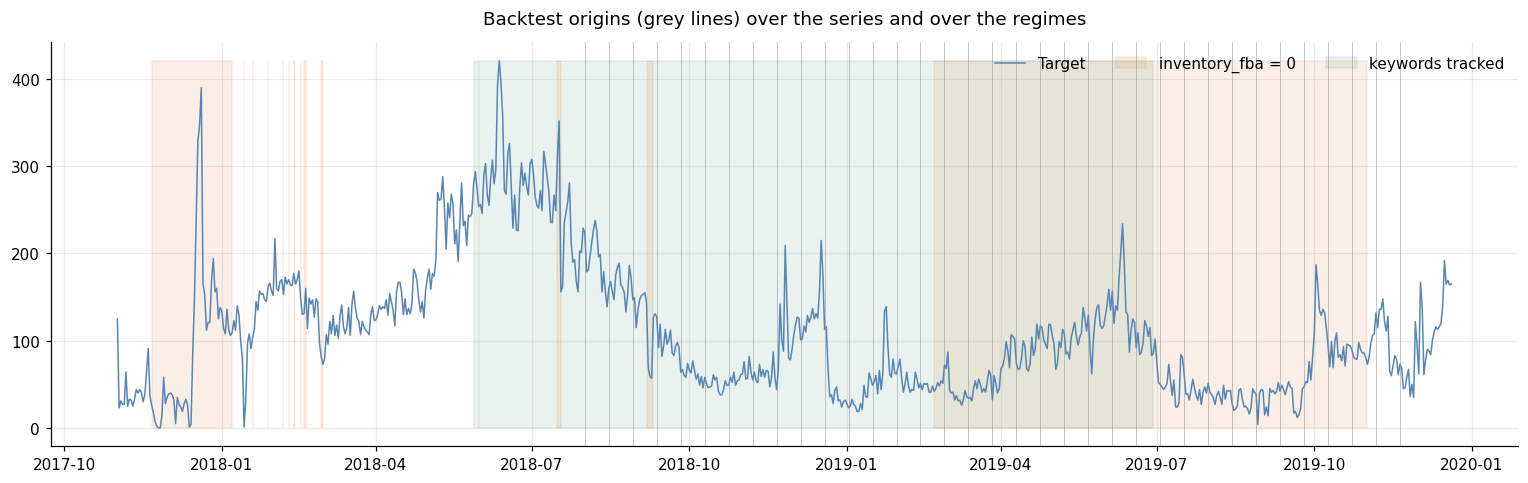

,number of folds
folds,35
FBA empty on >50% of test days,18
FBA never empty,13
keywords tracked in the whole window,22
contain a sales event,7
contain an anomaly day,20
"test level, min - max",32 - 179


In [53]:
fig, ax = plt.subplots(figsize=(14, 4.5))
ax.plot(ds.index, ds["target"], color="#5686B5", linewidth=1, label="Target")
ax.fill_between(ds.index, 0, ds["target"].max(), where=(ds["inventory_fba"] == 0), color="#E07B39", alpha=0.12, label="inventory_fba = 0")
ax.fill_between(ds.index, 0, ds["target"].max(), where=(ds["kw_tracked"] == 1), color="#2F855A", alpha=0.10, label="keywords tracked")
for d_ in folds_exp["test_start"]:
    ax.axvline(d_, color="#7A8A99", linewidth=0.5, alpha=0.6)
ax.set_title("Backtest origins (grey lines) over the series and over the regimes", pad=12)
ax.legend(frameon=False, ncol=3, loc="upper right")
plt.tight_layout()
plt.show()

reg = []
for _, r in folds_exp.iterrows():
    w = ds.loc[r["test_start"]:r["test_end"]]
    reg.append({
        "fold": r["fold"], "test_start": r["test_start"].date(),
        "mean target": w["target"].mean(),
        "fba empty share": (w["inventory_fba"] == 0).mean(),
        "keywords tracked": bool(w["kw_tracked"].all()),
        "has event": bool(w["near_event"].any()),
        "has anomaly": bool(w["is_anomaly"].any()),
    })
reg = pd.DataFrame(reg).set_index("fold")
display(pd.DataFrame({
    "folds": [len(reg)],
    "FBA empty on >50% of test days": [int((reg["fba empty share"] > 0.5).sum())],
    "FBA never empty": [int((reg["fba empty share"] == 0).sum())],
    "keywords tracked in the whole window": [int(reg["keywords tracked"].sum())],
    "contain a sales event": [int(reg["has event"].sum())],
    "contain an anomaly day": [int(reg["has anomaly"].sum())],
    "test level, min - max": [f"{reg['mean target'].min():.0f} - {reg['mean target'].max():.0f}"],
}).T.rename(columns={0: "number of folds"}))

Бектест робимо за схемою rolling-origin. Перший тест починається 01.08.2018 (до нього 273 дні навчання, що охоплюють запуск і перший літній пік), далі початок тесту зсувається на 14 днів, кожен тест триває 28 днів. Усього 35 фолдів, і жоден не виходить за кінець робочого вікна. Основний варіант — expanding window (навчання від 01.11.2017 до origin, 273–749 днів), для перевірки на дрейф є rolling window фіксованої довжини 273 дні з тими самими тестовими вікнами.

Тестується 504 з 780 днів. Оскільки крок 14 менший за горизонт 28, вікна перекриваються і кожен день потрапляє в тест 1–2 рази, тож фолди залежні й довірчі інтервали за ними слід читати обережно.

Режими в тестах різні: у 18 із 35 вікон inventory_fba порожній понад половину днів, у 13 ніколи не порожній, в 22 вікнах ключові слова відстежуються повністю, 7 вікон містять подію, 20 містять аномальний день, рівень target у тестах від 32 до 179.

Є й обмеження: літній пік 2018 (до 8,8 тис. на місяць) лежить лише в навчальній частині, усі тести припадають на спокійніший період після серпня 2018. Про поведінку моделі на піку такого масштабу ця оцінка нічого не каже.

## 2.3 Leakage audit of the columns

In [54]:
audit = pd.DataFrame([
    ["target (and log_target) up to the origin T", "yes", "lags and rolling statistics are taken with the window ending exactly at T"],
    ["target / log_target at the target date", "no", "this is the answer"],
    ["dow, month, near_event, days_since_launch", "yes", "calendar is known in advance (events: dates of Black Friday and Prime Day are published beforehand)"],
    ["own_price at T", "yes", "the price valid on the day of the forecast"],
    ["own_price after T", "only as a scenario", "a price in the future is a decision of the seller; it can be used only as a given plan"],
    ["comp_mean, comp_min, price_ratio at T", "yes", "competitors' prices at the origin; future prices are unknown"],
    ["inventory_fba, inventory_fbm at T", "yes", "stock level at the origin; future stock is unknown (scenario or lag only)"],
    ["kw_n_ranked, kw_best, kw_mean at T", "yes", "same-day positions are partly a consequence of today's sales; only for the 398 tracked days"],
    ["is_anomaly", "no", "computed from a CENTRED 29-day median, i.e. it uses 14 days of the future"],
    ["trend / seasonal / resid from seasonal_decompose", "no", "centred moving average, uses the future (use only for plots)"],
    ["leak_order_rows, leak_order_units", "no", "target itself (row count) or its multiple (units), measured on the same day"],
    ["scaling, imputation, log-shift constants", "fit on train only", "statistics computed on the whole series leak the level of the test period"],
], columns=["column", "known at the origin T?", "rule"])
display(audit.style.hide(axis="index").set_properties(**{"text-align": "left"}))

column,known at the origin T?,rule
target (and log_target) up to the origin T,yes,lags and rolling statistics are taken with the window ending exactly at T
target / log_target at the target date,no,this is the answer
"dow, month, near_event, days_since_launch",yes,calendar is known in advance (events: dates of Black Friday and Prime Day are published beforehand)
own_price at T,yes,the price valid on the day of the forecast
own_price after T,only as a scenario,a price in the future is a decision of the seller; it can be used only as a given plan
"comp_mean, comp_min, price_ratio at T",yes,competitors' prices at the origin; future prices are unknown
"inventory_fba, inventory_fbm at T",yes,stock level at the origin; future stock is unknown (scenario or lag only)
"kw_n_ranked, kw_best, kw_mean at T",yes,same-day positions are partly a consequence of today's sales; only for the 398 tracked days
is_anomaly,no,"computed from a CENTRED 29-day median, i.e. it uses 14 days of the future"
trend / seasonal / resid from seasonal_decompose,no,"centred moving average, uses the future (use only for plots)"


In [55]:
def origin_features(d):
    """Features of the origin: row t contains only information available at the end of day t."""
    f = pd.DataFrame(index=d.index)
    for k in (0, 1, 2, 3, 6, 7, 13, 14, 27, 28):
        f[f"y_lag{k}"] = d["target"].shift(k)
    f["roll7"] = d["target"].rolling(7).mean()
    f["roll28"] = d["target"].rolling(28).mean()
    f["std7"] = d["target"].rolling(7).std()
    f["ratio7_28"] = f["roll7"] / f["roll28"]
    for c in ["inventory_fba", "inventory_fbm", "own_price", "price_ratio"]:
        f[f"{c}_T"] = d[c]
    return f

def assert_causal(feature_fn, d, n_checks=40, seed=0):
    """Property test: the features of origin t must not change if all data after t are removed."""
    rng = np.random.default_rng(seed)
    full = feature_fn(d)
    for pos in rng.choice(np.arange(60, len(d)), size=n_checks, replace=False):
        t = d.index[pos]
        truncated = feature_fn(d.loc[:t]).iloc[-1]
        if not np.allclose(truncated.values.astype(float), full.loc[t].values.astype(float), equal_nan=True):
            bad = [c for c in full.columns if not np.isclose(truncated[c], full.loc[t, c], equal_nan=True)]
            return False, bad
    return True, []

ok, bad = assert_causal(origin_features, ds)
print("origin_features is causal:", ok)

def leaky_features(d):
    f = origin_features(d)
    f["centred_mean7"] = d["target"].rolling(7, center=True).mean()
    f["is_anomaly_flag"] = d["is_anomaly"]
    f["same_day_orders"] = d["leak_order_rows"]
    return f

ok_leaky, bad_leaky = assert_causal(leaky_features, ds)
print("leaky_features is causal:", ok_leaky, "| the test caught:", bad_leaky)

origin_features is causal: True
leaky_features is causal: False | the test caught: ['centred_mean7']


Тест причинності перевіряє, чи змінюються ознаки origin, якщо відрізати майбутнє. Він ловить ознаки, обчислені з майбутніх даних (наприклад, центроване ковзне середнє), але не ловить колонки, які просто лежать у таблиці й концептуально недоступні (is_anomaly, одноденні orders), бо їх неможливо перерахувати з обрізаних даних. Тому потрібна ще й таблиця аудиту вище.

In [56]:
FEATURES = list(origin_features(ds).columns)
EXTRA_TARGET_DATE = ["dow_target", "month_target", "event_target"]

def stack_horizons(d, H):
    """Rows (origin t, horizon h): features of the origin + calendar of the target date t+h + the answer y_{t+h}."""
    F = origin_features(d)
    parts = []
    for h in range(1, H + 1):
        p = F.copy()
        p["h"] = h
        p["origin"] = p.index
        p["target_date"] = p.index + pd.Timedelta(days=h)
        p["y"] = d["target"].reindex(p["target_date"]).values
        p["dow_target"] = p["target_date"].dt.dayofweek
        p["month_target"] = p["target_date"].dt.month
        p["event_target"] = d["near_event"].reindex(p["target_date"]).values
        p["orders_at_target_date"] = d["leak_order_rows"].reindex(p["target_date"]).values
        parts.append(p)
    out = pd.concat(parts, ignore_index=True)
    return out.dropna(subset=FEATURES + ["y", "event_target"]).reset_index(drop=True)

table = stack_horizons(ds, HORIZON)
print("Stacked table (origin, horizon):", table.shape, "| origins", table["origin"].min().date(), "-", table["origin"].max().date())

def train_rows(table, train_end):
    """Purging: a training row is allowed only if its ANSWER is dated not later than the end of the training part."""
    return table[table["target_date"] <= train_end]

def test_rows(table, train_end, test_start, test_end):
    return table[(table["origin"] == train_end) & (table["target_date"] >= test_start) & (table["target_date"] <= test_end)]

for _, r in folds_exp.iterrows():
    tr = train_rows(table, r["train_end"])
    te = test_rows(table, r["train_end"], r["test_start"], r["test_end"])
    assert tr["target_date"].max() <= r["train_end"] < te["target_date"].min()
    assert (te["origin"] == r["train_end"]).all()
    assert sorted(te["h"]) == list(range(1, HORIZON + 1))
print("All", len(folds_exp), "folds: no training answer is dated after the end of the training part; each test fold has horizons 1..28")

Stacked table (origin, horizon): (20650, 26) | origins 2017-11-29 - 2019-12-19
All 35 folds: no training answer is dated after the end of the training part; each test fold has horizons 1..28


Тут є ще тонкий момент, purging. У постановці «origin × горизонт» кожен навчальний рядок має відповідь y на дату T + h. Такий рядок дозволений, лише якщо ця дата не пізніша за кінець навчальної частини. Інакше відповіді навчальних рядків потрапляють у тестовий період, хоча ознаки origin виглядають цілком чесними.

## 2.4 What leakage does to the estimate: an experiment

In [57]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import KFold

BASE = FEATURES + ["h"] + EXTRA_TARGET_DATE

def fit_predict(train, test, cols):
    model = RandomForestRegressor(n_estimators=60, min_samples_leaf=5, max_features=0.5, n_jobs=-1, random_state=0)
    model.fit(train[cols], train["y"])
    return model.predict(test[cols])

demo_folds = folds_exp.iloc[::2]
records = []
for _, r in demo_folds.iterrows():
    te = test_rows(table, r["train_end"], r["test_start"], r["test_end"])
    tr_ok = train_rows(table, r["train_end"])
    tr_unpurged = table[table["origin"] <= r["train_end"]]

    for scenario, tr, cols in [
        ("honest (purged training rows)", tr_ok, BASE),
        ("unpurged: training answers overlap the test period", tr_unpurged, BASE),
        ("honest + same-day orders as a feature", tr_ok, BASE + ["orders_at_target_date"]),
    ]:
        pred = fit_predict(tr, te, cols)
        records.append(pd.DataFrame({"scenario": scenario, "fold": r["fold"], "h": te["h"].values, "y": te["y"].values, "pred": pred}))
    records.append(pd.DataFrame({"scenario": "baseline: last value", "fold": r["fold"], "h": te["h"].values, "y": te["y"].values, "pred": te["y_lag0"].values}))

# shuffled K-fold on the same stacked table (what is typically done by mistake)
cmp_mask = (table["target_date"] >= FIRST_TEST_START)
shuffled = np.zeros(len(table))
for tr_idx, te_idx in KFold(5, shuffle=True, random_state=0).split(table):
    shuffled[te_idx] = fit_predict(table.iloc[tr_idx], table.iloc[te_idx], BASE)
records.append(pd.DataFrame({"scenario": "shuffled 5-fold (random rows)", "fold": 0, "h": table.loc[cmp_mask, "h"].values,
                             "y": table.loc[cmp_mask, "y"].values, "pred": shuffled[cmp_mask.values]}))

res = pd.concat(records, ignore_index=True)
res["abs_err"] = (res["y"] - res["pred"]).abs()
res["bucket"] = pd.cut(res["h"], [0, 7, 14, 28], labels=["h 1-7", "h 8-14", "h 15-28"])

summary = res.groupby("scenario").agg(MAE=("abs_err", "mean"), rows=("y", "size"))
summary["MAE / mean level"] = summary["MAE"] / level
order = ["baseline: last value", "honest (purged training rows)", "unpurged: training answers overlap the test period",
         "shuffled 5-fold (random rows)", "honest + same-day orders as a feature"]
display(summary.loc[order].round(3))
by_bucket = res.pivot_table(index="scenario", columns="bucket", values="abs_err", aggfunc="mean", observed=True).loc[order]
display(by_bucket.round(1))

,MAE,rows,MAE / mean level
scenario,,,
baseline: last value,34.571,504,0.422
honest (purged training rows),35.478,504,0.433
unpurged: training answers overlap the test period,9.387,504,0.115
shuffled 5-fold (random rows),11.184,14196,0.136
honest + same-day orders as a feature,5.645,504,0.069


bucket,h 1-7,h 8-14,h 15-28
scenario,,,
baseline: last value,23.5,36.0,39.4
honest (purged training rows),24.4,36.6,40.5
unpurged: training answers overlap the test period,9.5,10.2,8.9
shuffled 5-fold (random rows),11.0,11.0,11.4
honest + same-day orders as a feature,4.6,6.2,5.9


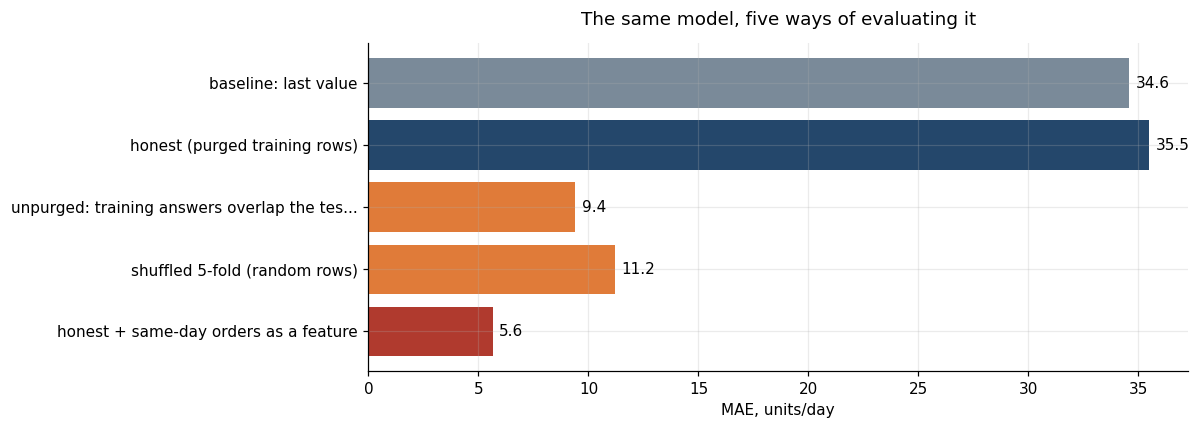

In [58]:
fig, ax = plt.subplots(figsize=(11, 4))
vals = summary.loc[order, "MAE"]
colors = ["#7A8A99", "#24476B", "#E07B39", "#E07B39", "#B03A2E"]
ax.barh(range(len(vals)), vals.values, color=colors)
ax.set_yticks(range(len(vals)))
ax.set_yticklabels([o if len(o) < 45 else o[:42] + "..." for o in order])
ax.invert_yaxis()
for i, v in enumerate(vals.values):
    ax.text(v + 0.3, i, f"{v:.1f}", va="center")
ax.set_xlabel("MAE, units/day")
ax.set_title("The same model, five ways of evaluating it", pad=12)
plt.tight_layout()
plt.show()

Одна й та сама модель (Random Forest на чесних ознаках origin) оцінена п'ятьма способами, 18 фолдів × 28 горизонтів = 504 прогнози.

| Спосіб оцінки | MAE, шт./день | MAE / середній рівень |
|---|---|---|
| бейзлайн «як учора» | 34,6 | 0,42 |
| чесний бектест (purged) | 35,5 | 0,43 |
| без purging (відповіді навчання перекривають тест) | 9,4 | 0,11 |
| випадковий 5-fold з перемішуванням | 11,2 | 0,14 |
| чесний + одноденні orders як ознака | 5,6 | 0,07 |

Витоки роблять модель у 3–6 разів точнішою, ніж вона є: помилка 5,6–11 виглядає майже ідеально, а реальна 35,5. Чесний результат при цьому неприємний: Random Forest з такими ознаками не б'є наївний бейзлайн (35,5 проти 34,6). Це не помилка схеми, а точка відліку для наступного розділу, де моделі мають перевершити помилку 43% рівня на горизонті до 28 днів. За відстанню до цілі чесна помилка така: 24,4 для 1–7 днів, 36,6 для 8–14 і 40,5 для 15–28.

Підсумок розділу 2.

| Питання | Рішення |
|---|---|
| Origin | кінець дня T, усі ознаки датовані не пізніше T |
| Горизонт | H = 28, звіт за відстанню 1–7 / 8–14 / 15–28 |
| Схема | rolling-origin, 35 фолдів, крок 14, тест 28 днів, перший тест 01.08.2018 |
| Навчання | expanding (основне) і rolling 273 дні (перевірка) |
| Purging | рядок навчання дозволений, якщо дата його відповіді не пізніша за кінець навчання |
| Не можна як ознаки | is_anomaly, seasonal_decompose, leak_*, будь-що з майбутнього |
| Ключові слова | лише 28.05.2018 – 29.06.2019 і з лагом |
| Ціна й inventory | значення на момент origin або явний сценарій |
| Файли | folds_expanding.csv, folds_rolling.csv |

In [59]:
folds_exp.to_csv("folds_expanding.csv", index=False)
folds_roll.to_csv("folds_rolling.csv", index=False)
print("Saved: folds_expanding.csv, folds_rolling.csv")

Saved: folds_expanding.csv, folds_rolling.csv


# 3. Baselines

## 3.1 Metrics and the evaluation harness

Усі моделі оцінюємо на тих самих 35 фолдах з розділу 2: на кожному фолді модель бачить дані до origin і прогнозує наступні 28 днів. Метрики такі.

MAE, середня абсолютна помилка в штуках на день. RMSE, який сильніше карає великі промахи (це та сама MSE з лекції про згладжування, тільки під коренем). WAPE, сума абсолютних помилок, поділена на суму продажів: це помилка у відсотках від рівня, з нею зручно порівнювати фолди з різним рівнем. Bias, сума помилок, поділена на суму продажів (помилка = факт мінус прогноз, тому знак мінус означає, що прогноз у середньому завищений). Окремо рахуємо помилку 28-денної суми, бо для планування запасів потрібен обсяг за місяць, а не окремий день.

MAPE не використовуємо: у ряді є нулі й дуже малі значення, і відсоток на них стає нестабільним.

In [60]:
from statsmodels.tsa.holtwinters import SimpleExpSmoothing, Holt, ExponentialSmoothing
from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import Ridge
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
import lightgbm as lgb

series = ds["target"]
log_series = np.log1p(series)
results = {}

def evaluate(name, forecast_fn, folds=folds_exp):
    """forecast_fn(train_end, test_dates) -> array of predictions for the test dates; only data up to train_end may be used."""
    parts = []
    for _, r in folds.iterrows():
        dates = pd.date_range(r["test_start"], r["test_end"])
        pred = np.asarray(forecast_fn(r["train_end"], dates), dtype=float)
        assert len(pred) == len(dates) and np.isfinite(pred).all()
        parts.append(pd.DataFrame({"fold": r["fold"], "date": dates, "h": np.arange(1, len(dates) + 1),
                                   "y": series.reindex(dates).values, "pred": pred}))
    results[name] = pd.concat(parts, ignore_index=True)
    return results[name]

def metric_row(df):
    e = df["y"] - df["pred"]
    totals = df.groupby("fold")[["y", "pred"]].sum()
    return pd.Series({
        "MAE": e.abs().mean(),
        "RMSE": np.sqrt((e ** 2).mean()),
        "WAPE": e.abs().sum() / df["y"].sum(),
        "bias": e.sum() / df["y"].sum(),
        "28-day total error": ((totals["y"] - totals["pred"]).abs() / totals["y"]).mean(),
    })

def score_table(names):
    return pd.DataFrame({n: metric_row(results[n]) for n in names}).T

## 3.2 Naive benchmarks

In [61]:
def naive_last(te, dates):
    return np.repeat(series.loc[te], len(dates))

def mean_all(te, dates):
    return np.repeat(series.loc[:te].mean(), len(dates))

def moving_average(k):
    return lambda te, dates: np.repeat(series.loc[:te].iloc[-k:].mean(), len(dates))

def seasonal_naive(te, dates):
    last = series.loc[:te]
    return np.array([last.loc[d - pd.Timedelta(days=7 * int(np.ceil(h / 7)))] for h, d in enumerate(dates, 1)])

def seasonal_mean4(te, dates):
    last = series.loc[:te]
    return np.array([np.mean([last.loc[d - pd.Timedelta(days=7 * (int(np.ceil(h / 7)) + j))] for j in range(4)]) for h, d in enumerate(dates, 1)])

naive_models = {
    "naive (last value)": naive_last,
    "mean of all history": mean_all,
    "moving average 7": moving_average(7),
    "moving average 28": moving_average(28),
    "seasonal naive (same weekday)": seasonal_naive,
    "mean of last 4 same weekdays": seasonal_mean4,
}
for name, fn in naive_models.items():
    evaluate(name, fn)
display(score_table(list(naive_models)).round(3))

,MAE,RMSE,WAPE,bias,28-day total error
naive (last value),31.615,45.170,0.398,-0.094,0.377
mean of all history,58.852,68.164,0.741,-0.658,0.994
moving average 7,32.157,43.785,0.405,-0.050,0.377
moving average 28,36.815,47.364,0.464,-0.093,0.438
seasonal naive (same weekday),33.985,46.459,0.428,-0.050,0.377
mean of last 4 same weekdays,37.138,47.784,0.468,-0.093,0.438


Найкращий з наївних за MAE прогноз «як учора» (31,6, WAPE 0,40), а за RMSE ковзне середнє за 7 днів (43,8 проти 45,2): воно менше схильне до великих промахів, коли останній день був випадковим піком. Прогноз «той самий день минулого тижня» гірший (34,0), хоча в 1.5 ми бачили значущу тижневу сезонність: на горизонті до 28 днів рівень рухається більше, ніж день тижня. Середнє за всю історію (58,9) програє вдвічі й має зміщення −66%, бо рівень ряду дуже змінюється, і стара історія вводить в оману.

Крім середнього за всю історію, наївні моделі близькі між собою, а помилка висока: у середньому 40% від рівня. Усі наступні моделі треба порівнювати з 31,6 (MAE) і 45,2 (RMSE).

## 3.3 Exponential smoothing

In [62]:
def ets_forecast(kind, log=True, damped=True):
    def fn(te, dates):
        s = (log_series if log else series).loc[:te].copy()
        s.index.freq = "D"
        if kind == "ses":
            fit = SimpleExpSmoothing(s, initialization_method="estimated").fit()
        elif kind == "holt":
            fit = Holt(s, damped_trend=damped, initialization_method="estimated").fit()
        else:
            fit = ExponentialSmoothing(s, trend="add", damped_trend=damped, seasonal="add", seasonal_periods=7,
                                       initialization_method="estimated").fit()
        p = fit.forecast(len(dates)).values
        return np.clip(np.expm1(p) if log else p, 0, None)
    return fn

ets_models = {
    "SES (log)": ets_forecast("ses"),
    "Holt damped (log)": ets_forecast("holt"),
    "Holt-Winters weekly (log)": ets_forecast("hw"),
    "Holt-Winters weekly (raw)": ets_forecast("hw", log=False),
}
for name, fn in ets_models.items():
    evaluate(name, fn)
display(score_table(list(ets_models)).round(3))

,MAE,RMSE,WAPE,bias,28-day total error
SES (log),31.788,45.481,0.400,-0.099,0.383
Holt damped (log),31.791,45.481,0.400,-0.099,0.383
Holt-Winters weekly (log),29.838,42.721,0.376,-0.021,0.351
Holt-Winters weekly (raw),31.315,44.165,0.394,0.013,0.367


Просте експоненціальне згладжування (SES) і Holt з демпфованим трендом дають майже однакову помилку (31,8): схоже, демпфований тренд на цьому горизонті практично нічого не змінює. Різниця з'являється лише з тижневою сезонністю. Holt–Winters на log(1+y) з періодом 7 дає MAE 29,8, на 5,6% краще за наївний, і майже нульове зміщення (−0,02). Той самий Holt–Winters на сирому target слабший (31,3), тож логарифм допомагає, як ми й очікували з 1.5.

## 3.4 SARIMA and SARIMAX

In [63]:
screen_series = log_series.loc[:FIRST_TEST_START - pd.Timedelta(days=1)].copy()
screen_series.index.freq = "D"
screen_rows = []
for order in [(0, 1, 1), (1, 1, 0), (1, 1, 1), (2, 1, 1), (2, 1, 2), (3, 1, 2)]:
    for seasonal in [(0, 0, 0, 0), (0, 0, 1, 7), (1, 0, 1, 7), (0, 1, 1, 7)]:
        try:
            fit = SARIMAX(screen_series, order=order, seasonal_order=seasonal).fit(disp=False, maxiter=60)
            screen_rows.append({"order": order, "seasonal": seasonal, "AIC": fit.aic})
        except Exception:
            pass
screening = pd.DataFrame(screen_rows).sort_values("AIC").reset_index(drop=True)
print(f"Screening by AIC on the data before the first fold ({len(screen_series)} days), 8 best of {len(screening)}:")
display(screening.head(8).round(1))

Screening by AIC on the data before the first fold (273 days), 8 best of 24:


,order,seasonal,AIC
0,"(2, 1, 1)","(0, 0, 1, 7)",371.4
1,"(2, 1, 2)","(0, 0, 1, 7)",372.9
2,"(2, 1, 1)","(1, 0, 1, 7)",373.2
3,"(1, 1, 1)","(0, 0, 1, 7)",374.2
4,"(2, 1, 2)","(1, 0, 1, 7)",374.3
5,"(3, 1, 2)","(0, 0, 1, 7)",375.0
6,"(1, 1, 1)","(1, 0, 1, 7)",376.0
7,"(3, 1, 2)","(1, 0, 1, 7)",376.7


Порядки SARIMA підбираємо за AIC на даних до першого фолда (273 дні), як у домашній роботі. Сезонний період 7, а сезонне диференціювання не потрібне (див. 1.6), тому найкращі моделі мають D = 0 і сезонний MA(1).

In [64]:
event_flag = ds["near_event"].astype(float)

def sarimax_forecast(order, seasonal, use_events=False):
    def fn(te, dates):
        s = log_series.loc[:te].copy()
        s.index.freq = "D"
        exog = event_flag.loc[:te].to_frame() if use_events else None
        exog_future = event_flag.reindex(dates).fillna(0).to_frame() if use_events else None
        fit = SARIMAX(s, exog=exog, order=order, seasonal_order=seasonal).fit(disp=False, maxiter=100)
        return np.clip(np.expm1(fit.forecast(len(dates), exog=exog_future).values), 0, None)
    return fn

sarima_models = {
    "SARIMA (2,1,1)(0,0,1)7": sarimax_forecast((2, 1, 1), (0, 0, 1, 7)),
    "SARIMA (1,1,1)(0,0,1)7": sarimax_forecast((1, 1, 1), (0, 0, 1, 7)),
    "SARIMA (2,1,2)(1,0,1)7": sarimax_forecast((2, 1, 2), (1, 0, 1, 7)),
    "SARIMAX (1,1,1)(0,0,1)7 + events": sarimax_forecast((1, 1, 1), (0, 0, 1, 7), use_events=True),
}
for name, fn in sarima_models.items():
    evaluate(name, fn)
display(score_table(list(sarima_models)).round(3))

,MAE,RMSE,WAPE,bias,28-day total error
"SARIMA (2,1,1)(0,0,1)7",31.247,42.722,0.394,-0.049,0.356
"SARIMA (1,1,1)(0,0,1)7",32.100,43.543,0.404,-0.060,0.363
"SARIMA (2,1,2)(1,0,1)7",31.210,42.796,0.393,-0.046,0.361
"SARIMAX (1,1,1)(0,0,1)7 + events",31.420,42.940,0.396,-0.074,0.354


На крос-валідації SARIMA дають 31,2–32,1 MAE, тобто майже стільки, скільки наївний прогноз. Модель з найменшим AIC (2,1,1)(0,0,1)7 має 31,2, так само як і складніша (2,1,2)(1,0,1)7; (1,1,1)(0,0,1)7 трохи гірша (32,1). Дамі-змінна подій (Black Friday, Cyber Monday, Prime Day) для цієї ж моделі знижує помилку з 32,1 до 31,4, але така різниця менша за розкид між фолдами. Ціну й inventory в SARIMAX не додаємо: їхні майбутні значення невідомі, а підставляти останнє значення на 28 днів не має сенсу.

## 3.5 Machine learning models

In [65]:
OWN_FEATURES = [c for c in FEATURES if c.startswith(("y_lag", "roll", "std7", "ratio"))]
EXO_FEATURES = [c for c in FEATURES if c.endswith("_T")]
CALENDAR = ["h", "dow_target", "month_target", "event_target"]
feature_sets = {"own + calendar": OWN_FEATURES + CALENDAR, "own + calendar + price/inventory": OWN_FEATURES + EXO_FEATURES + CALENDAR}

ml_factories = {
    "Ridge": (lambda: make_pipeline(StandardScaler(), Ridge(alpha=10)), True),
    "Random Forest": (lambda: RandomForestRegressor(n_estimators=100, min_samples_leaf=5, max_features=0.5, n_jobs=-1, random_state=0), False),
    "LightGBM": (lambda: lgb.LGBMRegressor(n_estimators=200, learning_rate=0.03, num_leaves=8, min_child_samples=40,
                                           subsample=0.8, subsample_freq=1, colsample_bytree=0.8, random_state=0, verbose=-1), False),
}
ROLLING_DAYS = INITIAL_TRAIN_DAYS

def ml_forecast(factory, cols, use_log, rolling):
    def fn(te, dates):
        tr = train_rows(table, te)
        if rolling:
            tr = tr[tr["origin"] > te - pd.Timedelta(days=ROLLING_DAYS)]
        ts_ = test_rows(table, te, dates[0], dates[-1]).sort_values("h")
        model = factory()
        model.fit(tr[cols], np.log1p(tr["y"]) if use_log else tr["y"])
        p = model.predict(ts_[cols])
        return np.clip(np.expm1(p) if use_log else p, 0, None)
    return fn

ml_names = []
for model_name, (factory, use_log) in ml_factories.items():
    for fs_name, cols in feature_sets.items():
        for rolling in (False, True):
            name = f"{model_name} | {fs_name} | {'rolling 273' if rolling else 'expanding'}"
            evaluate(name, ml_forecast(factory, cols, use_log, rolling))
            ml_names.append(name)
ml_table = score_table(ml_names)
ml_table.index = pd.MultiIndex.from_tuples([tuple(n.split(" | ")) for n in ml_table.index], names=["model", "features", "training"])
display(ml_table.round(3))

MAE    RMSE  \
model         features                         training                      
Ridge         own + calendar                   expanding    34.805  44.250   
                                               rolling 273  39.817  56.039   
              own + calendar + price/inventory expanding    36.152  47.454   
                                               rolling 273  40.061  57.197   
Random Forest own + calendar                   expanding    32.737  42.690   
                                               rolling 273  32.522  43.745   
              own + calendar + price/inventory expanding    34.250  44.880   
                                               rolling 273  31.283  42.401   
LightGBM      own + calendar                   expanding    37.078  47.172   
                                               rolling 273  34.378  46.153   
              own + calendar + price/inventory expanding    35.703  44.826   
                                               rolling 273  33.856  44.764   

                                                             WAPE   bias  \
model         features                         training                    
Ridge         own + calendar                   expanding    0.438 -0.132   
                                               rolling 273  0.501 -0.042   
              own + calendar + price/inventory expanding    0.455 -0.003   
                                               rolling 273  0.505 -0.025   
Random Forest own + calendar                   expanding    0.412 -0.171   
                                               rolling 273  0.410 -0.050   
              own + calendar + price/inventory expanding    0.431 -0.117   
                                               rolling 273  0.394 -0.054   
LightGBM      own + calendar                   expanding    0.467 -0.272   
                                               rolling 273  0.433 -0.103   
              own + calendar + price/inventory expanding    0.450 -0.167   
                                               rolling 273  0.426 -0.103   

                                                            28-day total error  
model         features                         training                         
Ridge         own + calendar                   expanding                 0.449  
                                               rolling 273               0.512  
              own + calendar + price/inventory expanding                 0.466  
                                               rolling 273               0.538  
Random Forest own + calendar                   expanding                 0.416  
                                               rolling 273               0.403  
              own + calendar + price/inventory expanding                 0.457  
                                               rolling 273               0.386  
LightGBM      own + calendar                   expanding                 0.490  
                                               rolling 273               0.424  
              own + calendar + price/inventory expanding                 0.480  
                                               rolling 273               0.418

ML-моделі працюють у схемі direct multi-horizon з розділу 2: один рядок на пару (origin, горизонт), тренувальні рядки очищені (purging). Для Ridge цільова змінна логарифмується й ознаки стандартизуються за train. Порівнюємо три моделі, дві групи ознак (власні лаги й календар, або ще ціна та inventory на момент origin) і два режими навчання (expanding і вікно 273 дні).

Найкраща за MAE модель Random Forest з ціною та inventory у режимі rolling 273 (31,3) і вона ж має найменший RMSE серед усіх (42,4). LightGBM слабший (33,9–37,1), Ridge слабший ще (34,8–40,1). Три спостереження. Перше, навчання на вікні 273 дні сильно зменшує зміщення (Random Forest з −0,17 до −0,05, LightGBM з −0,27 до −0,10): рівень продажів дрейфує, і стара історія тягне прогноз вгору. Друге, для Ridge вікно навпаки погіршує результат (34,8 → 39,8), бо лінійній моделі замало даних. Третє, ціна й inventory допомагають не всім: Random Forest у rolling-режимі покращується з 32,5 до 31,3, а в expanding-режимі погіршується з 32,7 до 34,3. Стійкого виграшу від цих ознак немає.

## 3.6 Comparison of all models

In [66]:
anomaly_days = set(ds.index[ds["is_anomaly"] == 1])

def full_row(name):
    df = results[name]
    row = metric_row(df)
    base = results["naive (last value)"]
    row["MAE vs naive, %"] = (row["MAE"] / (base["y"] - base["pred"]).abs().mean() - 1) * 100
    buckets = pd.cut(df["h"], [0, 7, 14, 28], labels=["MAE h 1-7", "MAE h 8-14", "MAE h 15-28"])
    for b, v in (df["y"] - df["pred"]).abs().groupby(buckets, observed=True).mean().items():
        row[b] = v
    clean = df[~df["date"].isin(anomaly_days)]
    row["MAE without anomaly days"] = (clean["y"] - clean["pred"]).abs().mean()
    fold_mae = (df["y"] - df["pred"]).abs().groupby(df["fold"]).mean()
    base_fold = (base["y"] - base["pred"]).abs().groupby(base["fold"]).mean()
    row["folds better than naive"] = int((fold_mae < base_fold).sum())
    return row

leaderboard = pd.DataFrame({n: full_row(n) for n in results}).T.sort_values("MAE")
display(leaderboard.round(3))

,MAE,RMSE,WAPE,bias,28-day total error,"MAE vs naive, %",MAE h 1-7,MAE h 8-14,MAE h 15-28,MAE without anomaly days,folds better than naive
Holt-Winters weekly (log),29.838,42.721,0.376,-0.021,0.351,-5.621,18.694,27.936,36.362,28.206,19.0
"SARIMA (2,1,2)(1,0,1)7",31.210,42.796,0.393,-0.046,0.361,-1.281,20.161,28.817,37.931,29.497,17.0
"SARIMA (2,1,1)(0,0,1)7",31.247,42.722,0.394,-0.049,0.356,-1.166,20.307,29.063,37.808,29.526,18.0
Random Forest | own + calendar + price/inventory | rolling 273,31.283,42.401,0.394,-0.054,0.386,-1.050,20.867,29.421,37.423,29.605,18.0
Holt-Winters weekly (raw),31.315,44.165,0.394,0.013,0.367,-0.950,20.348,29.130,37.891,29.791,20.0
"SARIMAX (1,1,1)(0,0,1)7 + events",31.420,42.940,0.396,-0.074,0.354,-0.617,21.371,29.125,37.593,29.683,16.0
naive (last value),31.615,45.170,0.398,-0.094,0.377,0.000,20.233,29.792,38.218,29.920,0.0
SES (log),31.788,45.481,0.400,-0.099,0.383,0.547,20.393,29.829,38.465,30.091,18.0
Holt damped (log),31.791,45.481,0.400,-0.099,0.383,0.555,20.396,29.833,38.467,30.094,18.0
"SARIMA (1,1,1)(0,0,1)7",32.100,43.543,0.404,-0.060,0.363,1.532,21.350,30.147,38.451,30.403,15.0


На першому місці Holt–Winters на логарифмі (MAE 29,8, на 5,6% краще за наївний). Далі п'ять моделей у межах 31,2–31,4, а наївний прогноз має 31,6. Різниці між першою сімкою набагато менші за розкид між фолдами, тому поза Holt–Winters відрізнити їх одну від одної не можна. Навіть Holt–Winters кращий за наївний лише на 19 з 35 фолдів, тобто не набагато частіше за монетку.

За RMSE вигляд інший: Random Forest у rolling-режимі з ціною та inventory (42,4), Holt–Winters і обидві SARIMA (42,7–42,8) майже не відрізняються, а наївний має 45,2. Тобто моделі помітніше зменшують великі промахи, ніж середню помилку.

Без днів-аномалій усі помилки на 1,5–2 менші (наївний 29,9, Holt–Winters 28,2), порядок моделей той самий. Помилка 28-денної суми у кращих моделей 35–39%, тобто місячний обсяг у середньому відомий із точністю лише приблизно в третину.

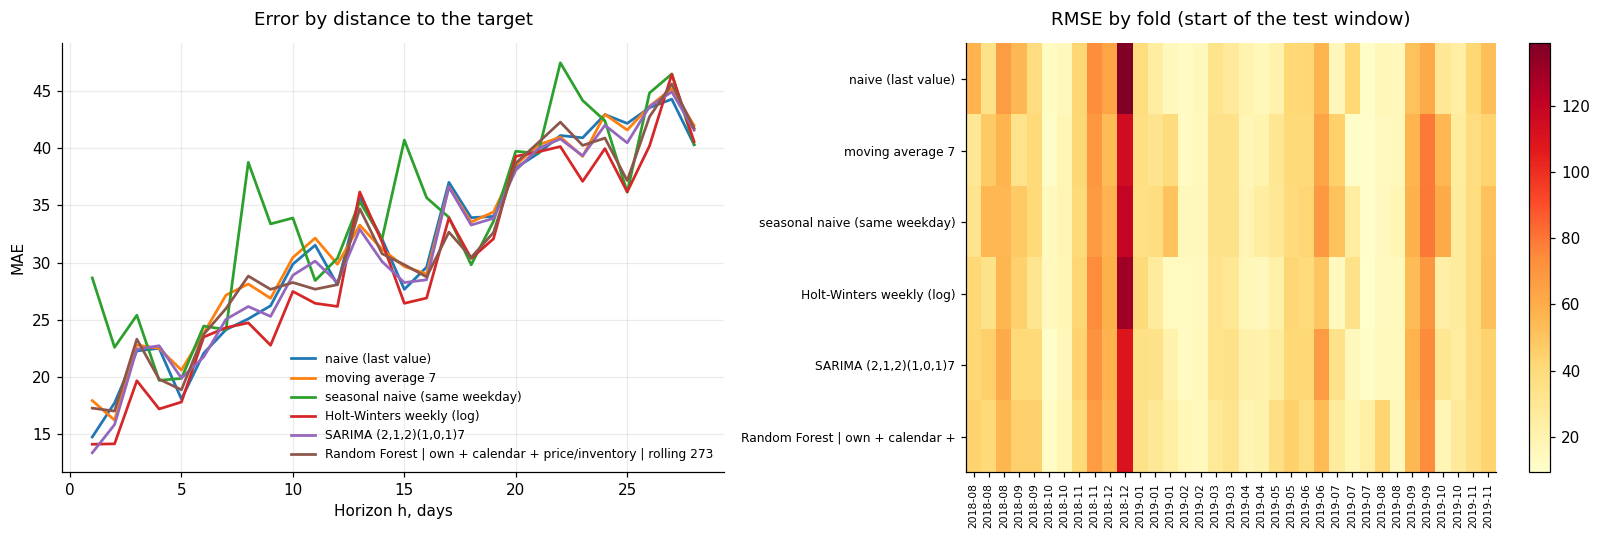

In [67]:
shortlist = ["naive (last value)", "moving average 7", "seasonal naive (same weekday)", "Holt-Winters weekly (log)",
             "SARIMA (2,1,2)(1,0,1)7", "Random Forest | own + calendar + price/inventory | rolling 273"]
fold_rmse = pd.DataFrame({n: results[n].groupby("fold").apply(lambda d: np.sqrt(((d["y"] - d["pred"]) ** 2).mean())) for n in shortlist})
fold_rmse.index = folds_exp.set_index("fold").loc[fold_rmse.index, "test_start"].dt.strftime("%Y-%m")

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for n in shortlist:
    d = results[n]
    (d["y"] - d["pred"]).abs().groupby(d["h"]).mean().plot(ax=axes[0], label=n, linewidth=1.8)
axes[0].set_xlabel("Horizon h, days")
axes[0].set_ylabel("MAE")
axes[0].set_title("Error by distance to the target", pad=12)
axes[0].legend(frameon=False, fontsize=8)

im = axes[1].imshow(fold_rmse.T.values, aspect="auto", cmap="YlOrRd")
axes[1].set_xticks(range(len(fold_rmse)))
axes[1].set_xticklabels(fold_rmse.index, rotation=90, fontsize=7)
axes[1].set_yticks(range(len(shortlist)))
axes[1].set_yticklabels([n[:32] for n in shortlist], fontsize=8)
axes[1].set_title("RMSE by fold (start of the test window)", pad=12)
axes[1].grid(False)
plt.colorbar(im, ax=axes[1])
plt.tight_layout()
plt.show()

Помилка зростає з горизонтом майже втричі: від ≈ 15–18 на першому дні до ≈ 40–46 на двадцять восьмому. Моделі майже збігаються між собою, а Holt–Winters виграє переважно на горизонтах 1–14 днів (18,7 і 27,9 проти 20,2 і 29,8 у наївного).

На карті помилок по фолдах найтемніший стовпчик один: тестове вікно, що починається в грудні 2018. Це не помилка однієї моделі, а подія, яку не вгадала жодна.

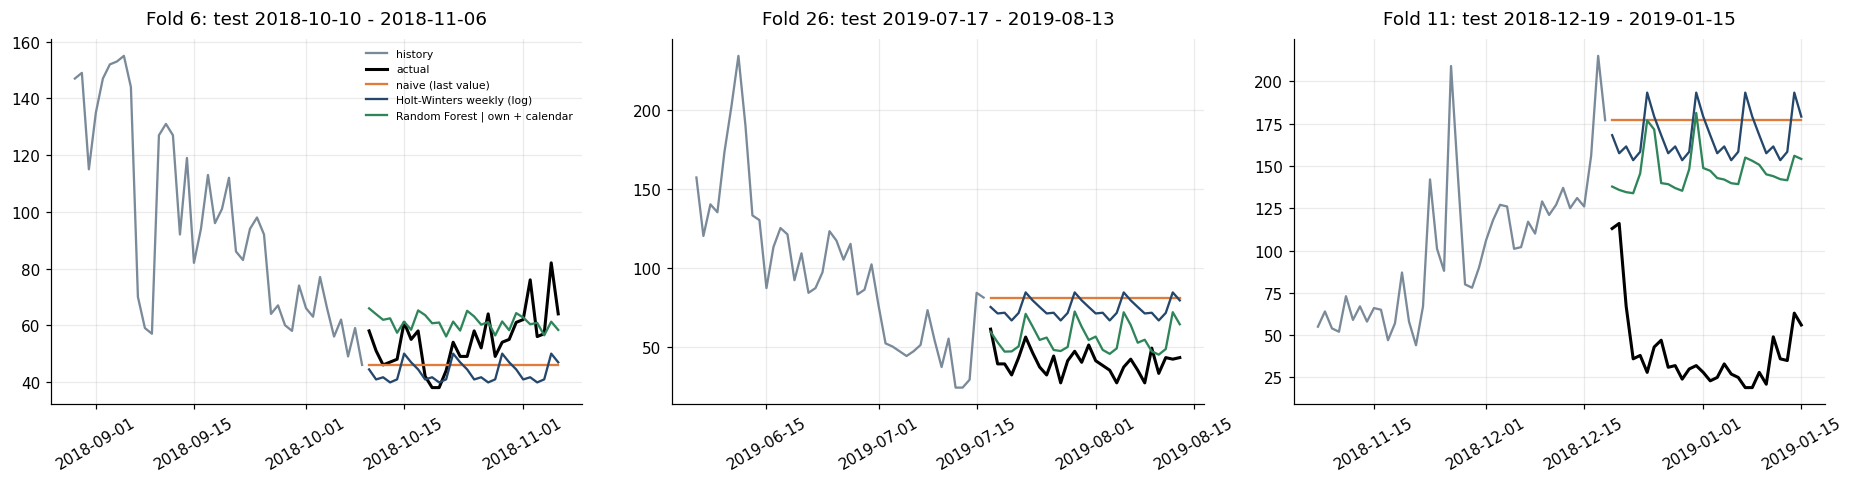

fold with the largest naive RMSE: 11


In [68]:
def show_fold(ax, fold, models):
    r = folds_exp.set_index("fold").loc[fold]
    hist = series.loc[r["test_start"] - pd.Timedelta(days=42):r["test_start"] - pd.Timedelta(days=1)]
    ax.plot(hist.index, hist.values, color="#7A8A99", label="history")
    d0 = results[models[0]]
    d0 = d0[d0["fold"] == fold]
    ax.plot(d0["date"], d0["y"], color="black", linewidth=2, label="actual")
    for n, c in zip(models, ["#E07B39", "#24476B", "#2F855A"]):
        d = results[n]
        d = d[d["fold"] == fold]
        ax.plot(d["date"], d["pred"], color=c, label=n[:30])
    ax.set_title(f"Fold {fold}: test {r['test_start'].date()} - {r['test_end'].date()}", pad=10)
    ax.tick_params(axis="x", rotation=30)

show_models = ["naive (last value)", "Holt-Winters weekly (log)", "Random Forest | own + calendar + price/inventory | rolling 273"]
worst_fold = int(fold_rmse.T.loc["naive (last value)"].values.argmax()) + 1
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5), sharey=False)
for ax, f_ in zip(axes, [6, 26, worst_fold]):
    show_fold(ax, f_, show_models)
axes[0].legend(frameon=False, fontsize=7)
plt.tight_layout()
plt.show()
print("fold with the largest naive RMSE:", worst_fold)

На фолдах 6 і 26 рівень стабільний, і прогнози Holt–Winters і Random Forest гарно повторюють добову форму. Фолд 11 (19.12.2018 – 15.01.2019) показує, що ламає всі моделі: продажі за кілька днів падають зі ~175 до ~35 на день, а прогноз по інерції лишається на рівні 150–175. Ознак цього падіння на момент origin немає (їх не видно ні в лагах, ні в ціні чи inventory), а в 1.7 такі провали здебільшого збігалися з порожнім FBA. Тому, імовірно, головна причина великих помилок у недоступній наперед інформації про наявність товару, а не в слабкості моделей.

In [69]:
seg = reg.copy()
seg["regime"] = np.where(seg["fba empty share"] > 0.5, "FBA empty (>50% of days)", np.where(seg["fba empty share"] == 0, "FBA never empty", "mixed"))
rows = []
for n in ["naive (last value)", "Holt-Winters weekly (log)", "SARIMA (2,1,2)(1,0,1)7", "Random Forest | own + calendar + price/inventory | rolling 273"]:
    fm = (results[n]["y"] - results[n]["pred"]).abs().groupby(results[n]["fold"]).mean()
    rows.append(fm.groupby(seg["regime"]).mean().rename(n))
regime_table = pd.DataFrame(rows)
regime_table["folds"] = np.nan
display(regime_table.drop(columns="folds").round(1))
print(seg["regime"].value_counts().to_dict())

regime,FBA empty (>50% of days),FBA never empty,mixed
naive (last value),23.9,42.8,30.0
Holt-Winters weekly (log),23.1,39.9,27.4
"SARIMA (2,1,2)(1,0,1)7",26.1,38.1,31.7
Random Forest | own + calendar + price/inventory | rolling 273,26.7,38.0,30.3


{'FBA empty (>50% of days)': 18, 'FBA never empty': 13, 'mixed': 4}


Абсолютна помилка вища у вікнах, де FBA ніколи не порожній (38–43), ніж там, де порожній (23–27): це вікна 2018 року з високим рівнем продажів, тому в штуках помилки там більші. Там, де FBA порожній, найкращі наївний прогноз і Holt–Winters (23,9 і 23,1), а складніші моделі не краще, ніж він. У вікнах без порожнього FBA різниця з наївним більша (42,8 проти 38–40), тут Random Forest і SARIMA трохи помітніші.

In [70]:
combo_members = ["Holt-Winters weekly (log)", "SARIMA (2,1,2)(1,0,1)7", "Random Forest | own + calendar + price/inventory | rolling 273"]
base_df = results[combo_members[0]][["fold", "date", "h", "y"]].copy()
for k, members in {"average of 2 (HW + SARIMA)": combo_members[:2], "average of 3 (HW + SARIMA + RF)": combo_members}.items():
    d = base_df.copy()
    d["pred"] = np.mean([results[m]["pred"].values for m in members], axis=0)
    results[k] = d
display(score_table(["Holt-Winters weekly (log)", "SARIMA (2,1,2)(1,0,1)7", "Random Forest | own + calendar + price/inventory | rolling 273",
                     "average of 2 (HW + SARIMA)", "average of 3 (HW + SARIMA + RF)", "naive (last value)"]).round(3))

,MAE,RMSE,WAPE,bias,28-day total error
Holt-Winters weekly (log),29.838,42.721,0.376,-0.021,0.351
"SARIMA (2,1,2)(1,0,1)7",31.210,42.796,0.393,-0.046,0.361
Random Forest | own + calendar + price/inventory | rolling 273,31.283,42.401,0.394,-0.054,0.386
average of 2 (HW + SARIMA),29.922,42.122,0.377,-0.034,0.348
average of 3 (HW + SARIMA + RF),30.045,41.827,0.378,-0.040,0.356
naive (last value),31.615,45.170,0.398,-0.094,0.377


Середнє двох моделей (Holt–Winters і SARIMA) має MAE 29,9, тобто стільки ж, скільки Holt–Winters окремо, і трохи менший RMSE (42,1) та помилку 28-денної суми (34,8%). Середнє трьох з Random Forest знижує RMSE до 41,8, але MAE піднімається до 30,0. Виграш від усереднення невеликий, бо всі три моделі помиляються на тих самих фолдах (див. карту вище), так само як і в домашній роботі, де додавання схожих моделей мало користь.

Підсумок розділу 3.

| Питання | Результат |
|---|---|
| Наївний бенчмарк | «як учора»: MAE 31,6, RMSE 45,2, WAPE 0,40 |
| Найкраща за MAE | Holt–Winters weekly на log(1+y): 29,8 (−5,6% до наївного), 19 з 35 фолдів кращі |
| Найкраща за RMSE | середнє Holt–Winters + SARIMA + Random Forest: 41,8; окремо Random Forest rolling 273 з ціною та inventory: 42,4 |
| SARIMA | 31,2–32,1, подієвий регресор майже нічого не дає |
| ML | Random Forest 31,3–34,3, LightGBM 33,9–37,1, Ridge 34,8–40,1; вікно 273 дні зменшує зміщення |
| Помилка за горизонтом | від 15–19 (h = 1) до 40–46 (h = 28) штук на день |
| Помилка 28-денної суми | 35–39% у найкращих моделей |

Висновок: на горизонті до 28 днів прості моделі дають 5–6% виграшу над наївним прогнозом, а складні не додають майже нічого. Причина в тому, що великі помилки спричиняють різкі зміни рівня (порожній склад, акції), і їх немає в доступних ознаках. Для наступного кроку (оптимізація) це означає, що прогноз попиту слід використовувати з широким інтервалом або сценаріями (низький, базовий, високий), а ціну й запаси розглядати як рішення, а не як ознаки.

# 4. Bridge to optimisation

Прогноз з розділу 3 потрібен, щоб вирішити, **скільки товару і на який склад відправляти**. У цьому розділі: звідки приходять замовлення, як можна сформулювати оптимізаційну задачу і яких даних для неї ще не вистачає. Розв'язувати задачу тут не будемо.

## 4.1 Where the orders come from and which warehouse serves them

,location,orders,units,"share of units, %"
warehouse_zip,,,,
12189,"Watervliet, NY",5750,9471,6.5
17202,"Chambersburg, PA",25338,40811,27.8
46168,"Plainfield, IN",20489,33318,22.7
75236,"Dallas, TX",13256,21922,14.9
89434,"Sparks, NV",11894,19614,13.4
91761,"Ontario, CA",11869,18975,12.9
99999,"no warehouse: Hawaii, Alaska, Puerto Rico",1338,2569,1.8


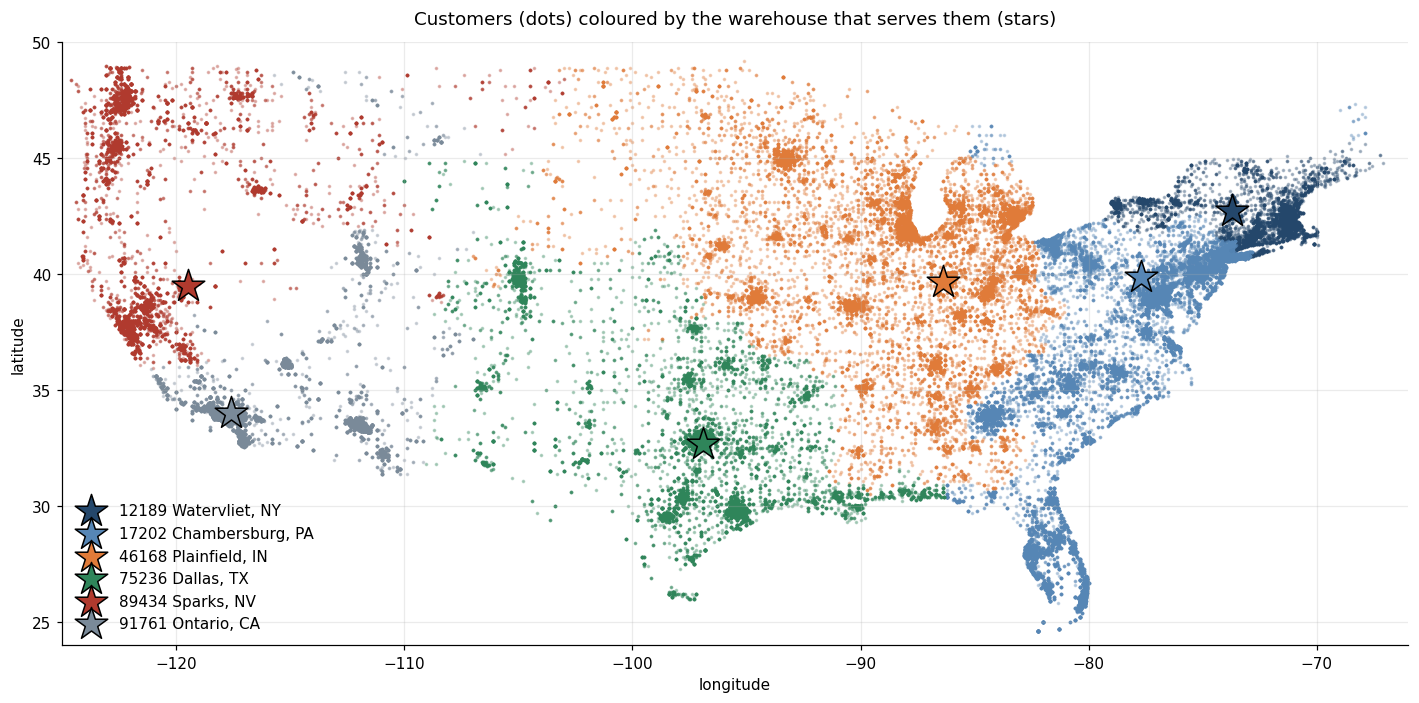

In [ ]:
WAREHOUSES = {   # ZIP -> (location, lat, long); coordinates are approximate
    12189: ("Watervliet, NY", 42.73, -73.72),
    17202: ("Chambersburg, PA", 39.90, -77.70),
    46168: ("Plainfield, IN", 39.68, -86.40),
    75236: ("Dallas, TX", 32.69, -96.92),
    89434: ("Sparks, NV", 39.50, -119.50),
    91761: ("Ontario, CA", 34.03, -117.59),
}

wh = orders.groupby("warehouse_zip")["count"].agg(orders="size", units="sum")
wh["share of units, %"] = (wh["units"] / wh["units"].sum() * 100).round(1)
wh.insert(0, "location", [WAREHOUSES[z][0] if z in WAREHOUSES else "no warehouse: Hawaii, Alaska, Puerto Rico" for z in wh.index])
display(wh)

colors = ["#24476B", "#5686B5", "#E07B39", "#2F855A", "#B03A2E", "#7A8A99"]
fig, ax = plt.subplots(figsize=(13, 6.5))
for (z, (name, lat, lon)), color in zip(WAREHOUSES.items(), colors):
    customers = orders[orders["warehouse_zip"] == z].dropna(subset=["lat"])
    ax.scatter(customers["long"], customers["lat"], s=2, alpha=0.3, color=color)
    ax.scatter(lon, lat, marker="*", s=500, color=color, edgecolor="black", zorder=5, label=f"{z} {name}")
ax.set_xlim(-125, -66)
ax.set_ylim(24, 50)
ax.set_xlabel("longitude")
ax.set_ylabel("latitude")
ax.set_title("Customers (dots) coloured by the warehouse that serves them (stars)", pad=12)
ax.legend(frameon=False, loc="lower left")
plt.tight_layout()
plt.show()

Шість складів Amazon ділять країну на зони: кожен обслуговує покупців свого регіону. Найбільші склади — Пенсильванія (28% штук) та Індіана (23%), найменший — Нью-Йорк (6,5%). `99999` не склад: це покупці на Гаваях, Алясці та в Пуерто-Рико (менше 2%).

Для задачі важливо, що частки складів майже не змінюються з часом, тож попит кожного складу можна рахувати як «загальний прогноз × частка складу».

## 4.2 Formulation of the optimisation problem

**Ситуація.** Продавець сам відправляє товар на склади Amazon і платить за доставку на склад та за зберігання там. До покупця товар везе Amazon за фіксовану плату за кожну штуку. Ця плата не залежить від того, з якого складу їде товар, тому на рішення вона не впливає й у цільову функцію не входить.

```
постачальник  ──(продавець платить, їде L днів)──►  6 складів Amazon  ──(доставляє Amazon)──►  покупці свого регіону
```

**Що вирішуємо (змінні рішення).**
$x_{w,t}$ — скільки штук відправити на склад $w$ у момент $t$ (наприклад, раз на 2 тижні).

**Що мінімізуємо (цільова функція).** Сумарні витрати на зберігання і доставку на склади:

$$
\min_{x} \; \sum_{t}\sum_{w} \Big( \underbrace{h \cdot I_{w,t}}_{\text{зберігання}} \;+\; \underbrace{c_w \cdot x_{w,t}}_{\text{доставка на склад}} \Big)
$$

**Обмеження.**

1. Баланс запасу на складі: що було + що приїхало − що продали
$$I_{w,t} = I_{w,t-1} + x_{w,\,t-L} - D_{w,t}$$
2. Прогнозований попит має бути покритий, тобто запас не може бути від'ємним (інакше найдешевше нічого не відправляти):
$$I_{w,t} \ge 0$$
3. Місце на складі та невід'ємні партії:
$$I_{w,t} \le \text{cap}_w, \qquad x_{w,t} \ge 0$$

**Звідки береться попит $D_{w,t}$** — з прогнозу:

$$
D_{w,t} \;=\; \underbrace{\text{прогноз замовлень}_t}_{\text{розділ 3}} \;\times\; \underbrace{\text{штук на замовлення}}_{\text{orders, count}} \;\times\; \underbrace{\text{частка складу } w}_{\text{orders, 4.1}}
$$

Тут прогноз вважається точним. Насправді він помиляється в середньому на ≈ 38% (розділ 3), тому наступний крок — додати страховий запас: вимагати, щоб попит був покритий із заданою ймовірністю (рівень сервісу, наприклад 95%).

## 4.3 What is missing

| Елемент задачі | Позначення | Чи є в даних |
|---|---|---|
| Прогноз попиту (замовлення) | $D_t$ | ✅ розділ 3 |
| Штук на замовлення | — | ✅ orders, `count` (змінюється з ≈ 2 до ≈ 1) |
| Частки складів | — | ✅ orders, `warehouse_zip` |
| Скільки товару зараз на кожному складі | $I_{w,0}$ | ❌ є лише сумарний FBA, нормалізований від 0 до 1, без розбивки по складах і без штук |
| Вартість зберігання | $h$ | ❌ |
| Вартість доставки на склад | $c_w$ | ❌ немає тарифів і не відомо, де постачальник (координати в даних — це покупці та склади) |
| Час поставки | $L$ | ❌ |
| Місткість складу | $\text{cap}_w$ | ❌ |
| Справжній попит у дні без товару | — | ❌ у такі дні видно продажі, а не попит, тому прогноз занижує потребу |
| Діапазон помилки прогнозу (для страхового запасу) | — | ⚠️ можна оцінити з бектесту (розділ 2–3), але моделі зараз дають лише точковий прогноз |

**Висновок.** Задачу сформулювати можна: попит і його розподіл по складах дані дають. Але вартість зберігання і доставки на склад, час поставки, місткість і поточний запас по складах треба отримати від бізнесу або задати як припущення. Що робити далі залежно від того, чи вдасться знайти ці параметри, описано в розділі 5.

# 5. Conclusions and next steps

### Висновки

**Дані**
1. `target` — це **кількість замовлень за день**, а не штук: він збігається з кількістю рядків `orders` (кореляція 0,999). Штук у замовленні з часом поменшало: з ≈ 2 до ≈ 1.
2. Товар пройшов повний життєвий цикл: запуск у жовтні 2017, кінець продажів у січні 2020. Для моделювання взято стабільне вікно **01.11.2017 – 20.12.2019 (780 днів)**.
3. Головний чинник продажів — **наявність товару на складі Amazon (FBA)**. FBA порожній у 41% днів, і 85% провалів продажів припадає саме на такі дні. Тому в ці дні ми бачимо продажі, а не справжній попит.

**Властивості ряду**

4. Ряд з **сильною інерцією і трендом** (сила тренду 0,86): продажі 2019 року вдвічі нижчі, ніж у 2018.
5. **Тижнева сезонність слабка, але стабільна**: понеділок +12%, субота −12%. **Річна сезонність нестійка**, бо двох років замало, а її форма залежить від наявності товару.
6. Розкид росте разом з рівнем, тому для ETS і ARIMA використано log(1 + y).

**Валідація**

7. Бектест rolling-origin: 35 фолдів, горизонт 28 днів, з purging. Витоки (перемішана крос-валідація, `orders` того самого дня) роблять помилку в **3–6 разів меншою, ніж вона є насправді**.

**Моделі**

8. Найкраща модель — **Holt–Winters на log(1 + y)**: MAE 29,8 замовлення на день, **на 5,6% краще за наївний прогноз «як учора»** (31,6). SARIMA, Random Forest і LightGBM наївний прогноз помітно не перевершують.
9. Помилка висока: **≈ 38% від рівня** за день і **35–39% для суми за 28 днів**. Причина — різкі зміни рівня (порожній склад, акції), про які на момент прогнозу нічого не відомо.

**Оптимізація**

10. Задачу поповнення запасів по 6 складах **сформулювати можна**: попит дає прогноз, а частки складів стабільні й відомі з `orders`. **Розв'язати її з реальними числами поки не можна**: немає витрат на зберігання й доставку, часу поставки, місткості складів і запасу по складах у штуках.

### Наступні кроки

**1. Покращити прогноз**
- врахувати дні без товару на FBA: у них продажі нижчі за справжній попит;
- спробувати екзогенні фактори: температура в регіонах, Google Trends, дати Prime Day і Black Friday;
- перевести прогноз у штуки: замовлення × штук на замовлення.

**2. Спробувати знайти параметри для оптимізації** у відкритих джерелах: тарифи Amazon FBA на зберігання ($h$), вартість доставки на склади ($c_w$), час поставки ($L$), ліміти місткості ($\text{cap}_w$).

- **Якщо вдалося** → зробити інтервальний прогноз (щоб знати, скільки тримати страхового запасу) → розв'язати задачу розподілу запасу по складах → перевірити на бектесті.
- **Якщо ні** → розв'язати задачу для кількох сценаріїв припущених параметрів (низькі / базові / високі витрати) і показати, як від них змінюється рішення.